# 17 — Hình và bảng cho báo cáo (GĐ1–GĐ12, máy local)

**Mục đích**

Dựng lại toàn bộ hình và bảng kết quả của các giai đoạn đã xong theo một định dạng thống nhất để đưa vào khóa luận: hình PNG 300 dpi
và bảng Word kẻ ô theo đúng quy ước của bản thảo (Times New Roman, dòng tiêu đề tô FCE4D6, chú thích bảng đặt trên, chú thích hình đặt
dưới, dạng "Bảng/Hình {x.y}: Tên. (Nguồn: …)" — số {x.y} tô vàng để đánh theo chương khi ghép vào luận văn).

**Không chạy lại thí nghiệm**

Mọi số đọc từ file kết quả đã lưu trong `05_experiments/`, `01_data/manifests/`, `01_data/interim/` và output của notebook 04. Notebook
không train, không gọi API và không mở lại Hold-out: số của GĐ10 lấy từ các bảng `gd10_*` đã lưu; phân bố nhãn và độ đồng thuận
của các tập khóa lấy từ kết quả đã báo cáo, không đọc lại file nhãn.

**File xuất**

Hình: `09_thesis/figures/fig_gd*.png`; tổng hợp hình kèm chú thích: `09_thesis/figures/Hinh_ket_qua_GD1-GD12.docx`; tổng hợp bảng:
`09_thesis/tables/Bang_ket_qua_GD1-GD12.docx`; danh mục hình và bảng: `09_thesis/figures/danh_muc_hinh_bang.csv`.

**Quy ước số**

Số viết theo kiểu Việt Nam (1.322; 0,539); "a ± b" là trung bình ± độ lệch chuẩn qua ba seed; CI là khoảng tin cậy 95% bootstrap.

In [1]:
import os, sys, json, shutil
import numpy as np, pandas as pd
ROOT = os.path.abspath('..')
sys.path.insert(0, os.path.join(ROOT, '02_src'))
from src.utils.seeds import set_seed
set_seed(42)
from IPython.display import Image, display
from src.utils.display import show as show_table
from src.reporting import figures as RF, load as L
from src.reporting.docx_report import Report, fmt_frame
from src.classification.final_eval import load_frozen
from src.reporting.style import pct, vn

RQ1 = os.path.join(ROOT, '05_experiments', 'rq1_classification')
LC = os.path.join(ROOT, '05_experiments', 'learning_curve')
RQ2 = os.path.join(ROOT, '05_experiments', 'rq2_topics')
FIG = os.path.join(ROOT, '09_thesis', 'figures')
TABD = os.path.join(ROOT, '09_thesis', 'tables')
os.makedirs(FIG, exist_ok=True); os.makedirs(TABD, exist_ok=True)
TAB, FIGS, CATALOG = Report(), Report(), []
STAGE = ['']


def section(name):
    STAGE[0] = name
    TAB.heading(name); FIGS.heading(name)


def add_table(df, title, note=None, highlight=(), widths=None, font_size=11):
    show_table(df, title)
    if note:
        print('Ghi chú:', note)
    TAB.table(df, title, note=note, highlight=highlight, widths_cm=widths, font_size=font_size)
    CATALOG.append({'loại': 'Bảng', 'giai đoạn': STAGE[0], 'tên': title, 'file': os.path.basename(TABD) + '/Bang_ket_qua_GD1-GD12.docx'})


def add_figure(path, title, width=16.0):
    display(Image(filename=path, width=880))
    print('Hình —', title)
    FIGS.figure(path, title, width_cm=width)
    CATALOG.append({'loại': 'Hình', 'giai đoạn': STAGE[0], 'tên': title, 'file': os.path.relpath(path, os.path.join(ROOT, '09_thesis'))})


def mean_of(s):
    return float(str(s).split('±')[0])


def rename(df, mapping):
    return df[list(mapping)].rename(columns=mapping)

## GĐ1–GĐ2 — Thu thập và làm sạch dữ liệu

**Nguồn**

Manifest mẻ cào chính thức (`gd1_crawl_manifest_T0_2026-10-06_r2.json`) và hai file interim đã ẩn danh hóa. Số review ngoài cửa sổ
12 tháng = số cào được − số còn trong cửa sổ (clean + dropped).

Ứng dụng,Cách cào,Ngày cào,Cào được,Ngoài cửa sổ 12 tháng,Loại (không có chữ cái),Đưa vào nghiên cứu,Thiếu app_version
Shopee,Từng mức sao 1★–5★ rồi gộp,07/10/2026,57.200,831,319,56.050,"26,3%"
Lazada,Mới nhất (Sort.NEWEST),07/10/2026,3.600,94,12,3.494,"34,2%"


Ghi chú: Cửa sổ 12 tháng: 06/10/2025–06/10/2026 (giờ Việt Nam). Tỷ lệ thiếu app_version tính trên số review cào được.


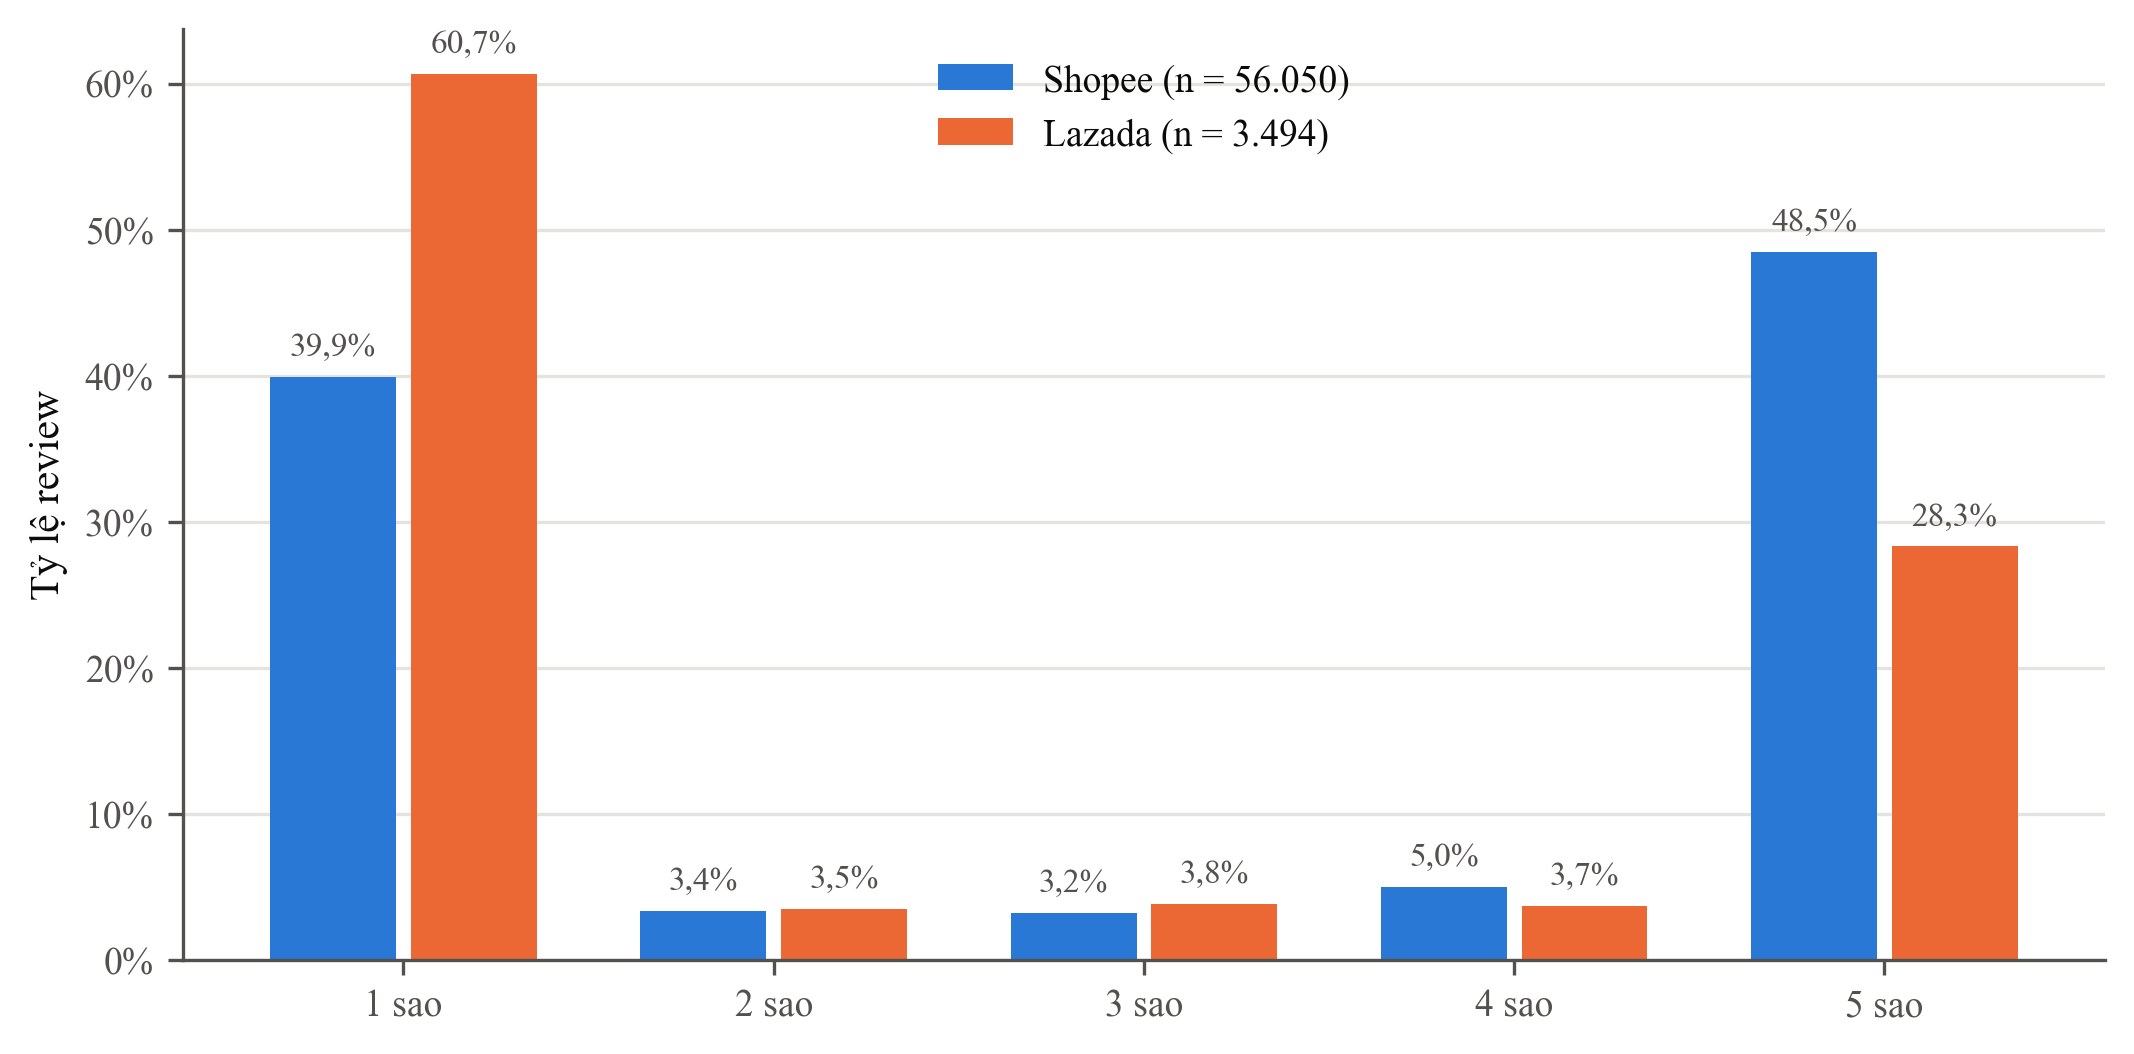

Hình — Phân bố số sao của review Shopee và Lazada sau làm sạch


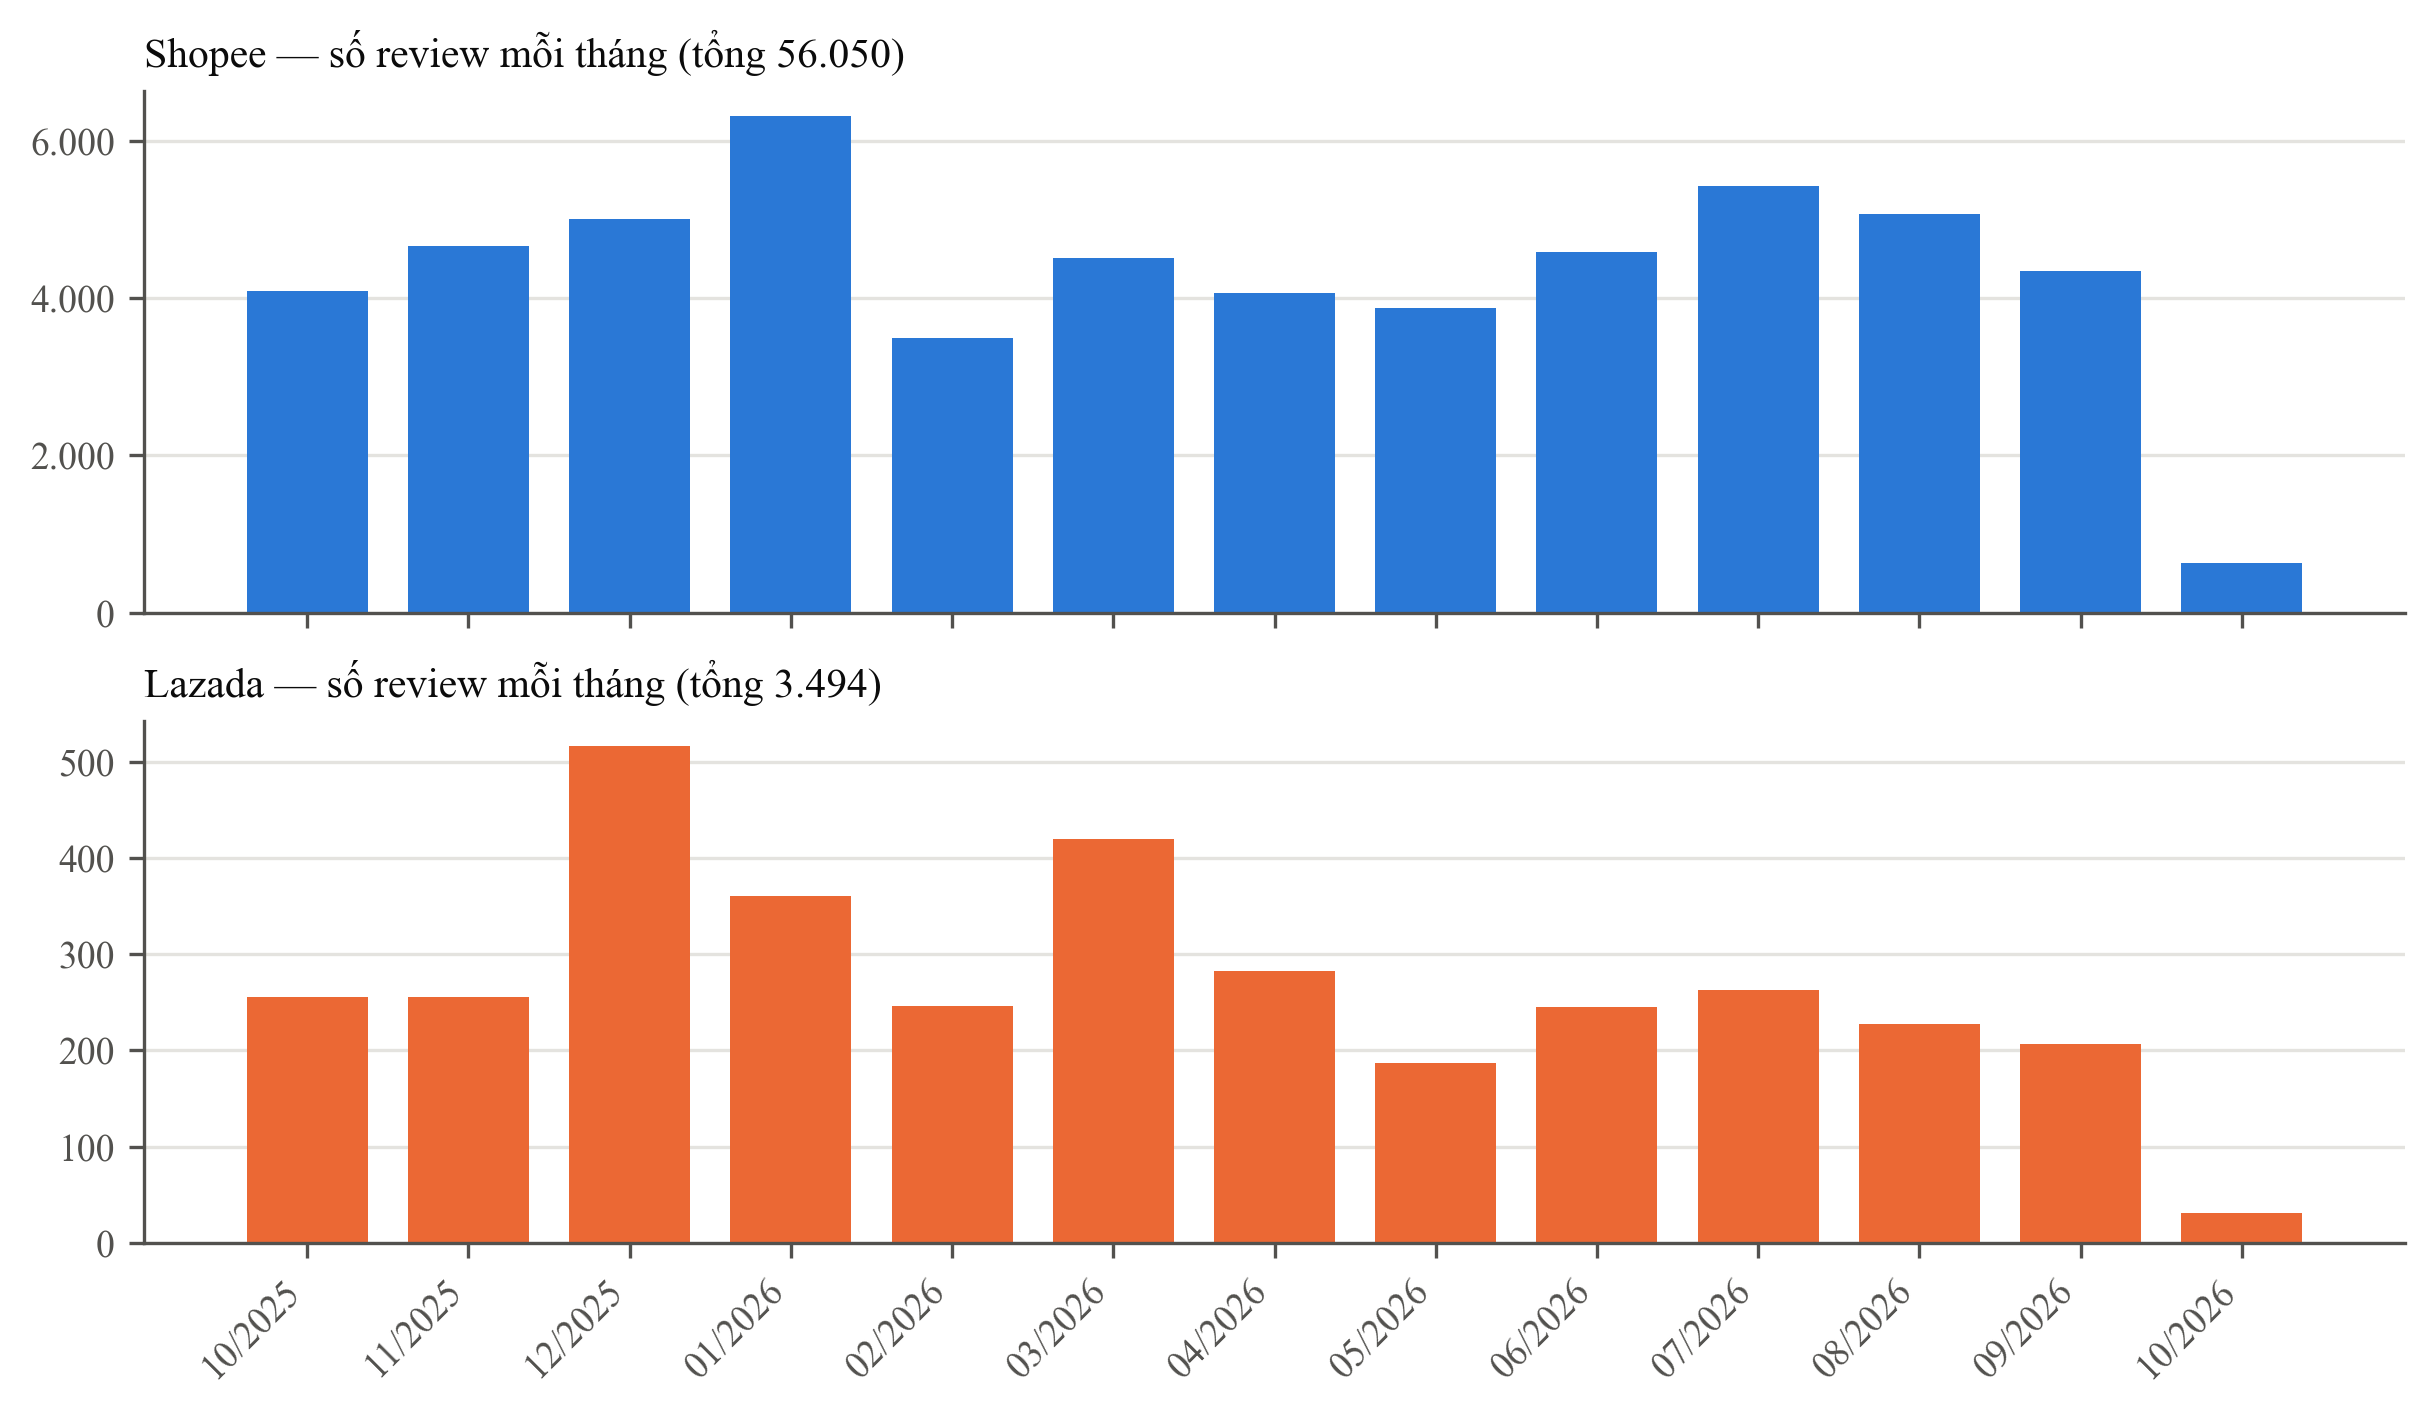

Hình — Số review mỗi tháng trong cửa sổ 12 tháng


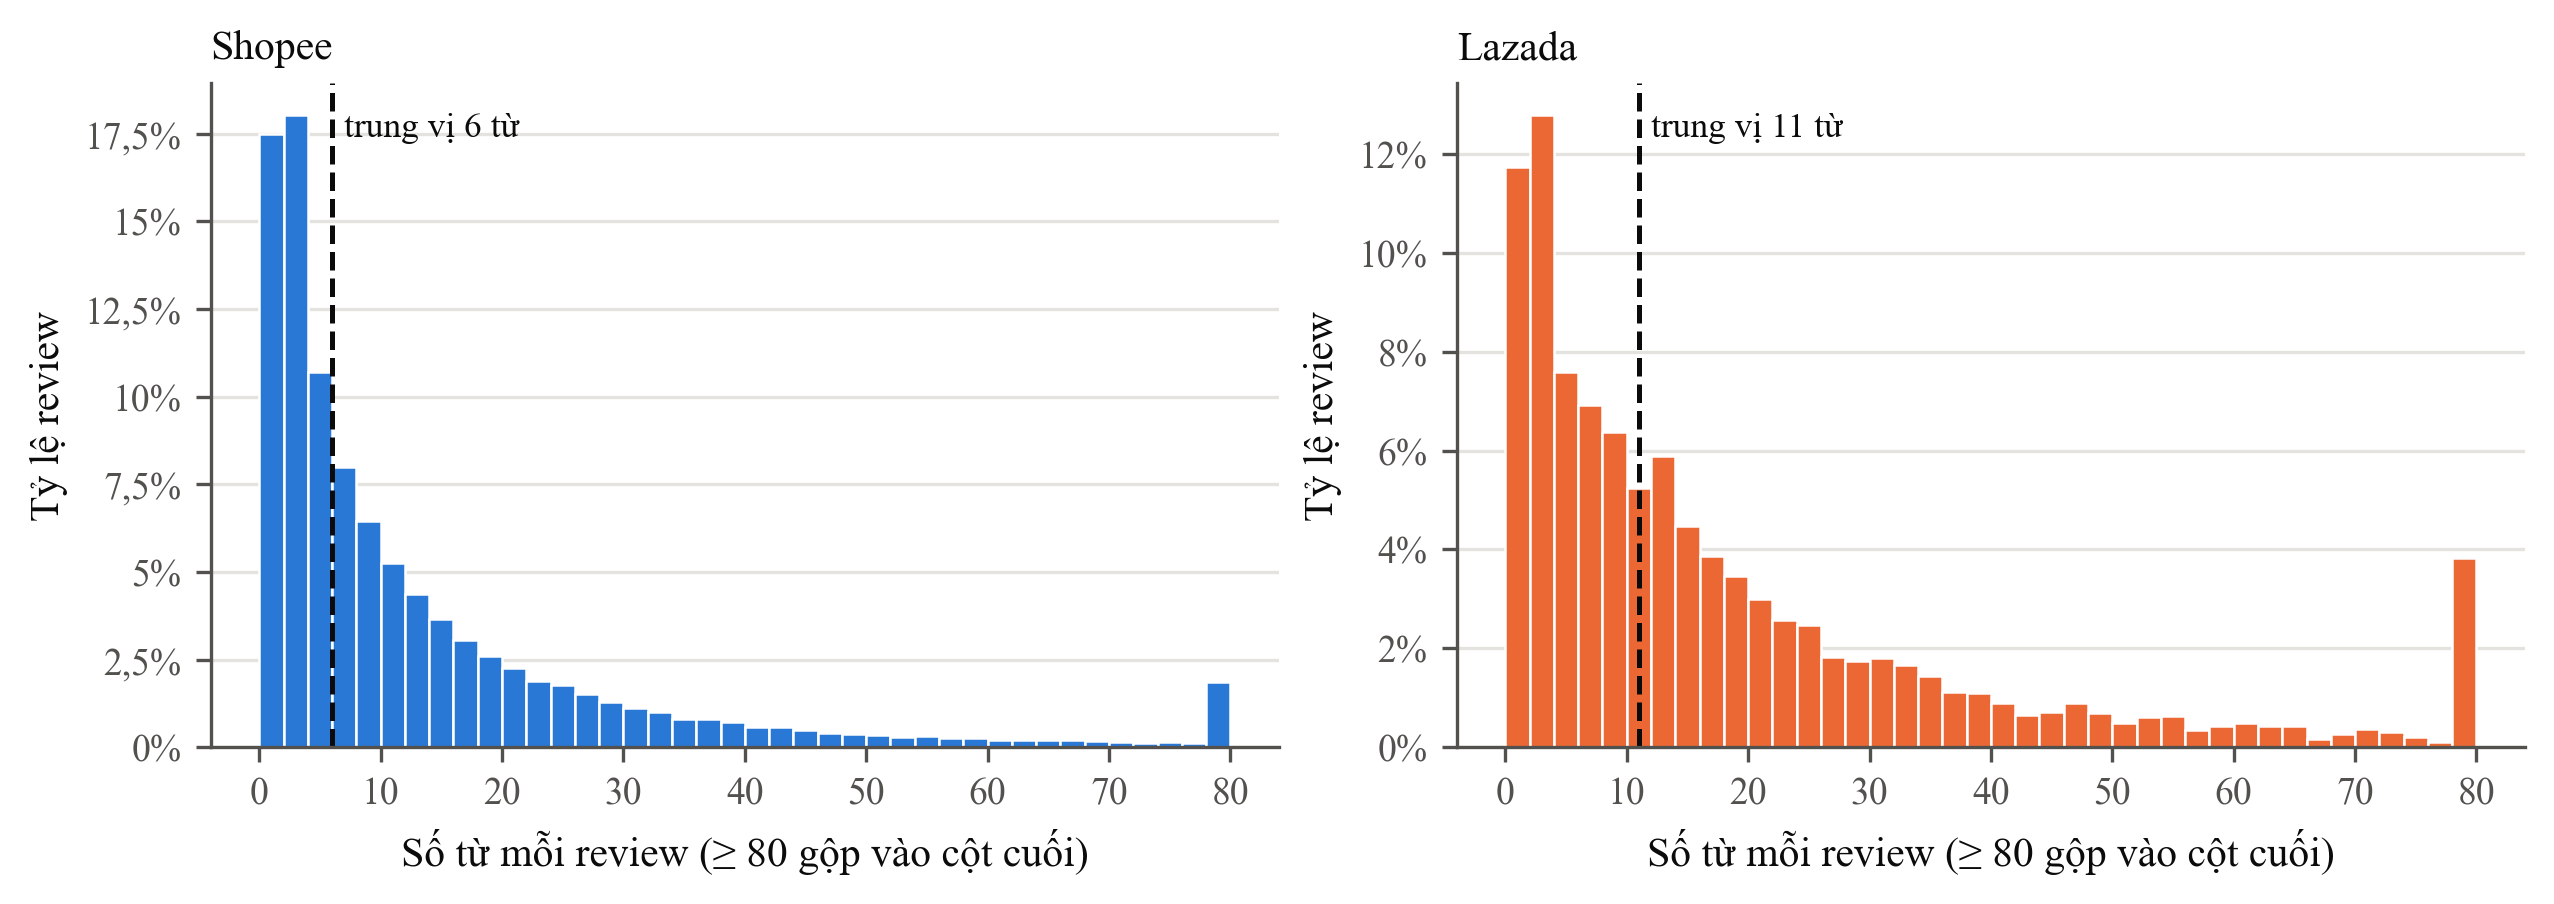

Hình — Phân bố độ dài review (số từ) của Shopee và Lazada


Ứng dụng,Số review,Trung vị (từ),Trung bình (từ),Review ≤ 2 từ,Review ≥ 50 từ
Shopee,56.050,6,"13,0","28,6%","4,8%"
Lazada,3.494,11,"18,8","19,3%","9,1%"


In [2]:
section('GĐ1–GĐ2 — Thu thập và làm sạch dữ liệu')
CR = L.crawl_summary(ROOT)
mode_vi = {'stratified_by_rating': 'Từng mức sao 1★–5★ rồi gộp', 'newest': 'Mới nhất (Sort.NEWEST)'}
t = pd.DataFrame({'Ứng dụng': CR['app'], 'Cách cào': CR['mode'].map(mode_vi),
                  'Ngày cào': pd.to_datetime(CR['ngày cào (UTC)']).dt.strftime('%d/%m/%Y'),
                  'Cào được': CR['cào được'], 'Ngoài cửa sổ 12 tháng': CR['ngoài cửa sổ 12 tháng'],
                  'Loại (không có chữ cái)': CR['loại (không có chữ cái)'], 'Đưa vào nghiên cứu': CR['đưa vào nghiên cứu'],
                  'Thiếu app_version': CR['thiếu app_version']})
add_table(fmt_frame(t, percent=['Thiếu app_version']),
          'Thống kê thu thập và làm sạch review Google Play của Shopee và Lazada',
          note='Cửa sổ 12 tháng: 06/10/2025–06/10/2026 (giờ Việt Nam). Tỷ lệ thiếu app_version tính trên số review cào được.',
          widths=[1.8, 2.9, 1.9, 1.6, 1.8, 1.9, 1.9, 1.8])

SH, LZ = L.load_interim(ROOT, 'shopee'), L.load_interim(ROOT, 'lazada')
add_figure(RF.fig_rating({'Shopee': SH['rating'], 'Lazada': LZ['rating']}, os.path.join(FIG, 'fig_gd01_rating.png')),
           'Phân bố số sao của review Shopee và Lazada sau làm sạch', width=14)
add_figure(RF.fig_monthly({'Shopee': SH['review_date'], 'Lazada': LZ['review_date']}, os.path.join(FIG, 'fig_gd01_monthly.png')),
           'Số review mỗi tháng trong cửa sổ 12 tháng', width=15)
add_figure(RF.fig_length({'Shopee': SH['words'], 'Lazada': LZ['words']}, os.path.join(FIG, 'fig_gd01_length.png')),
           'Phân bố độ dài review (số từ) của Shopee và Lazada', width=15)
desc = pd.DataFrame([{'Ứng dụng': app, 'Số review': len(d), 'Trung vị (từ)': float(d['words'].median()),
                      'Trung bình (từ)': float(d['words'].mean()), 'Review ≤ 2 từ': float((d['words'] <= 2).mean()),
                      'Review ≥ 50 từ': float((d['words'] >= 50).mean())} for app, d in (('Shopee', SH), ('Lazada', LZ))])
add_table(fmt_frame(desc, decimals={'Trung vị (từ)': 0, 'Trung bình (từ)': 1}, percent=['Review ≤ 2 từ', 'Review ≥ 50 từ']),
          'Thống kê độ dài review sau làm sạch', widths=[2.6, 2.4, 2.6, 2.8, 2.8, 2.8])

## GĐ3–GĐ4 — Chia tập, gán nhãn và độ đồng thuận

**Nguồn**

Kích thước tập từ `splits_manifest_T0_2026-10-06.json`; cách lấy mẫu và cách gán nhãn theo amendment v1.7–v1.8. Phân bố nhãn: Train và
Validation từ file gold; Hold-out từ bảng nhầm lẫn của GĐ10 (tổng theo hàng, đã báo cáo). Độ đồng thuận lấy từ output đã lưu của
notebook 04; κ của pilot (n = 400) theo amendment v1.7.

In [3]:
section('GĐ3–GĐ4 — Chia tập, gán nhãn và độ đồng thuận')
SP = L.splits(ROOT)
sets = pd.DataFrame([
    {'Tập': 'Train', 'Số review': SP['train'], 'Cách lấy mẫu': '180 calibration + 1.020 mới; phần mới làm giàu lớp hiếm bằng cụm từ gợi ý',
     'Gán nhãn': 'Một người + audit 15% hai người', 'Vai trò': 'Huấn luyện; ví dụ few-shot'},
    {'Tập': 'Validation', 'Số review': SP['validation'], 'Cách lấy mẫu': 'Ngẫu nhiên; cân lại FEATURE (amendment v1.8)',
     'Gán nhãn': 'Hai người', 'Vai trò': 'Chọn cấu hình, ngưỡng, prompt'},
    {'Tập': 'Hold-out', 'Số review': SP['holdout'], 'Cách lấy mẫu': 'Ngẫu nhiên thuần (400 pilot + 600)',
     'Gán nhãn': 'Hai người', 'Vai trò': 'Đánh giá cuối, mở một lần (khóa)'},
    {'Tập': 'Focused FEATURE/UX', 'Số review': SP['focused'], 'Cách lấy mẫu': 'Theo cụm từ gợi ý FEATURE/UX',
     'Gán nhãn': 'Hai người', 'Vai trò': 'Đo riêng lớp hiếm, báo cáo tách (khóa)'},
    {'Tập': 'Lazada external test', 'Số review': SP['lazada_external_test'], 'Cách lấy mẫu': 'Ngẫu nhiên thuần trên Lazada',
     'Gán nhãn': 'Hai người', 'Vai trò': 'Kiểm tra khái quát sang app khác (khóa)'}])
add_table(fmt_frame(sets), 'Các tập dữ liệu có nhãn và vai trò trong nghiên cứu', widths=[2.6, 1.6, 5.0, 3.0, 3.8])

LD = L.label_distribution(ROOT)
ld = pd.DataFrame({'Tập': LD.index})
for c in LD.columns:
    ld[c] = [f"{fmt_frame(pd.DataFrame({'v': [int(v)]}))['v'][0]} ({fmt_frame(pd.DataFrame({'p': [v / LD.loc[i].sum()]}), percent=['p'])['p'][0]})"
             for i, v in LD[c].items()]
ld['Tổng'] = [fmt_frame(pd.DataFrame({'v': [int(LD.loc[i].sum())]}))['v'][0] for i in LD.index]
add_table(ld, 'Phân bố nhãn bốn lớp trên Train, Validation và Hold-out',
          note='Train được làm giàu lớp hiếm và Validation đã cân lại FEATURE, nên chỉ Hold-out phản ánh phân bố tự nhiên.',
          widths=[2.6, 2.6, 2.6, 2.6, 3.0, 2.0])

AG = L.agreement_from_nb04(os.path.join(ROOT, 'notebooks', '04_annotation_agreement.ipynb'))
names = {'calibration batch1': 'Calibration đợt 1', 'calibration batch2': 'Calibration đợt 2 (cổng κ)',
         'calibration FEATURE/UX (thảo luận)': 'Calibration FEATURE/UX (thảo luận)', 'holdout_extra_600': 'Hold-out (600 review mới)',
         'validation': 'Validation', 'focused_feature_ux': 'Focused FEATURE/UX', 'lazada': 'Lazada external test',
         'train_audit': 'Train (audit 15%)'}
AG['tập'] = AG['tập'].map(names)
AG = pd.concat([AG, pd.DataFrame([{'tập': 'Pilot Hold-out (400 review)', 'n': 400, 'κ 4 lớp': 0.830}])], ignore_index=True)
AG['% đồng thuận'] = AG['% đồng thuận'] / 100
ag = rename(AG, {'tập': 'Tập', 'n': 'n', '% đồng thuận': 'Đồng thuận', 'κ 4 lớp': 'κ 4 lớp', 'κ act–OTHER': 'κ ACTIONABLE–OTHER',
                 'κ FEATURE–UX': 'κ FEATURE–UX', 'n FEATURE–UX': 'n FEATURE–UX'})
add_table(fmt_frame(ag, percent=['Đồng thuận'], integer=['n', 'n FEATURE–UX']),
          'Độ đồng thuận giữa hai người gán nhãn (Cohen κ)',
          note='Cổng chất lượng: κ 4 lớp ≥ 0,6. κ FEATURE–UX tính trên các review cả hai người cùng chọn FEATURE hoặc UX. '
               'Dòng pilot: κ theo amendment v1.7 (đo trước khi khóa Hold-out).',
          widths=[4.6, 1.2, 1.9, 1.7, 2.4, 2.1, 2.1])

Tập,Số review,Cách lấy mẫu,Gán nhãn,Vai trò
Train,1.200,180 calibration + 1.020 mới; phần mới làm giàu lớp hiếm bằng cụm từ gợi ý,Một người + audit 15% hai người,Huấn luyện; ví dụ few-shot
Validation,350,Ngẫu nhiên; cân lại FEATURE (amendment v1.8),Hai người,"Chọn cấu hình, ngưỡng, prompt"
Hold-out,1.000,Ngẫu nhiên thuần (400 pilot + 600),Hai người,"Đánh giá cuối, mở một lần (khóa)"
Focused FEATURE/UX,150,Theo cụm từ gợi ý FEATURE/UX,Hai người,"Đo riêng lớp hiếm, báo cáo tách (khóa)"
Lazada external test,500,Ngẫu nhiên thuần trên Lazada,Hai người,Kiểm tra khái quát sang app khác (khóa)


Tập,BUG,FEATURE,UX,OTHER,Tổng
Train,"75 (6,2%)","129 (10,8%)","132 (11,0%)","864 (72,0%)",1.200
Validation,"27 (7,7%)","22 (6,3%)","22 (6,3%)","279 (79,7%)",350
Hold-out,"89 (8,9%)","24 (2,4%)","70 (7,0%)","817 (81,7%)",1.000


Ghi chú: Train được làm giàu lớp hiếm và Validation đã cân lại FEATURE, nên chỉ Hold-out phản ánh phân bố tự nhiên.


Tập,n,Đồng thuận,κ 4 lớp,κ ACTIONABLE–OTHER,κ FEATURE–UX,n FEATURE–UX
Calibration đợt 1,75,"88,0%","0,671","0,728","0,000",2
Calibration đợt 2 (cổng κ),75,"89,3%","0,785","0,849","1,000",6
Calibration FEATURE/UX (thảo luận),30,"86,7%","0,814",,"0,851",14
Hold-out (600 review mới),600,"91,8%","0,752","0,752","0,946",47
Validation,350,"94,6%","0,816","0,846","0,865",25
Focused FEATURE/UX,150,"74,0%","0,619","0,545","0,902",75
Lazada external test,500,"92,2%","0,745","0,777","0,755",34
Train (audit 15%),153,"86,3%","0,741","0,743","0,893",40
Pilot Hold-out (400 review),400,,"0,830",,,


Ghi chú: Cổng chất lượng: κ 4 lớp ≥ 0,6. κ FEATURE–UX tính trên các review cả hai người cùng chọn FEATURE hoặc UX. Dòng pilot: κ theo amendment v1.7 (đo trước khi khóa Hold-out).


## GĐ5 — Learning curve

**Nguồn**

`learning_curve_summary.csv` (ViSoBERT, ba seed) và `learning_curve_bilstm_summary.csv` (Bi-LSTM, một seed), cấu hình mặc định, đánh
giá trên Validation; số ViSoBERT là số sau khi sửa lỗi tokenizer (amendment v1.9).

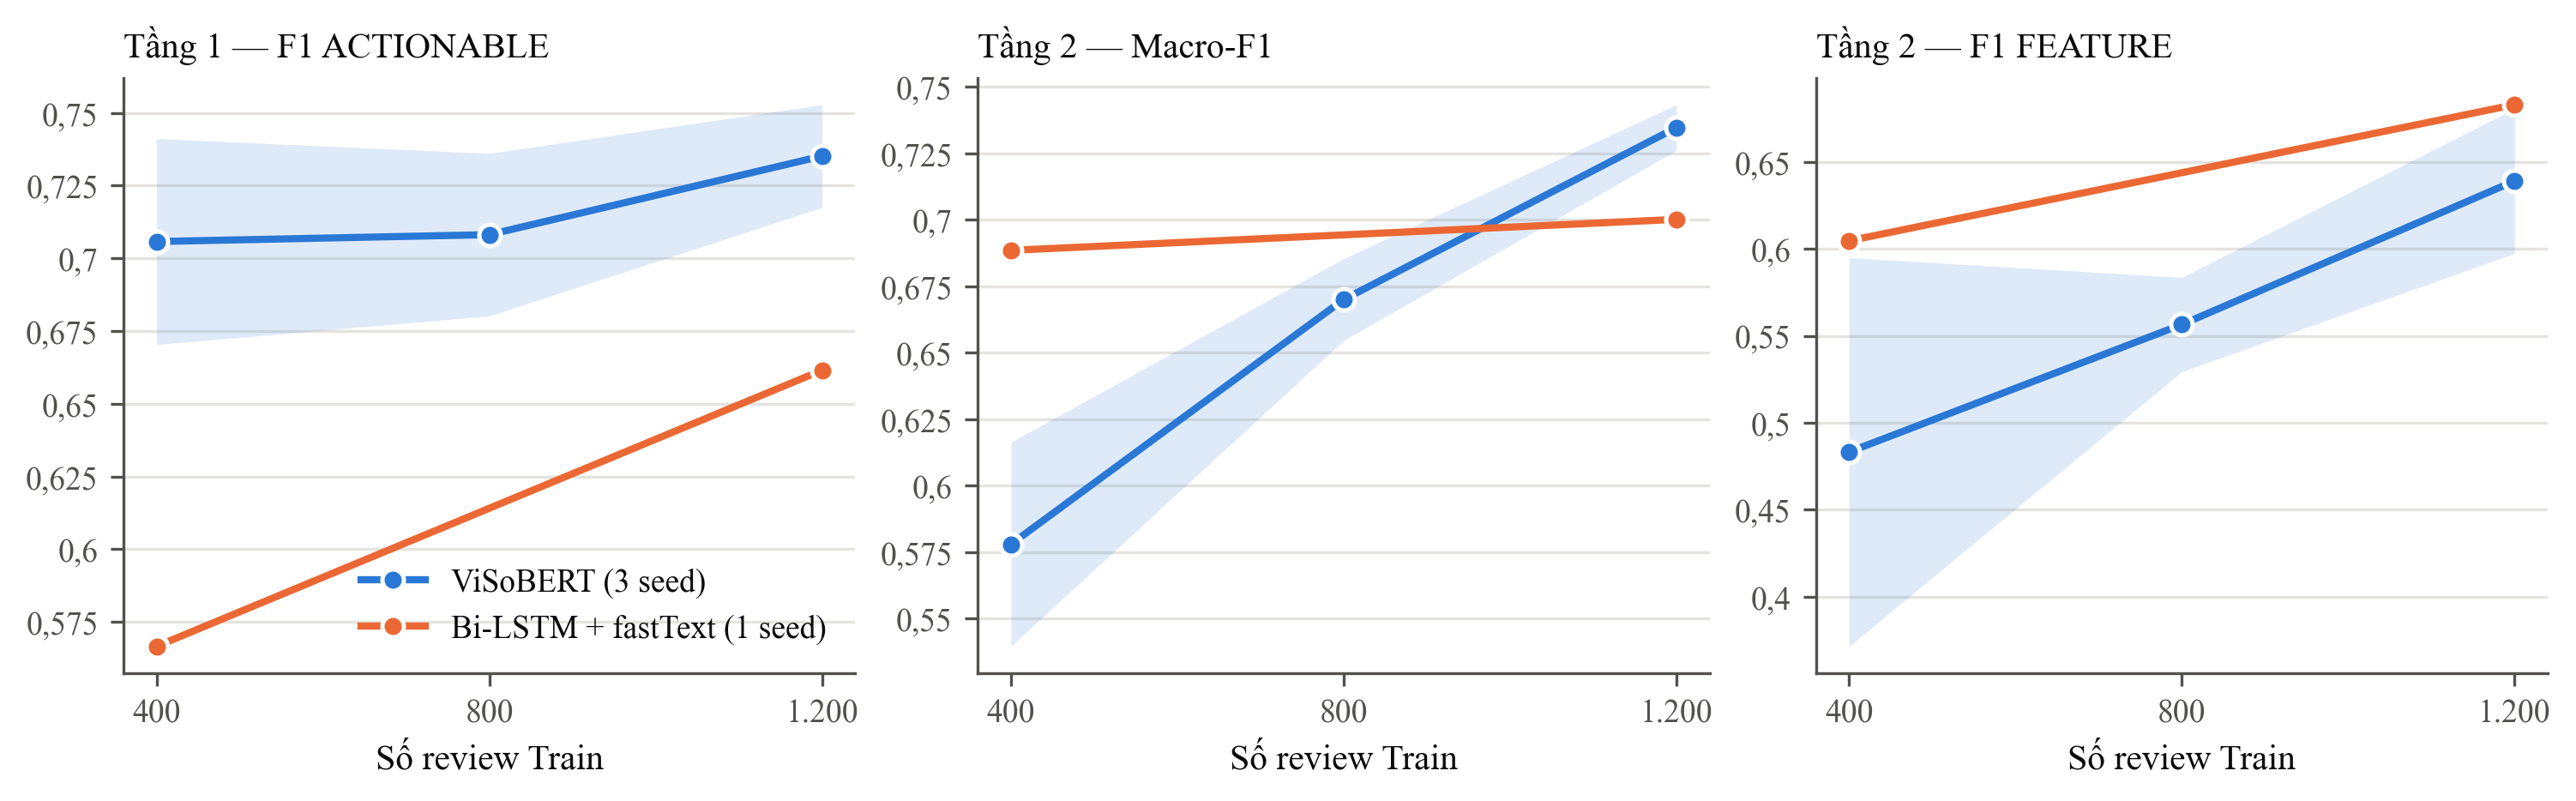

Hình — Learning curve theo số review Train trên Validation (dải màu: ± 1 độ lệch chuẩn qua ba seed)


Chiến lược,Số review Train,Số seed,Tầng 1 F1 ACT,Tầng 1 Recall ACT,Tầng 2 Macro-F1,Tầng 2 F1 FEATURE
ViSoBERT,400,3,"0,706 ± 0,035","0,648 ± 0,037","0,578 ± 0,038","0,483 ± 0,112"
ViSoBERT,800,3,"0,708 ± 0,028","0,648 ± 0,014","0,670 ± 0,015","0,556 ± 0,027"
ViSoBERT,1.200,3,"0,735 ± 0,018","0,671 ± 0,022","0,735 ± 0,009","0,639 ± 0,042"
Bi-LSTM + fastText,400,1,"0,567","0,479","0,688","0,605"
Bi-LSTM + fastText,1.200,1,"0,662","0,606","0,700","0,683"


In [4]:
section('GĐ5 — Learning curve')
LCS = pd.concat([pd.read_csv(os.path.join(LC, 'learning_curve_summary.csv')),
                 pd.read_csv(os.path.join(LC, 'learning_curve_bilstm_summary.csv'))], ignore_index=True)
add_figure(RF.fig_learning_curve(LCS, [('tier1', 'f1_actionable', 'Tầng 1 — F1 ACTIONABLE'), ('tier2', 'macro_f1', 'Tầng 2 — Macro-F1'),
                                       ('tier2', 'f1_FEATURE', 'Tầng 2 — F1 FEATURE')], os.path.join(FIG, 'fig_gd05_learning_curve.png')),
           'Learning curve theo số review Train trên Validation (dải màu: ± 1 độ lệch chuẩn qua ba seed)')
keep = [('tier1', 'f1_actionable', 'Tầng 1 F1 ACT'), ('tier1', 'recall_actionable', 'Tầng 1 Recall ACT'),
        ('tier2', 'macro_f1', 'Tầng 2 Macro-F1'), ('tier2', 'f1_FEATURE', 'Tầng 2 F1 FEATURE')]
rows = []
for (strat, size), g in LCS.groupby(['strategy', 'size']):
    r = {'Chiến lược': {'visobert': 'ViSoBERT', 'bilstm': 'Bi-LSTM + fastText'}[strat], 'Số review Train': int(size),
         'Số seed': int(g['n_seeds'].max())}
    for tier, metric, label in keep:
        x = g[(g['tier'] == tier) & (g['metric'] == metric)]
        m, s = float(x['mean'].iloc[0]), float(x['std'].iloc[0])
        r[label] = f'{m:.3f} ± {s:.3f}' if r['Số seed'] > 1 else f'{m:.3f}'
    rows.append(r)
lct = pd.DataFrame(rows).sort_values(['Chiến lược', 'Số review Train'], ascending=[False, True])
add_table(fmt_frame(lct, pm=[l for *_, l in keep], integer=['Số review Train', 'Số seed']),
          'Kết quả learning curve trên Validation theo số review Train',
          widths=[3.0, 1.8, 1.3, 2.5, 2.5, 2.5, 2.5])

## GĐ6–GĐ9 — Kết quả trên Validation

**Nguồn**

Bảng kết quả và file quét ngưỡng của GĐ6 (tầng 1), GĐ7 (tầng 2), GĐ8 (LLM few-shot) và GĐ9 (baseline phẳng), cấu hình đã đóng băng ở
amendment v2.1. Số trên Validation lạc quan vì cấu hình được chọn trên chính tập này.

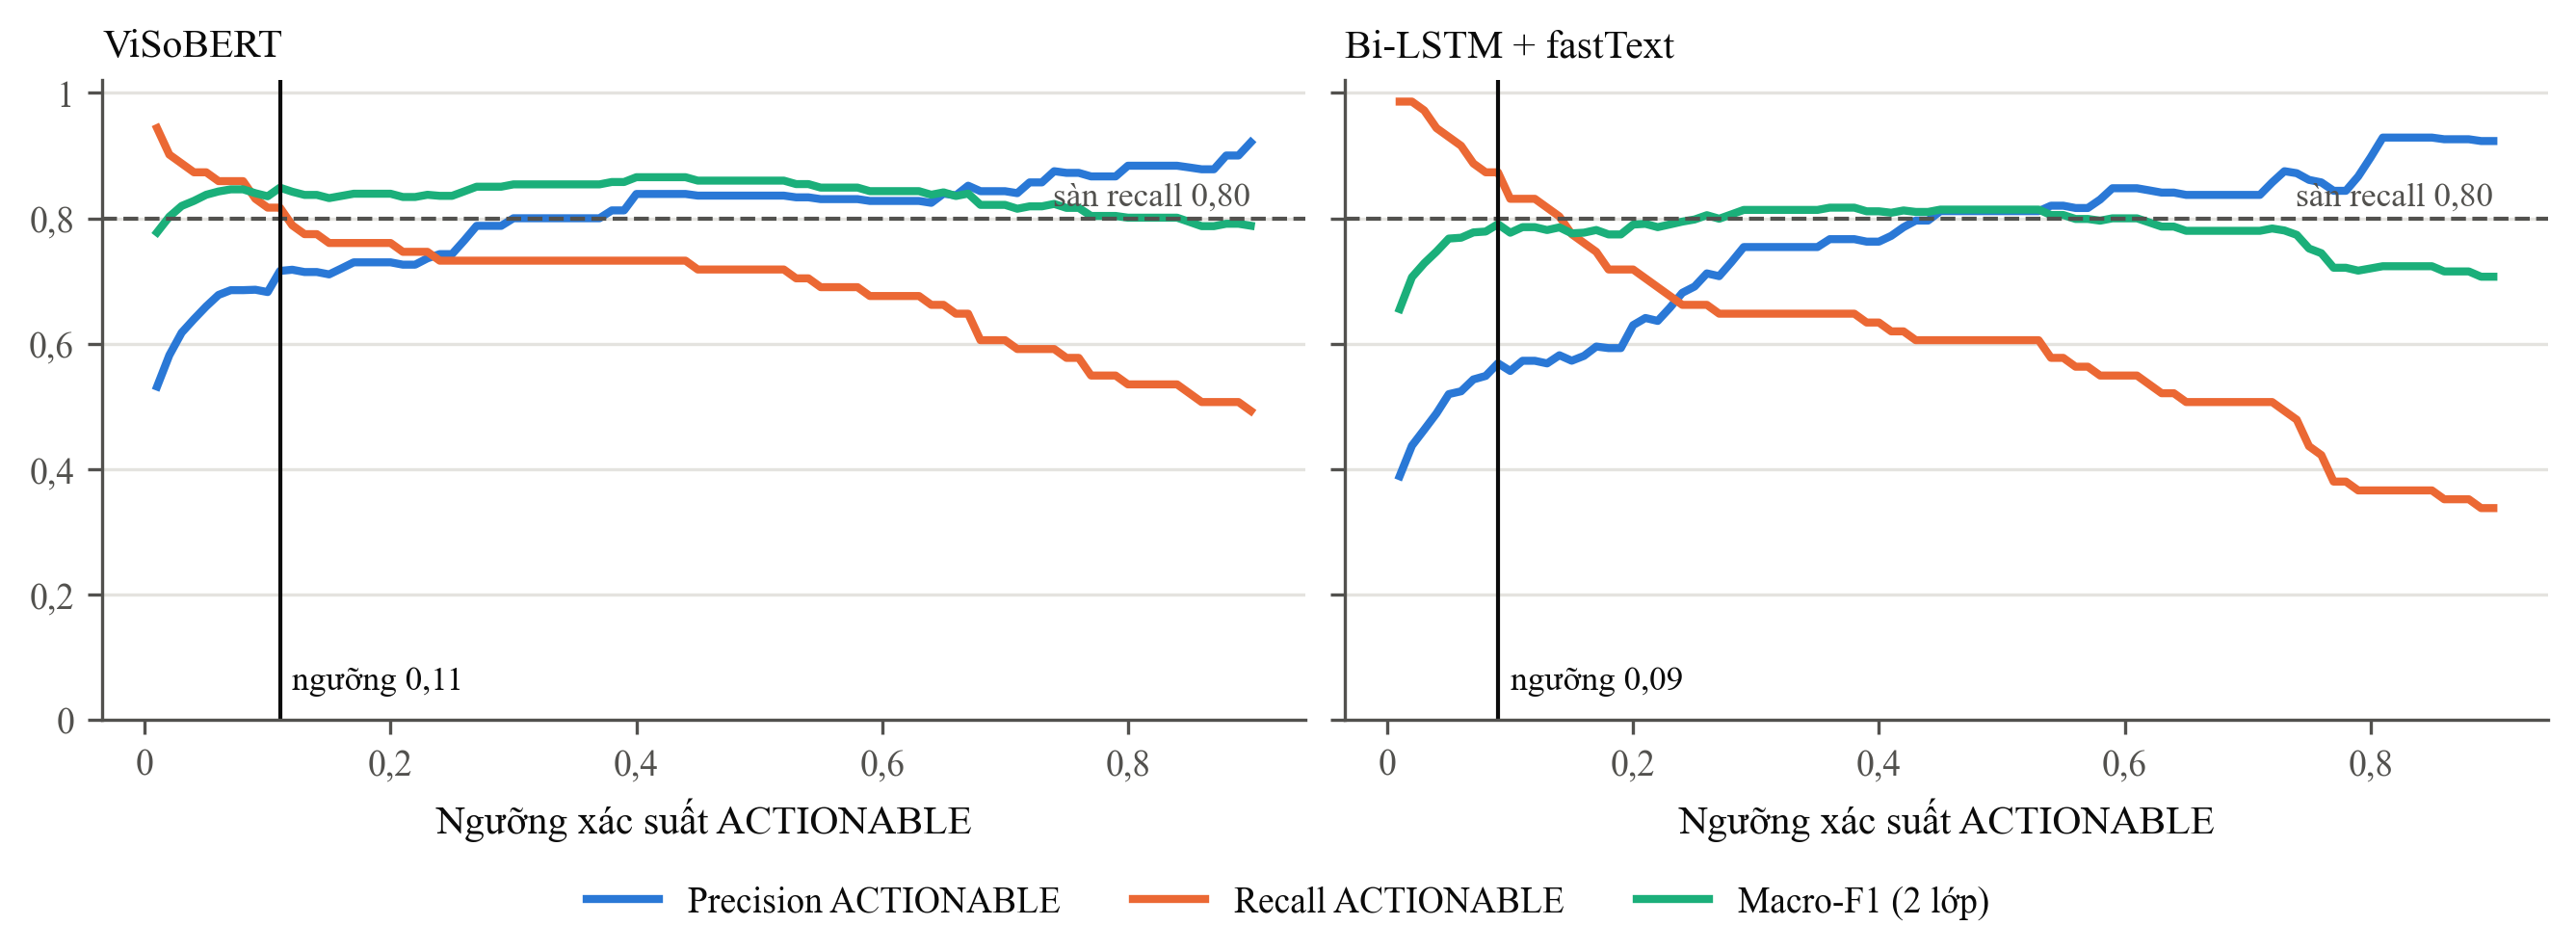

Hình — Precision, recall và Macro-F1 tầng 1 theo ngưỡng trên Validation (seed 42) và ngưỡng được chọn


Chiến lược,Cấu hình,Ngưỡng,Recall thấp nhất (3 seed),F1 ACT (%),Recall ACT (%),Precision ACT (%),Macro-F1 (%)
ViSoBERT,"epochs: 3, lr: 2e-05","0,11","0,789","76,5 ± 0,6","82,6 ± 4,3","71,6 ± 4,1","85,0 ± 0,6"
Bi-LSTM + fastText,"dropout: 0.5, hidden_size: 256, lr: 0.001","0,09","0,817","68,5 ± 4,2","87,8 ± 6,4","56,9 ± 8,3","78,6 ± 3,9"


Ghi chú: Ngưỡng chọn trên seed 42 theo luật recall ≥ 0,80 (amendment v2.0) rồi giữ nguyên cho hai seed còn lại.


Chiến lược,Cấu hình,Macro-F1 (%),F1 BUG (%),F1 FEATURE (%),F1 UX (%)
ViSoBERT,"epochs: 8, lr: 3e-05","75,6 ± 2,2","74,2 ± 2,6","73,1 ± 2,7","79,5 ± 2,7"
Bi-LSTM + fastText,"dropout: 0.5, epochs: 20, hidden_size: 128, lr: 0.002","72,0 ± 3,2","72,3 ± 3,2","63,5 ± 5,7","80,3 ± 1,3"


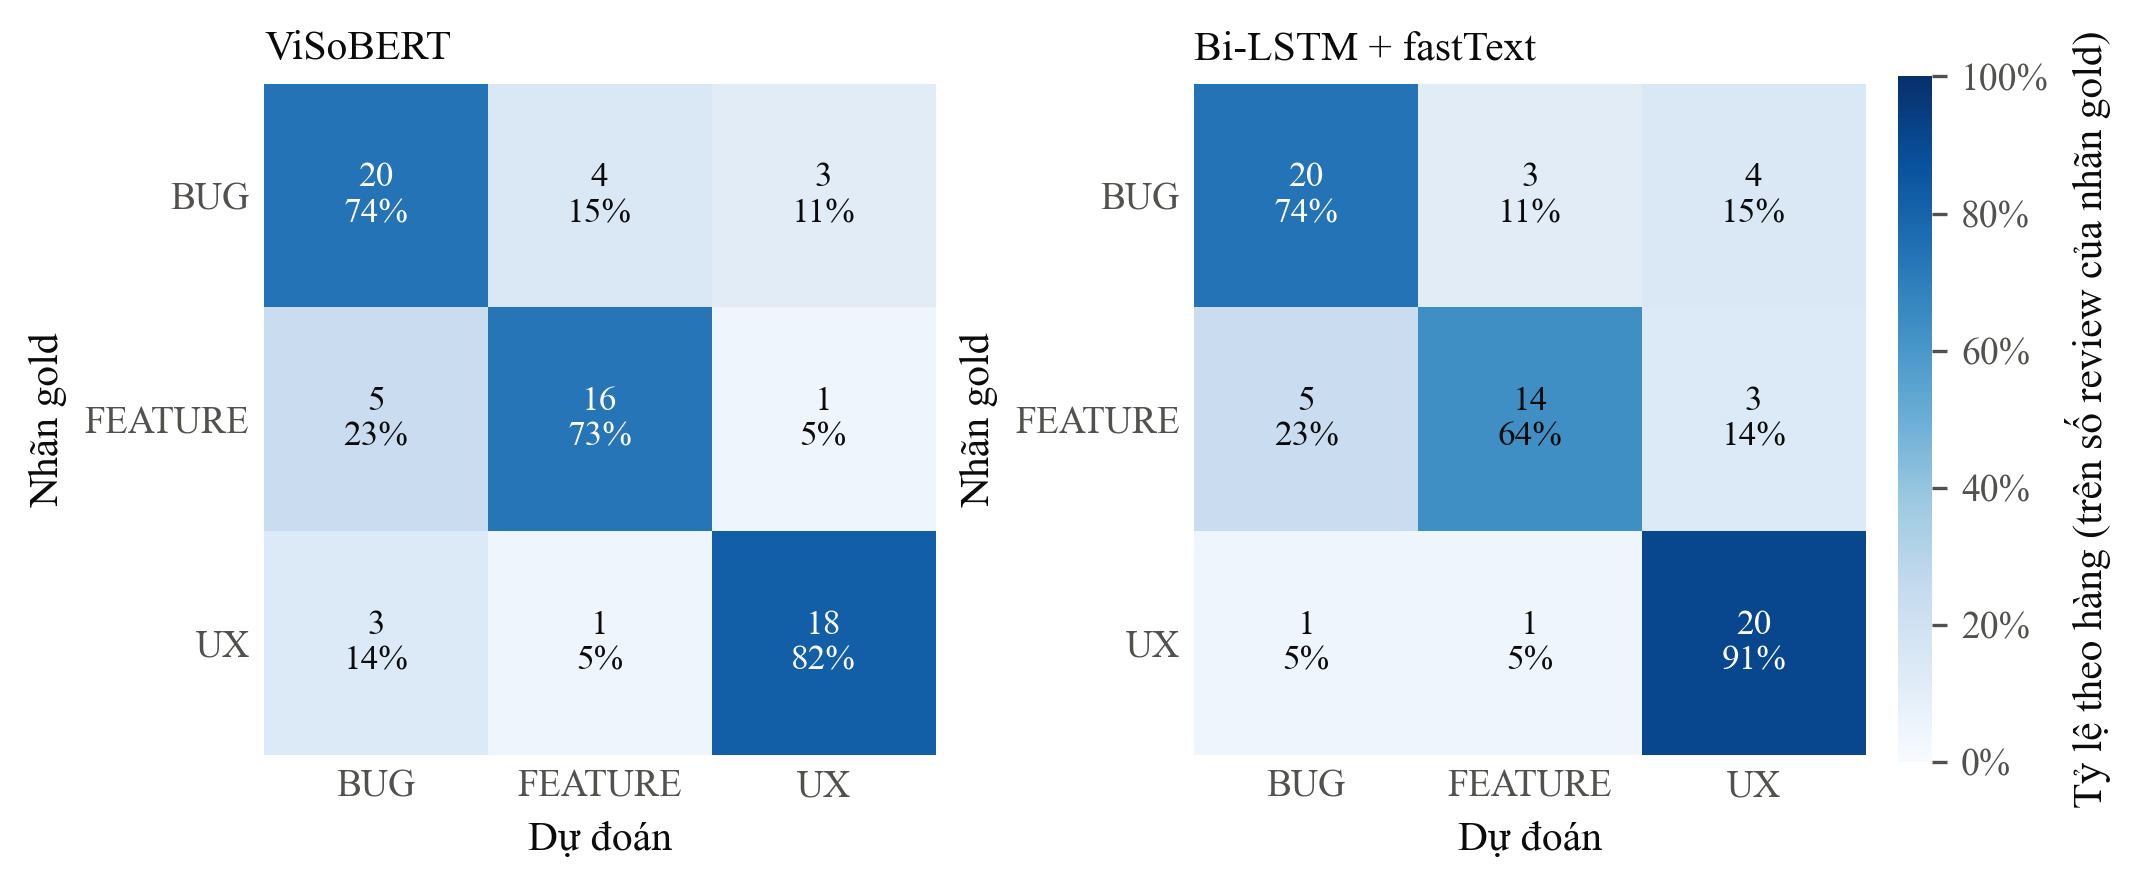

Hình — Ma trận nhầm lẫn tầng 2 trên Validation-actionable (seed 42; số review và tỷ lệ theo hàng)


Tầng,Chỉ số,Giá trị
Tầng 1,F1 ACTIONABLE,"82,7%"
Tầng 1,Recall ACTIONABLE,"87,3%"
Tầng 1,Precision ACTIONABLE,"78,5%"
Tầng 1,Macro-F1 (2 lớp),"89,0%"
Tầng 2,Macro-F1 (3 lớp),"79,9%"
Tầng 2,F1 BUG,"81,5%"
Tầng 2,F1 FEATURE,"73,2%"
Tầng 2,F1 UX,"85,1%"


Ghi chú: Một lần chạy, temperature 0. Tầng 2 đánh giá trên các review gold-actionable.


Bước,Số review,Token vào,Token ra,Chi phí (USD),Giây / 1.000 review,USD / 1.000 review
tầng 1 (mọi review),350,395.369,2.371,"0,0607","933,9","0,1735"
tầng 2 (actionable gold ∪ dự đoán),88,92.940,440,"0,0142","894,5","0,1614"


Cấu hình,Macro-F1 4 lớp (%),F1 BUG (%),F1 FEATURE (%),F1 UX (%),F1 OTHER (%)
Baseline phẳng ViSoBERT,"69,1 ± 2,0","50,7 ± 2,5","58,9 ± 7,0","72,7 ± 3,2","94,0 ± 0,5"
Cascade ViSoBERT,"68,8 ± 0,8","52,9 ± 3,3","56,3 ± 1,6","72,5 ± 4,2","93,4 ± 0,7"
"Chênh (cascade − baseline), điểm %","-0,3","+2,2","-2,6","-0,2","-0,6"


In [5]:
section('GĐ6–GĐ9 — Kết quả trên Validation')
FZ = load_frozen(ROOT)
SW = {'ViSoBERT': pd.read_csv(os.path.join(RQ1, 'tier1_visobert_threshold_sweep.csv')),
      'Bi-LSTM + fastText': pd.read_csv(os.path.join(RQ1, 'tier1_bilstm_threshold_sweep.csv'))}
CH = {'ViSoBERT': FZ['tier1']['visobert']['threshold'], 'Bi-LSTM + fastText': FZ['tier1']['bilstm']['threshold']}
add_figure(RF.fig_threshold(SW, CH, FZ['tier1']['threshold_rule']['min_recall'], os.path.join(FIG, 'fig_gd06_threshold.png')),
           'Precision, recall và Macro-F1 tầng 1 theo ngưỡng trên Validation (seed 42) và ngưỡng được chọn')

t1 = pd.read_csv(os.path.join(RQ1, 'tier1_validation_results.csv'))
t1['cấu hình'] = t1['cấu hình'].str.replace('"', '').str.replace('{', '').str.replace('}', '')
add_table(fmt_frame(rename(t1, {'strategy': 'Chiến lược', 'cấu hình': 'Cấu hình', 'ngưỡng': 'Ngưỡng',
                                'recall thấp nhất (3 seed)': 'Recall thấp nhất (3 seed)', 'f1_actionable': 'F1 ACT (%)',
                                'recall_actionable': 'Recall ACT (%)', 'precision_actionable': 'Precision ACT (%)',
                                'macro_f1': 'Macro-F1 (%)'}),
                    decimals={'Ngưỡng': 2, 'Recall thấp nhất (3 seed)': 3},
                    pm=['F1 ACT (%)', 'Recall ACT (%)', 'Precision ACT (%)', 'Macro-F1 (%)']),
          'Kết quả tầng 1 (ACTIONABLE / NOT_ACTIONABLE) trên Validation',
          note='Ngưỡng chọn trên seed 42 theo luật recall ≥ 0,80 (amendment v2.0) rồi giữ nguyên cho hai seed còn lại.',
          widths=[2.4, 3.4, 1.3, 1.8, 1.8, 1.8, 1.8, 1.7], font_size=10)

t2 = pd.read_csv(os.path.join(RQ1, 'tier2_validation_results.csv'))
t2['cấu hình'] = t2['cấu hình'].str.replace('"', '').str.replace('{', '').str.replace('}', '')
add_table(fmt_frame(rename(t2, {'strategy': 'Chiến lược', 'cấu hình': 'Cấu hình', 'macro_f1': 'Macro-F1 (%)', 'f1_BUG': 'F1 BUG (%)',
                                'f1_FEATURE': 'F1 FEATURE (%)', 'f1_UX': 'F1 UX (%)'}),
                    pm=['Macro-F1 (%)', 'F1 BUG (%)', 'F1 FEATURE (%)', 'F1 UX (%)']),
          'Kết quả tầng 2 (BUG / FEATURE / UX) trên phần actionable của Validation (n = 71)',
          widths=[2.6, 5.0, 2.1, 2.1, 2.1, 2.1], font_size=10)
CM2 = {'ViSoBERT': pd.read_csv(os.path.join(RQ1, 'tier2_visobert_confusion_seed42.csv'), index_col=0),
       'Bi-LSTM + fastText': pd.read_csv(os.path.join(RQ1, 'tier2_bilstm_confusion_seed42.csv'), index_col=0)}
add_figure(RF.fig_confusions(CM2, os.path.join(FIG, 'fig_gd07_confusion_val.png')),
           'Ma trận nhầm lẫn tầng 2 trên Validation-actionable (seed 42; số review và tỷ lệ theo hàng)', width=14)

LM = pd.read_csv(os.path.join(RQ1, 'llm_validation_metrics.csv')).set_index('tầng')
llm = pd.DataFrame([
    {'Tầng': 'Tầng 1', 'Chỉ số': 'F1 ACTIONABLE', 'Giá trị': LM.loc['tier1', 'f1_actionable']},
    {'Tầng': 'Tầng 1', 'Chỉ số': 'Recall ACTIONABLE', 'Giá trị': LM.loc['tier1', 'recall_actionable']},
    {'Tầng': 'Tầng 1', 'Chỉ số': 'Precision ACTIONABLE', 'Giá trị': LM.loc['tier1', 'precision_actionable']},
    {'Tầng': 'Tầng 1', 'Chỉ số': 'Macro-F1 (2 lớp)', 'Giá trị': LM.loc['tier1', 'macro_f1']},
    {'Tầng': 'Tầng 2', 'Chỉ số': 'Macro-F1 (3 lớp)', 'Giá trị': LM.loc['tier2', 'macro_f1']},
    {'Tầng': 'Tầng 2', 'Chỉ số': 'F1 BUG', 'Giá trị': LM.loc['tier2', 'f1_BUG']},
    {'Tầng': 'Tầng 2', 'Chỉ số': 'F1 FEATURE', 'Giá trị': LM.loc['tier2', 'f1_FEATURE']},
    {'Tầng': 'Tầng 2', 'Chỉ số': 'F1 UX', 'Giá trị': LM.loc['tier2', 'f1_UX']}])
add_table(fmt_frame(llm, percent=['Giá trị']), 'Kết quả LLM few-shot (gpt-4o-mini, prompt v1) trên Validation',
          note='Một lần chạy, temperature 0. Tầng 2 đánh giá trên các review gold-actionable.', widths=[3.0, 5.0, 3.0])
lc = pd.read_csv(os.path.join(RQ1, 'llm_costs.csv'))
add_table(fmt_frame(rename(lc, {'bước': 'Bước', 'n_review': 'Số review', 'token_vào': 'Token vào', 'token_ra': 'Token ra',
                                'chi_phí_usd': 'Chi phí (USD)', 'giây_/1000_review': 'Giây / 1.000 review',
                                'usd_/1000_review': 'USD / 1.000 review'}),
                    decimals={'Chi phí (USD)': 4, 'Giây / 1.000 review': 1, 'USD / 1.000 review': 4}),
          'Chi phí thực tế của LLM few-shot trên Validation', widths=[4.4, 1.6, 1.9, 1.6, 1.9, 2.3, 2.3], font_size=10)

cf = pd.read_csv(os.path.join(RQ1, 'cascade_vs_flat_validation.csv'))
cf = cf[cf['strategy'].notna()]
add_table(fmt_frame(rename(cf, {'strategy': 'Cấu hình', 'macro_f1': 'Macro-F1 4 lớp (%)', 'f1_BUG': 'F1 BUG (%)',
                                'f1_FEATURE': 'F1 FEATURE (%)', 'f1_UX': 'F1 UX (%)', 'f1_OTHER': 'F1 OTHER (%)'}),
                    pm=['Macro-F1 4 lớp (%)', 'F1 BUG (%)', 'F1 FEATURE (%)', 'F1 UX (%)', 'F1 OTHER (%)']),
          'Cascade ViSoBERT so với baseline phẳng bốn lớp trên Validation', widths=[4.0, 2.4, 2.1, 2.4, 2.0, 2.1])

## GĐ10 — Đánh giá cuối trên Hold-out, focused set và Lazada

**Nguồn**

Các bảng `gd10_*` đã lưu ngày 26/10/2026 (Hold-out mở một lần). Trung bình ± độ lệch chuẩn qua ba seed cho mô hình neural; CI 95%
bootstrap 10.000 lần, ghép cặp, trên seed 42 và lần chạy LLM.

Chiến lược,F1 ACT (%),Recall ACT (%),Precision ACT (%),Macro-F1 2 lớp (%),Số lần chạy
ViSoBERT,"65,9 ± 0,9","69,8 ± 4,0","62,7 ± 2,9","78,9 ± 0,6",3
Bi-LSTM + fastText,"59,7 ± 4,7","84,0 ± 7,4","47,0 ± 7,5","72,6 ± 5,0",3
LLM few-shot,"81,7","86,9","77,2","88,7",1


Chiến lược,Macro-F1 (%),F1 BUG (%),F1 FEATURE (%),F1 UX (%),Số lần chạy
ViSoBERT,"76,5 ± 1,6","85,6 ± 0,9","57,8 ± 3,3","86,0 ± 0,6",3
Bi-LSTM + fastText,"69,6 ± 1,1","79,6 ± 0,5","50,5 ± 3,5","78,8 ± 1,5",3
LLM few-shot,"89,7","94,0","83,3","91,9",1


Cấu hình,Macro-F1 4 lớp (%),F1 BUG (%),F1 FEATURE (%),F1 UX (%),F1 OTHER (%),CI 95% (seed 42 / LLM)
Cascade ViSoBERT,"62,1 ± 0,7","48,5 ± 2,0","34,8 ± 3,6","73,2 ± 0,4","91,8 ± 0,5","57,6–67,8"
Cascade Bi-LSTM + fastText,"53,5 ± 3,7","40,2 ± 2,1","22,2 ± 7,3","66,1 ± 3,6","85,5 ± 5,2","49,9–58,3"
Cascade LLM few-shot,"81,3","71,9","69,1","88,5","95,6","76,3–85,5"
Baseline phẳng ViSoBERT,"66,8 ± 1,5","47,0 ± 1,4","46,1 ± 3,6","79,7 ± 0,8","94,4 ± 0,3","60,3–72,1"


So sánh (A − B),Chênh (điểm %),CI 95%,Có ý nghĩa thống kê
Cascade ViSoBERT − Cascade Bi-LSTM + fastText,"8,7","4,0 đến 13,4",Có
Cascade ViSoBERT − Cascade LLM few-shot,"-18,4","-23,7 đến -13,1",Có
Cascade ViSoBERT − Baseline phẳng ViSoBERT,"-3,8","-8,6 đến 1,2",Không
Cascade Bi-LSTM + fastText − Cascade LLM few-shot,"-27,1","-32,4 đến -21,9",Có
Cascade Bi-LSTM + fastText − Baseline phẳng ViSoBERT,"-12,5","-18,2 đến -6,7",Có
Cascade LLM few-shot − Baseline phẳng ViSoBERT,"14,6","8,6 đến 21,0",Có


Ghi chú: Có ý nghĩa thống kê khi CI 95% của chênh lệch không chứa 0 (quy ước đã khóa trong protocol).


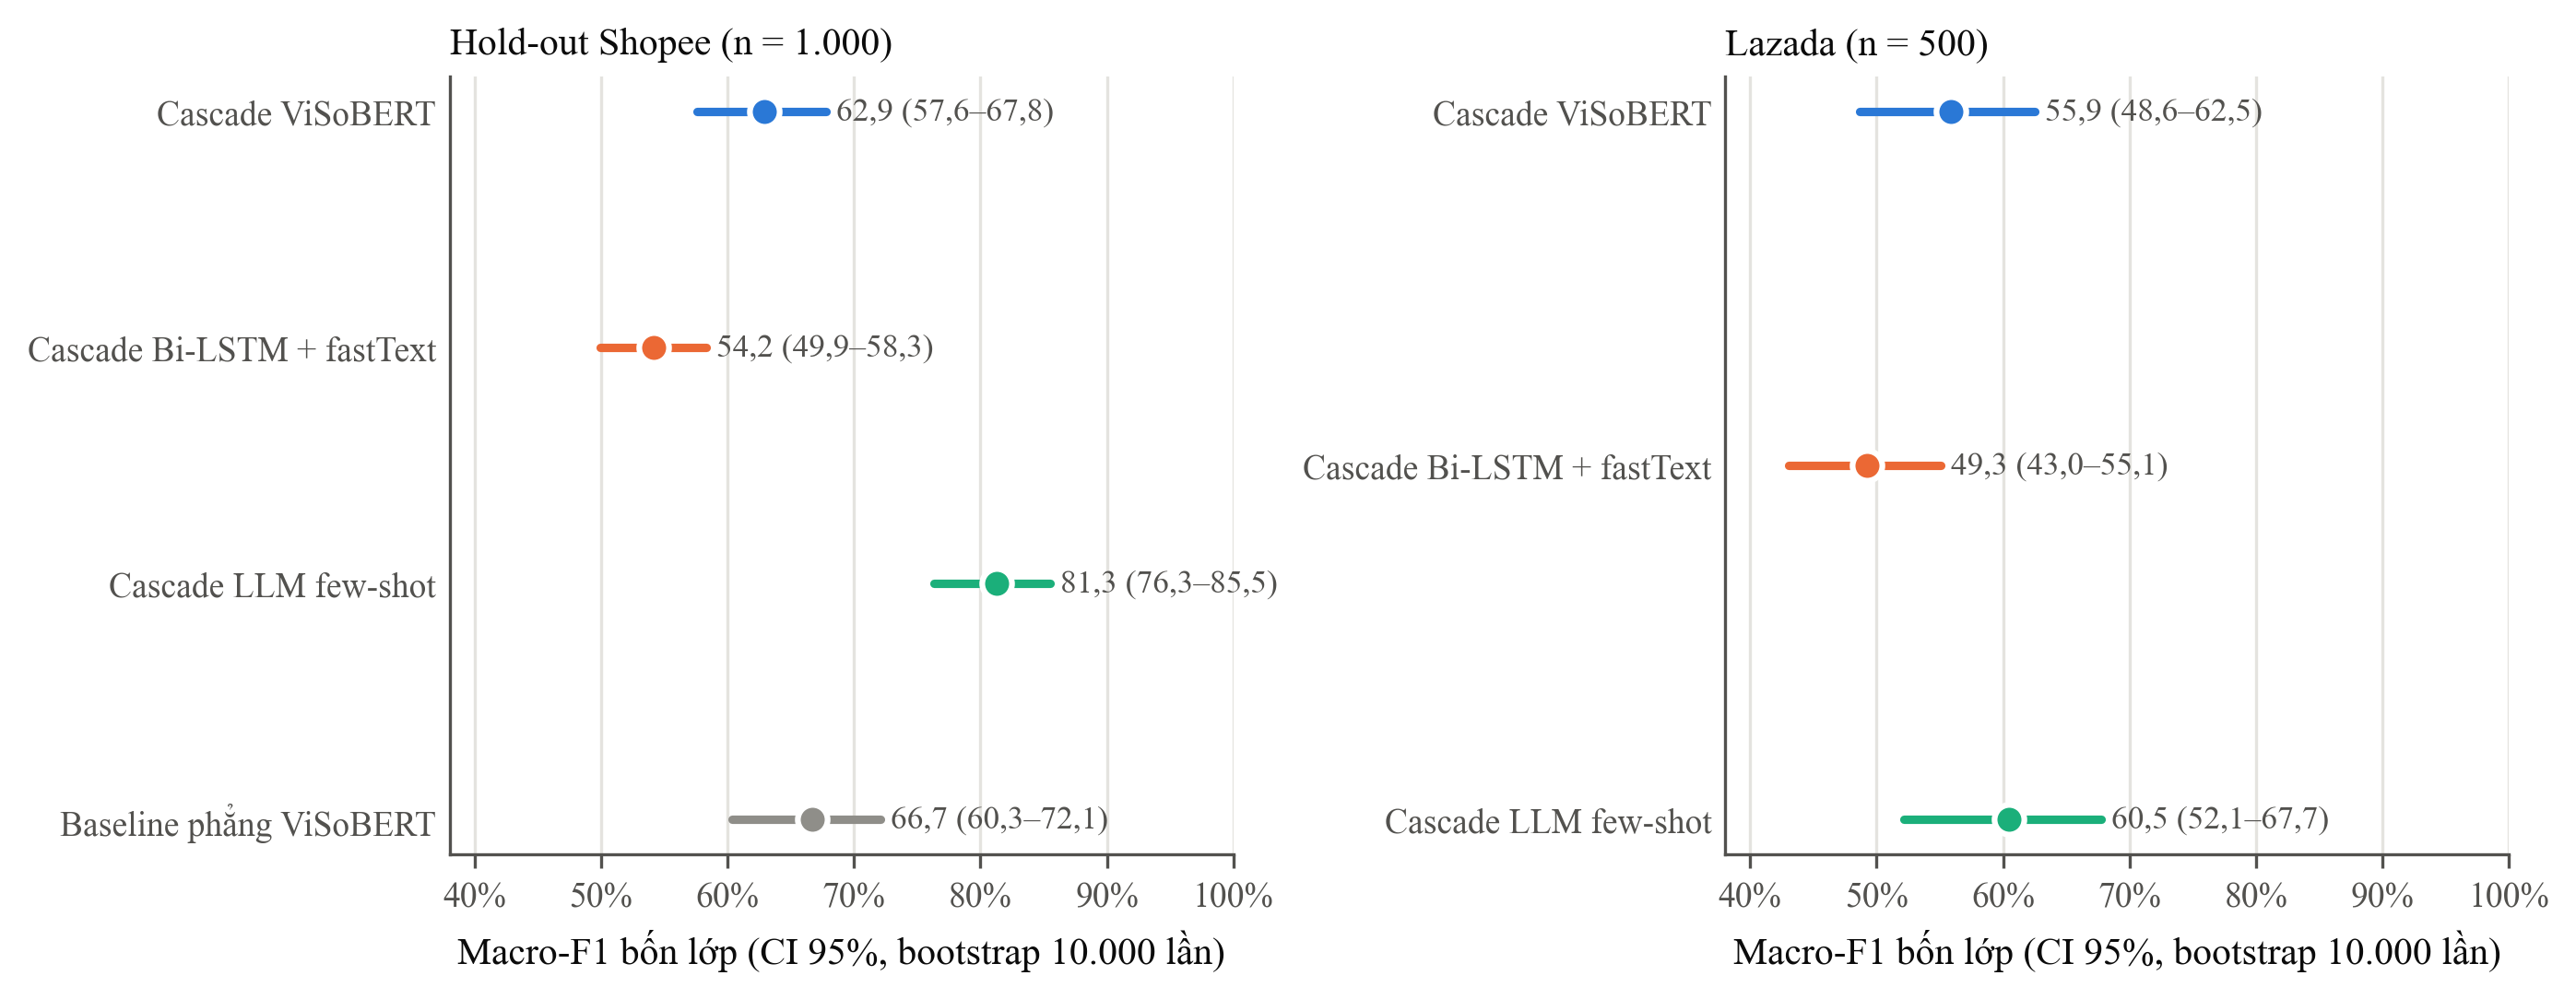

Hình — Macro-F1 bốn lớp và khoảng tin cậy 95% trên Hold-out Shopee và Lazada (seed 42 / LLM)


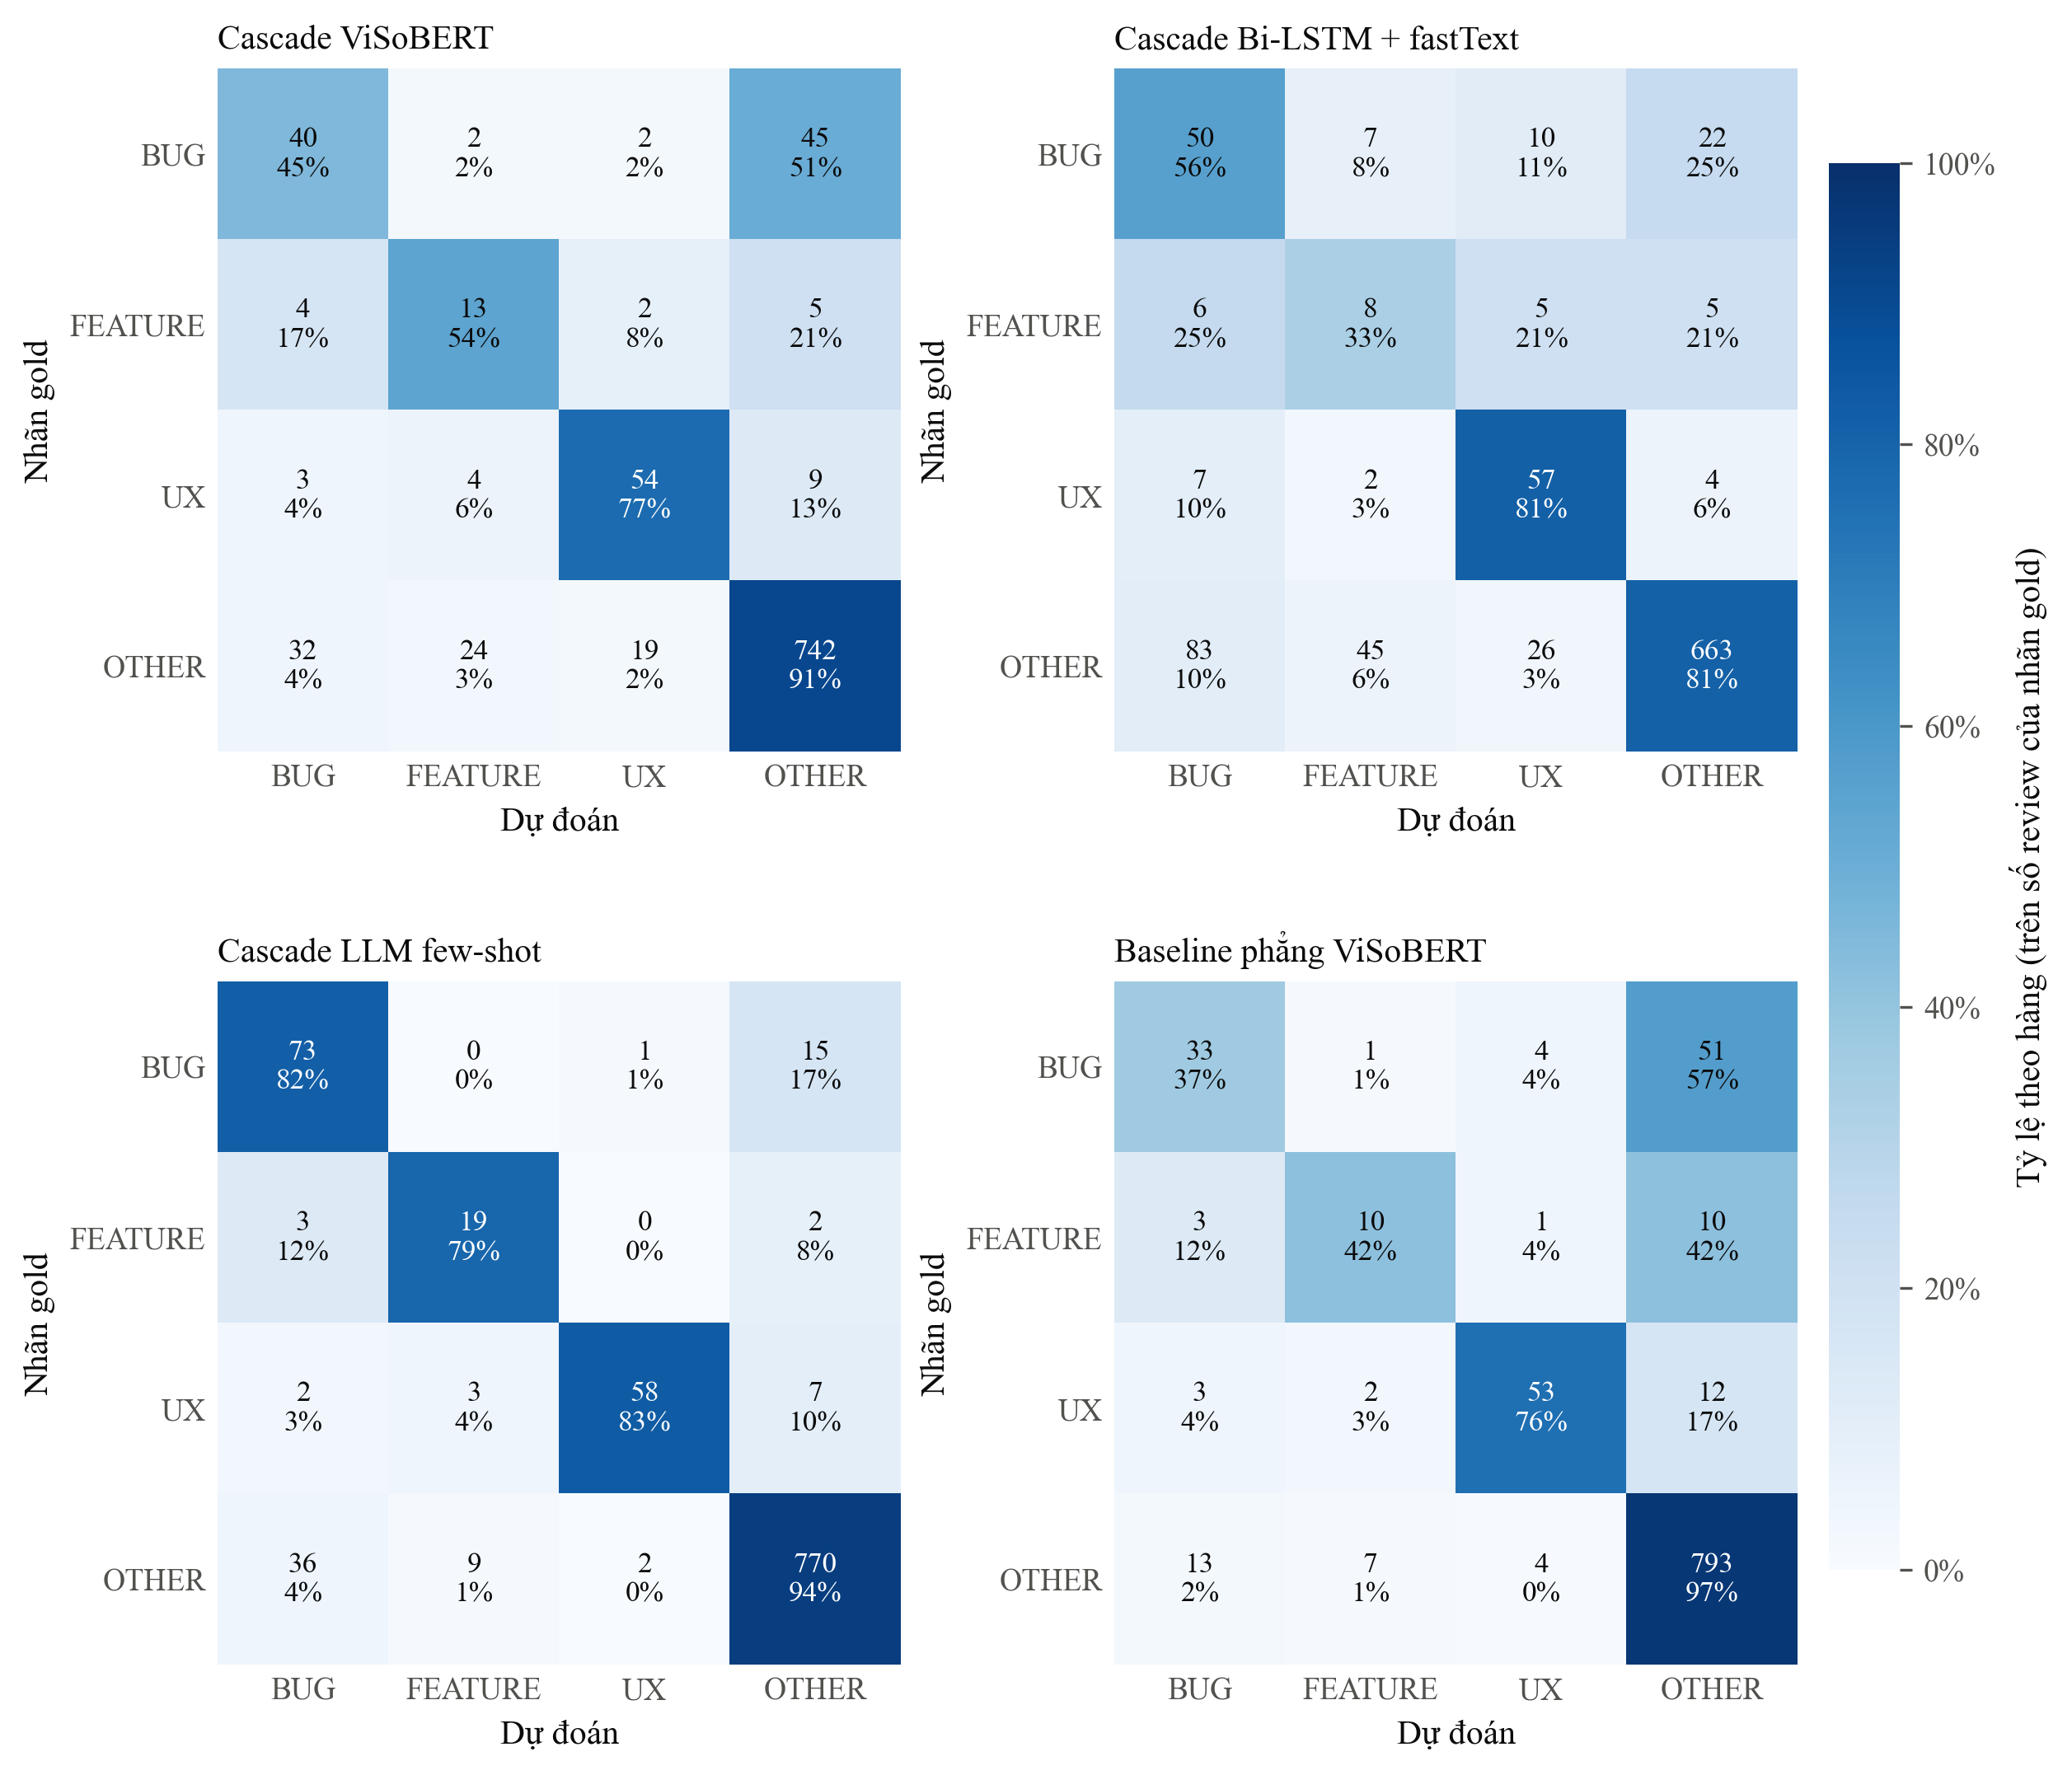

Hình — Ma trận nhầm lẫn end-to-end bốn lớp trên Hold-out (seed 42 / LLM; số review và tỷ lệ theo hàng)


Chiến lược,Macro-F1 (%),F1 BUG (%),F1 FEATURE (%),F1 UX (%),Số lần chạy
ViSoBERT,"76,2 ± 3,2","57,7 ± 11,0","91,0 ± 1,5","80,0 ± 0,0",3
Bi-LSTM + fastText,"68,8 ± 3,5","42,9 ± 10,2","85,4 ± 1,4","78,1 ± 1,8",3
LLM few-shot,"75,0","55,6","91,4","78,0",1


Ghi chú: Tập chọn theo cụm từ gợi ý FEATURE/UX, không phản ánh phân bố tự nhiên; báo cáo tách khỏi chỉ số chính.


Cấu hình,Macro-F1 4 lớp (%),F1 BUG (%),F1 FEATURE (%),F1 UX (%),F1 OTHER (%),CI 95% (seed 42 / LLM)
Cascade ViSoBERT,"56,0 ± 0,4","42,4 ± 1,6","33,8 ± 2,1","59,0 ± 2,4","88,8 ± 1,3","48,6–62,5"
Cascade Bi-LSTM + fastText,"47,1 ± 6,4","31,9 ± 5,5","21,3 ± 6,7","55,3 ± 5,9","80,0 ± 8,3","43,0–55,1"
Cascade LLM few-shot,"60,5","48,1","37,5","66,7","89,8","52,1–67,7"


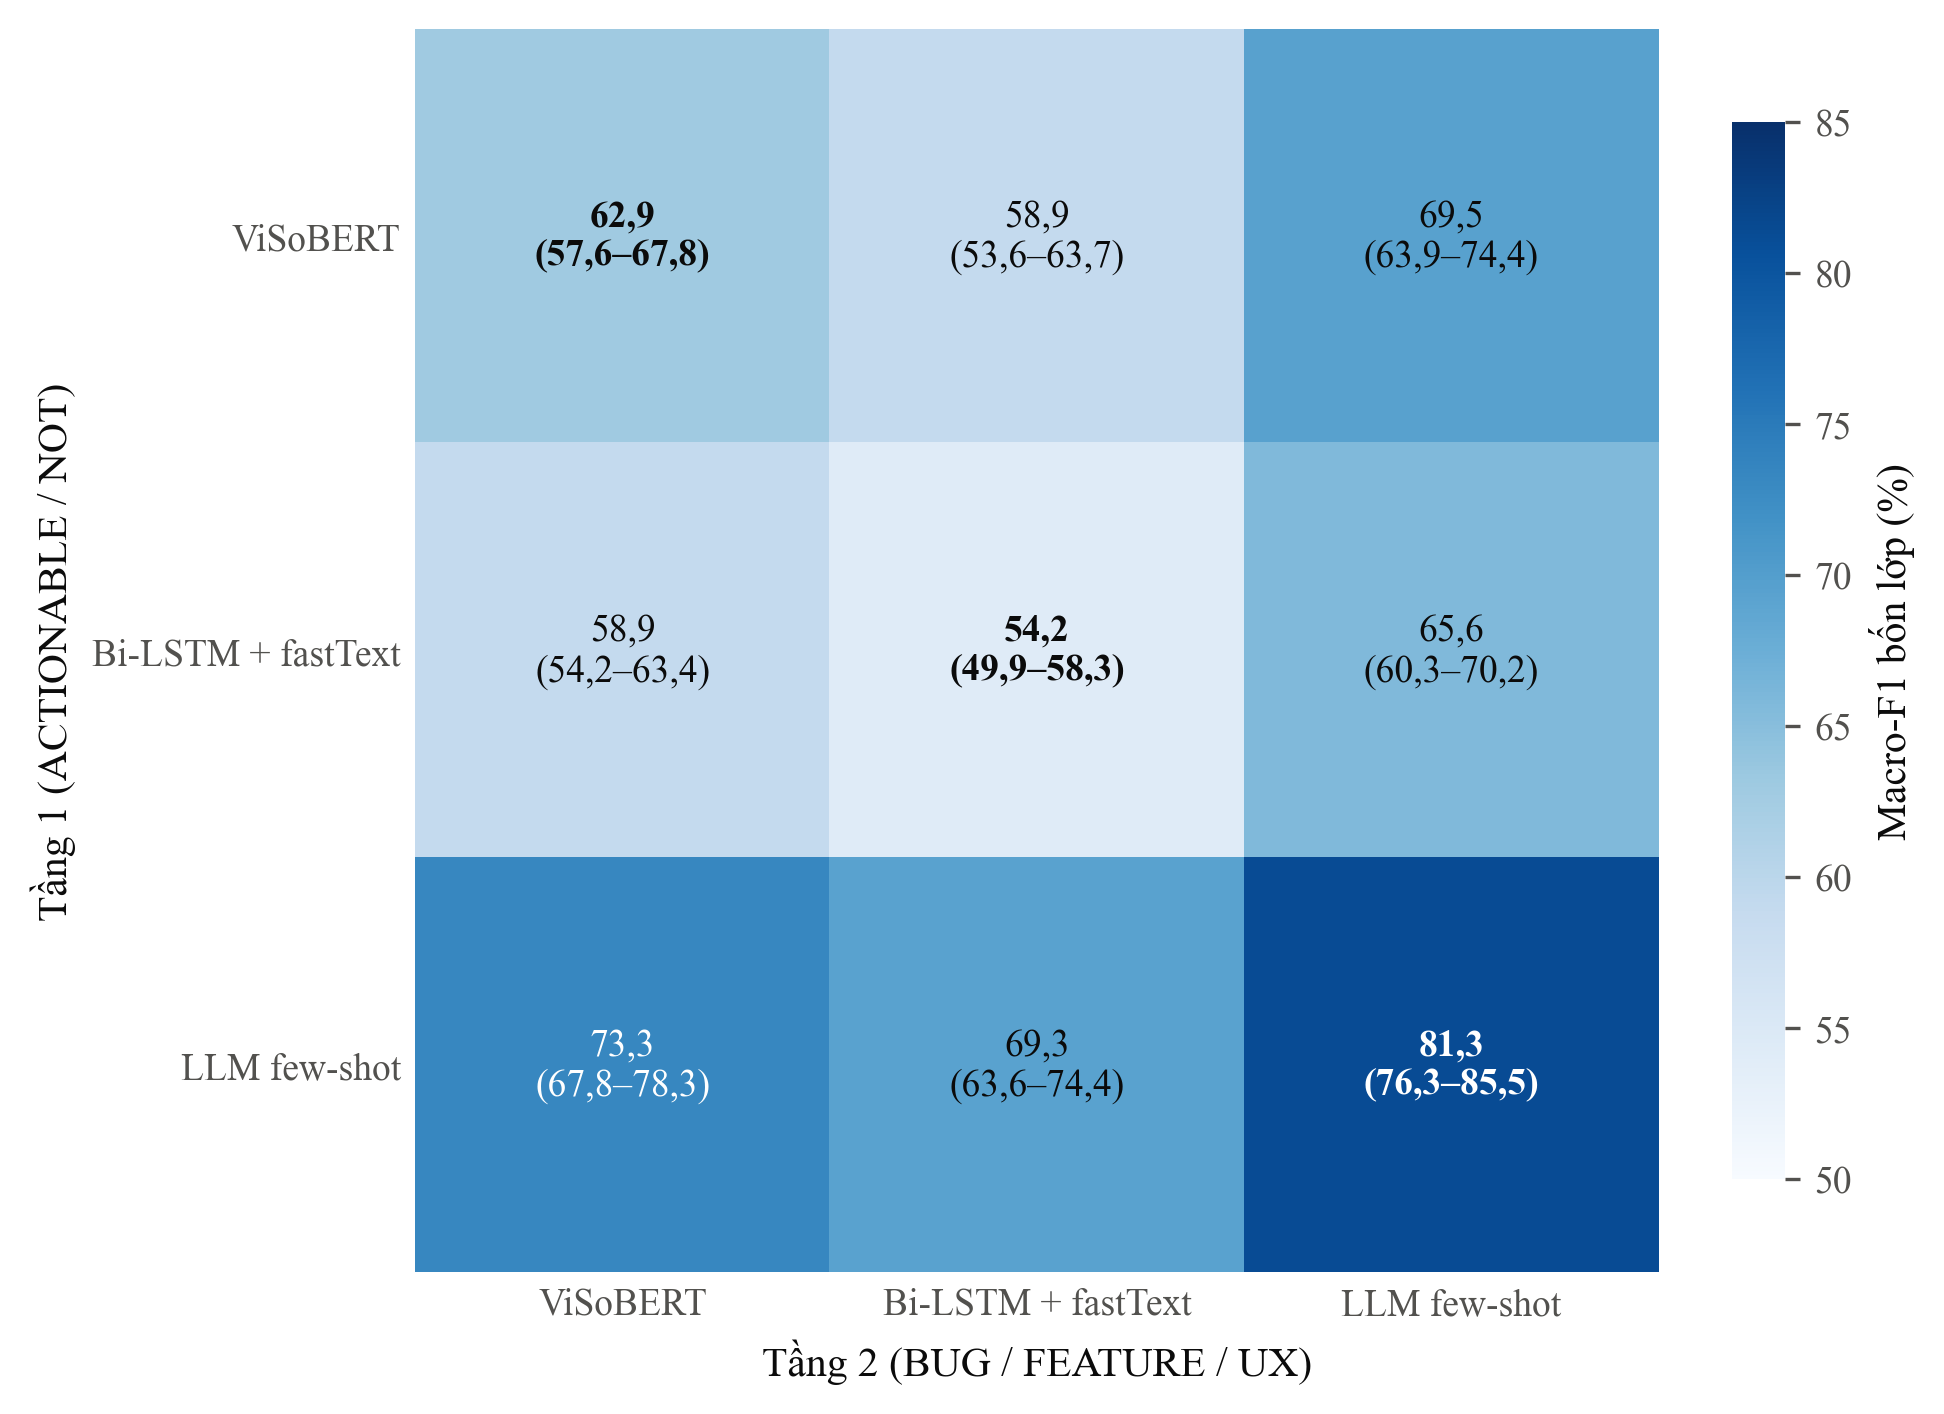

Hình — Macro-F1 bốn lớp trên Hold-out của chín tổ hợp tầng 1 × tầng 2 (đường chéo: cascade thuần; trong ngoặc: CI 95%)


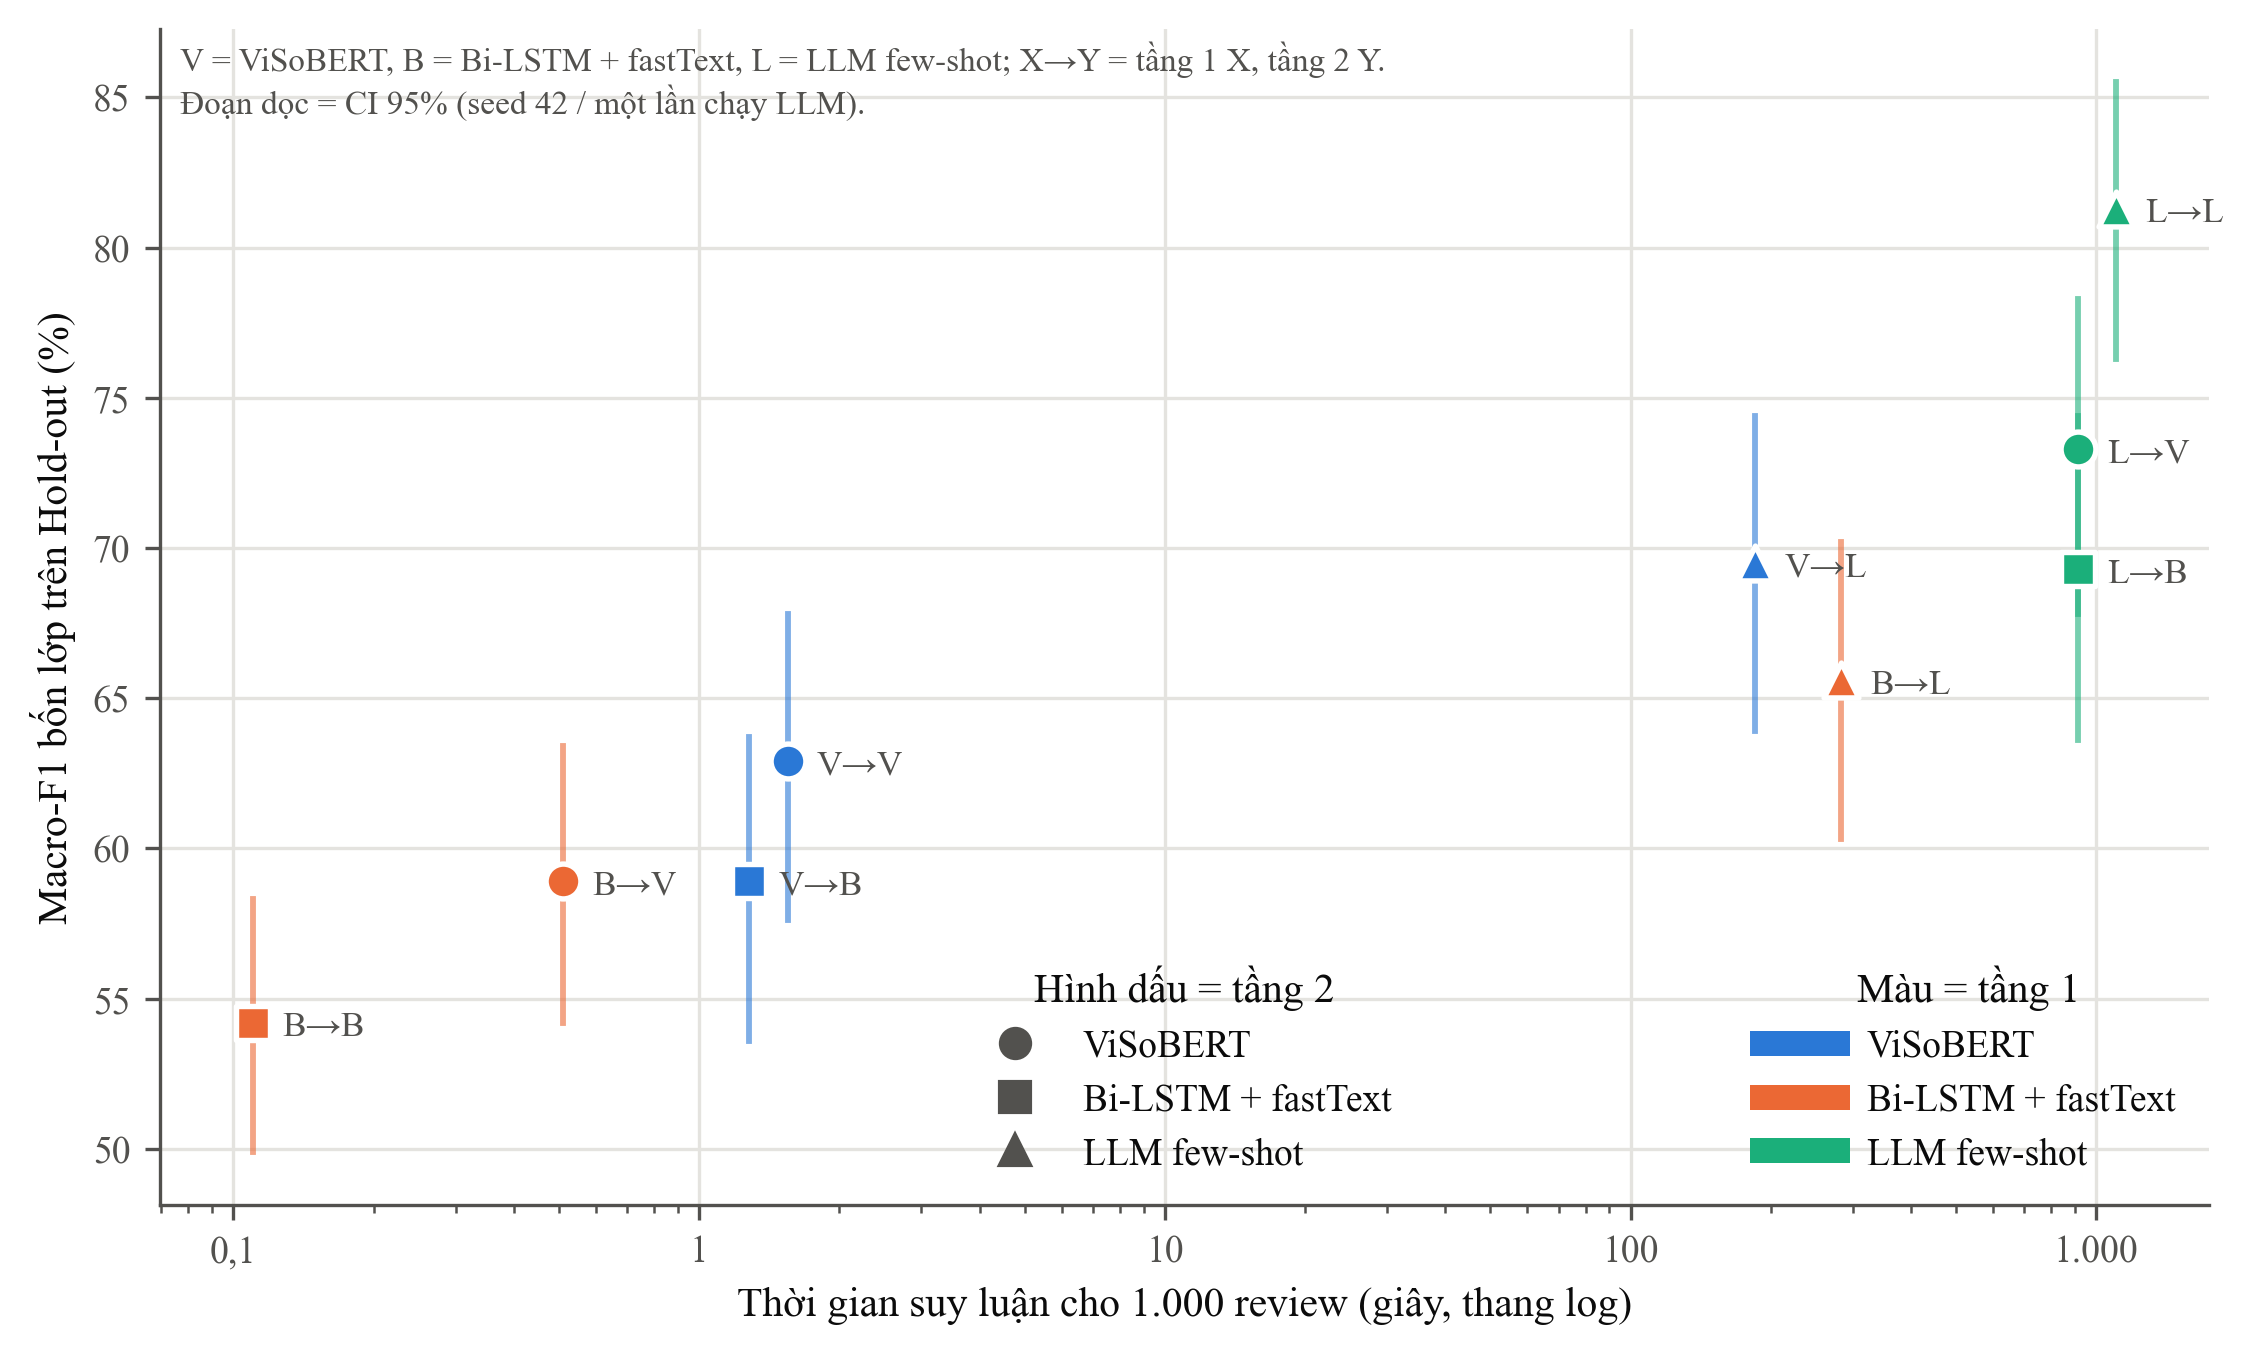

Hình — Đánh đổi giữa Macro-F1 trên Hold-out và thời gian suy luận của chín tổ hợp tầng 1 × tầng 2


Tầng 1,Tầng 2,Macro-F1 (%),CI 95%,Tỷ lệ giữ lại ở tầng 1,Giây / 1.000 review,USD / 1.000 review
ViSoBERT,ViSoBERT,"62,9","57,6–67,8","19,9%","1,55","0,0000"
ViSoBERT,Bi-LSTM + fastText,"58,9","53,6–63,7","19,9%","1,28","0,0000"
ViSoBERT,LLM few-shot,"69,5","63,9–74,4","19,9%","185,17","0,0320"
Bi-LSTM + fastText,ViSoBERT,"58,9","54,2–63,4","30,6%","0,51","0,0000"
Bi-LSTM + fastText,Bi-LSTM + fastText,"54,2","49,9–58,3","30,6%","0,11","0,0000"
Bi-LSTM + fastText,LLM few-shot,"65,6","60,3–70,2","30,6%","282,87","0,0492"
LLM few-shot,ViSoBERT,"73,3","67,8–78,3","20,6%","913,37","0,1733"
LLM few-shot,Bi-LSTM + fastText,"69,3","63,6–74,4","20,6%","913,10","0,1733"
LLM few-shot,LLM few-shot,"81,3","76,3–85,5","20,6%","1.103,45","0,2064"


Ghi chú: Dòng tô màu là ba cascade thuần. Chi phí cho 1.000 review = tầng 1 trên mọi review + tầng 2 trên phần tầng 1 giữ lại.


Chiến lược,Nhãn cần,Huấn luyện (giây / seed),Suy luận (giây / 1.000 review),GPU tối đa (GB),USD / 1.000 review,Phụ thuộc nhà cung cấp,Giờ gán nhãn
ViSoBERT,Train 1.200 + Validation 350,"42,7","1,55","2,51","0,0000",Không (chạy cục bộ),{...}
Bi-LSTM + fastText,Train 1.200 + Validation 350,"6,4","0,11","0,62","0,0000",Không (chạy cục bộ),{...}
LLM few-shot,17 ví dụ (Train) + Validation 350,"0,0","1.103,50","0,00","0,2064","Có (OpenAI, snapshot cố định)",{...}
Baseline phẳng ViSoBERT,Train 1.200 + Validation 350,"39,7","1,39","2,50","0,0000",Không (chạy cục bộ),{...}


Ghi chú: Giờ gán nhãn thực tế chưa được ghi nhận ({...}).


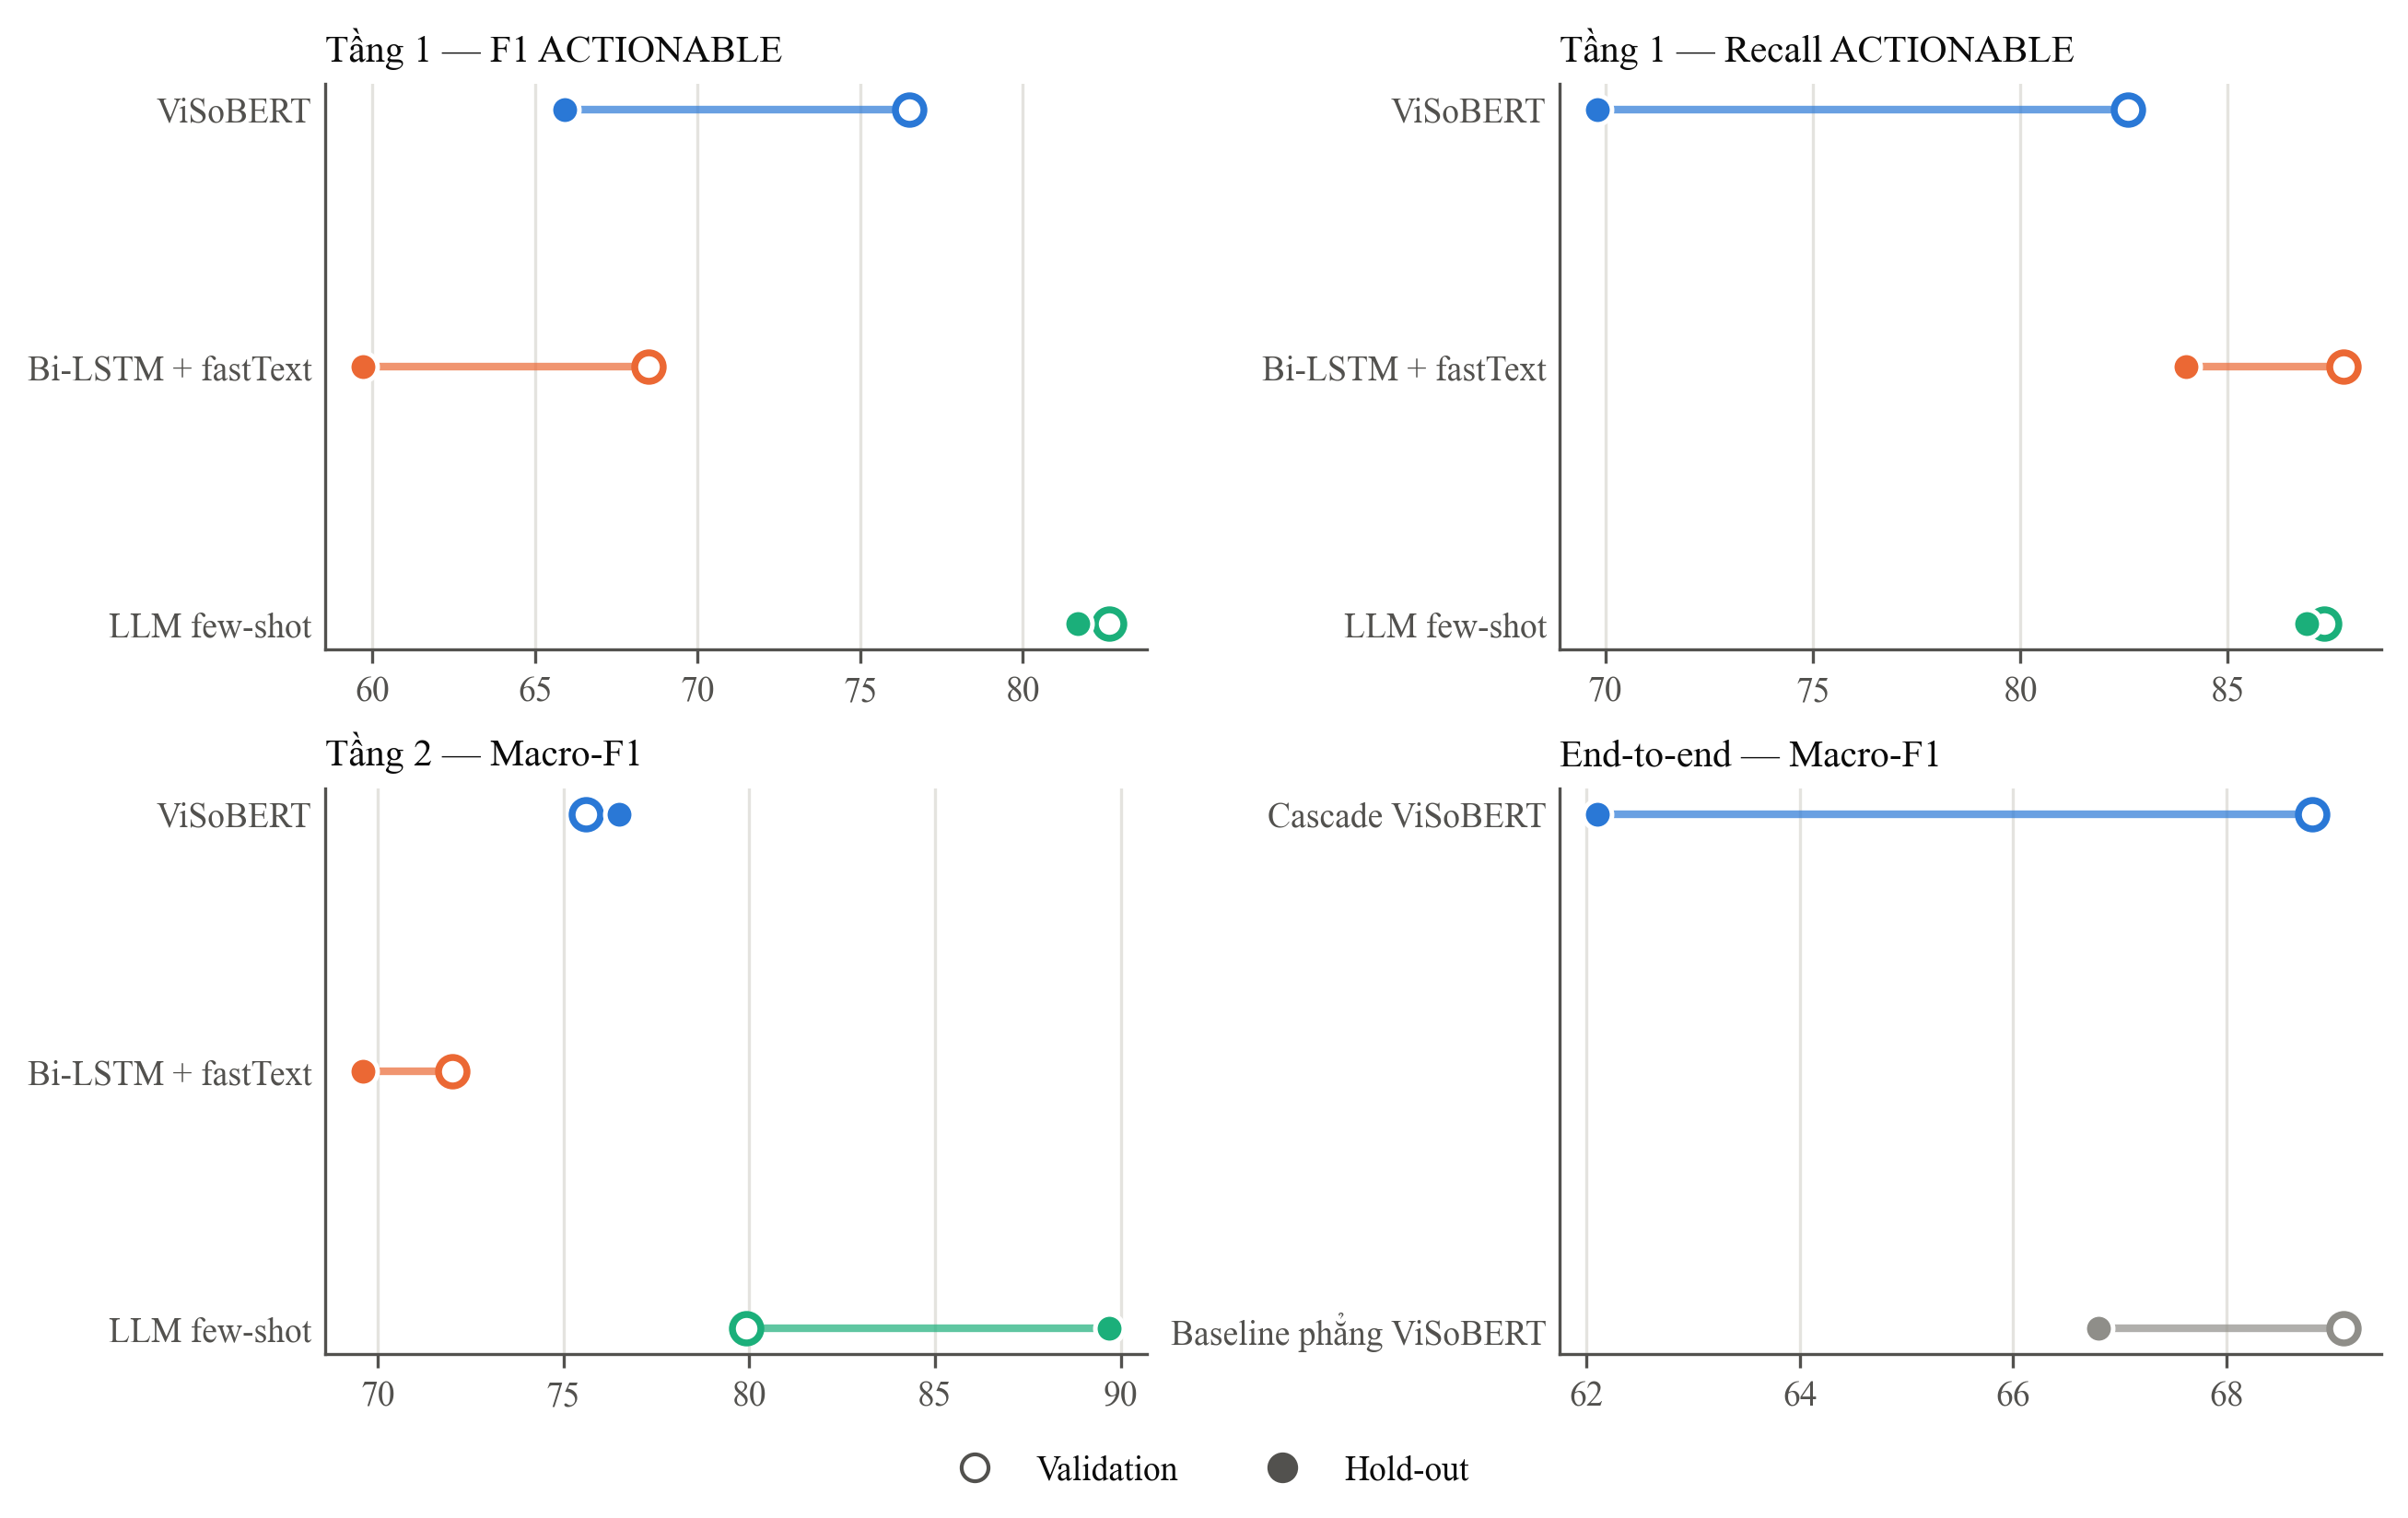

Hình — So sánh kết quả trên Validation và Hold-out (%; neural: trung bình ba seed)


Chỉ số,Chiến lược,Validation (%),Hold-out (%),Chênh (điểm %)
Tầng 1 — F1 ACTIONABLE,ViSoBERT,"76,5","65,9","-10,6"
Tầng 1 — Recall ACTIONABLE,ViSoBERT,"82,6","69,8","-12,8"
Tầng 2 — Macro-F1,ViSoBERT,"75,6","76,5","0,9"
Tầng 1 — F1 ACTIONABLE,Bi-LSTM + fastText,"68,5","59,7","-8,8"
Tầng 1 — Recall ACTIONABLE,Bi-LSTM + fastText,"87,8","84,0","-3,8"
Tầng 2 — Macro-F1,Bi-LSTM + fastText,"72,0","69,6","-2,4"
Tầng 1 — F1 ACTIONABLE,LLM few-shot,"82,7","81,7","-1,0"
Tầng 1 — Recall ACTIONABLE,LLM few-shot,"87,3","86,9","-0,4"
Tầng 2 — Macro-F1,LLM few-shot,"79,9","89,7","9,8"
End-to-end — Macro-F1,Cascade ViSoBERT,"68,8","62,1","-6,7"


In [6]:
section('GĐ10 — Đánh giá cuối trên Hold-out, focused set và Lazada')
g = lambda f: pd.read_csv(os.path.join(RQ1, f))
T1H = g('gd10_tier1_holdout.csv')
add_table(fmt_frame(rename(T1H, {'chiến lược': 'Chiến lược', 'F1 ACT': 'F1 ACT (%)', 'Recall ACT': 'Recall ACT (%)',
                                 'Precision ACT': 'Precision ACT (%)', 'Macro-F1 (2 lớp)': 'Macro-F1 2 lớp (%)',
                                 'số lần chạy': 'Số lần chạy'}),
                    pm=['F1 ACT (%)', 'Recall ACT (%)', 'Precision ACT (%)', 'Macro-F1 2 lớp (%)']),
          'Kết quả tầng 1 trên Hold-out (n = 1.000)', highlight=[(2, 'F1 ACT (%)'), (2, 'Precision ACT (%)')],
          widths=[3.6, 2.4, 2.4, 2.6, 2.6, 1.8])
T2H = g('gd10_tier2_holdout.csv')
add_table(fmt_frame(rename(T2H, {'chiến lược': 'Chiến lược', 'Macro-F1': 'Macro-F1 (%)', 'F1 BUG': 'F1 BUG (%)',
                                 'F1 FEATURE': 'F1 FEATURE (%)', 'F1 UX': 'F1 UX (%)', 'số lần chạy': 'Số lần chạy'}),
                    pm=['Macro-F1 (%)', 'F1 BUG (%)', 'F1 FEATURE (%)', 'F1 UX (%)']),
          'Kết quả tầng 2 trên phần gold-actionable của Hold-out (n = 183)', widths=[3.6, 2.6, 2.6, 2.8, 2.6, 1.8])

E2E, E2ECI = g('gd10_e2e_holdout.csv'), g('gd10_e2e_holdout_ci.csv').set_index('cấu hình')
e = rename(E2E, {'cấu hình': 'Cấu hình', 'Macro-F1 (4 lớp)': 'Macro-F1 4 lớp (%)', 'F1 BUG': 'F1 BUG (%)', 'F1 FEATURE': 'F1 FEATURE (%)',
                 'F1 UX': 'F1 UX (%)', 'F1 OTHER': 'F1 OTHER (%)'})
e['CI 95% (seed 42 / LLM)'] = [f"{E2ECI.loc[c, 'CI 2,5%'] * 100:.1f}–{E2ECI.loc[c, 'CI 97,5%'] * 100:.1f}" for c in E2E['cấu hình']]
add_table(fmt_frame(e, pm=['Macro-F1 4 lớp (%)', 'F1 BUG (%)', 'F1 FEATURE (%)', 'F1 UX (%)', 'F1 OTHER (%)', 'CI 95% (seed 42 / LLM)']),
          'Kết quả end-to-end bốn lớp trên Hold-out: ba cascade và baseline phẳng', highlight=[(2, 'Macro-F1 4 lớp (%)')],
          widths=[3.6, 2.2, 2.0, 2.2, 2.0, 2.0, 2.4], font_size=10)
D = g('gd10_e2e_holdout_diff.csv')
d = pd.DataFrame({'So sánh (A − B)': D['A'] + ' − ' + D['B'], 'Chênh (điểm %)': D['chênh (A − B)'] * 100,
                  'CI 95%': [f"{a * 100:.1f} đến {b * 100:.1f}" for a, b in zip(D['CI 2,5%'], D['CI 97,5%'])],
                  'Có ý nghĩa thống kê': ~D['CI chứa 0']})
add_table(fmt_frame(d, decimals={'Chênh (điểm %)': 1}, pm=['CI 95%']),
          'Chênh lệch Macro-F1 bốn lớp giữa các cấu hình trên Hold-out (bootstrap ghép cặp)',
          note='Có ý nghĩa thống kê khi CI 95% của chênh lệch không chứa 0 (quy ước đã khóa trong protocol).',
          widths=[7.4, 2.4, 3.4, 2.8])

CI = lambda f: g(f).rename(columns={'cấu hình': 'config', 'giá trị': 'value', 'CI 2,5%': 'lo', 'CI 97,5%': 'hi'})
add_figure(RF.fig_forest({'Hold-out Shopee (n = 1.000)': CI('gd10_e2e_holdout_ci.csv'), 'Lazada (n = 500)': CI('gd10_e2e_lazada_ci.csv')},
                         os.path.join(FIG, 'fig_gd10_forest.png')),
           'Macro-F1 bốn lớp và khoảng tin cậy 95% trên Hold-out Shopee và Lazada (seed 42 / LLM)')
CMH = g('gd10_confusion_holdout.csv')
mats = {c: x.drop(columns='cấu_hình').set_index(x.columns[0]) for c, x in CMH.groupby('cấu_hình', sort=False)}
add_figure(RF.fig_confusions(mats, os.path.join(FIG, 'fig_gd10_confusion_holdout.png'), ncols=2),
           'Ma trận nhầm lẫn end-to-end bốn lớp trên Hold-out (seed 42 / LLM; số review và tỷ lệ theo hàng)', width=15)

FOC = g('gd10_tier2_focused.csv')
add_table(fmt_frame(rename(FOC, {'chiến lược': 'Chiến lược', 'Macro-F1': 'Macro-F1 (%)', 'F1 BUG': 'F1 BUG (%)',
                                 'F1 FEATURE': 'F1 FEATURE (%)', 'F1 UX': 'F1 UX (%)', 'số lần chạy': 'Số lần chạy'}),
                    pm=['Macro-F1 (%)', 'F1 BUG (%)', 'F1 FEATURE (%)', 'F1 UX (%)']),
          'Kết quả tầng 2 trên focused FEATURE/UX set (tập làm giàu, n = 91 gold-actionable)',
          note='Tập chọn theo cụm từ gợi ý FEATURE/UX, không phản ánh phân bố tự nhiên; báo cáo tách khỏi chỉ số chính.',
          widths=[3.6, 2.6, 2.6, 2.8, 2.6, 1.8])
LAZ, LAZCI = g('gd10_e2e_lazada.csv'), g('gd10_e2e_lazada_ci.csv').set_index('cấu hình')
z = rename(LAZ, {'cấu hình': 'Cấu hình', 'Macro-F1 (4 lớp)': 'Macro-F1 4 lớp (%)', 'F1 BUG': 'F1 BUG (%)', 'F1 FEATURE': 'F1 FEATURE (%)',
                 'F1 UX': 'F1 UX (%)', 'F1 OTHER': 'F1 OTHER (%)'})
z['CI 95% (seed 42 / LLM)'] = [f"{LAZCI.loc[c, 'CI 2,5%'] * 100:.1f}–{LAZCI.loc[c, 'CI 97,5%'] * 100:.1f}" for c in LAZ['cấu hình']]
add_table(fmt_frame(z, pm=['Macro-F1 4 lớp (%)', 'F1 BUG (%)', 'F1 FEATURE (%)', 'F1 UX (%)', 'F1 OTHER (%)', 'CI 95% (seed 42 / LLM)']),
          'Kết quả end-to-end trên Lazada external test (n = 500)', widths=[3.6, 2.2, 2.0, 2.2, 2.0, 2.0, 2.4], font_size=10)

HY = g('gd10_hybrid_holdout.csv')
add_figure(RF.fig_hybrid_heatmap(HY, os.path.join(FIG, 'fig_gd10_hybrid.png')),
           'Macro-F1 bốn lớp trên Hold-out của chín tổ hợp tầng 1 × tầng 2 (đường chéo: cascade thuần; trong ngoặc: CI 95%)', width=13)
add_figure(RF.fig_cost_performance(HY, os.path.join(FIG, 'fig_gd10_cost_performance.png')),
           'Đánh đổi giữa Macro-F1 trên Hold-out và thời gian suy luận của chín tổ hợp tầng 1 × tầng 2', width=15)
h = rename(HY, {'tầng 1 (X)': 'Tầng 1', 'tầng 2 (Y)': 'Tầng 2', 'Macro-F1 (4 lớp)': 'Macro-F1 (%)', 'CI 95%': 'CI 95%',
                'tỷ lệ tầng 1 giữ lại': 'Tỷ lệ giữ lại ở tầng 1', 'giây / 1.000 review': 'Giây / 1.000 review',
                'USD API / 1.000 review': 'USD / 1.000 review'})
add_table(fmt_frame(h, decimals={'Macro-F1 (%)': 1, 'Giây / 1.000 review': 2, 'USD / 1.000 review': 4},
                    percent=['Tỷ lệ giữ lại ở tầng 1'], pm=['CI 95%']),
          'Hybrid 3 × 3 trên Hold-out: hiệu năng và chi phí suy luận', highlight=[(0, 'Macro-F1 (%)'), (4, 'Macro-F1 (%)'), (8, 'Macro-F1 (%)')],
          note='Dòng tô màu là ba cascade thuần. Chi phí cho 1.000 review = tầng 1 trên mọi review + tầng 2 trên phần tầng 1 giữ lại.',
          widths=[3.0, 3.0, 1.8, 2.0, 2.0, 2.2, 2.0], font_size=10)
CS = g('gd10_cost_summary.csv')
cs = rename(CS, {'chiến lược': 'Chiến lược', 'nhãn cần': 'Nhãn cần', 'huấn luyện / seed (giây, tầng 1 + tầng 2)': 'Huấn luyện (giây / seed)',
                 'suy luận / 1.000 review (giây)': 'Suy luận (giây / 1.000 review)', 'GPU tối đa (GB)': 'GPU tối đa (GB)',
                 'USD API / 1.000 review': 'USD / 1.000 review', 'phụ thuộc nhà cung cấp': 'Phụ thuộc nhà cung cấp',
                 'giờ gán nhãn': 'Giờ gán nhãn'})
add_table(fmt_frame(cs, decimals={'Huấn luyện (giây / seed)': 1, 'Suy luận (giây / 1.000 review)': 2, 'GPU tối đa (GB)': 2,
                                  'USD / 1.000 review': 4}),
          'Chi phí và mức tự chủ của các chiến lược (GPU Tesla T4)', note='Giờ gán nhãn thực tế chưa được ghi nhận ({...}).',
          widths=[2.6, 2.8, 1.9, 2.0, 1.6, 1.7, 2.4, 1.5], font_size=10)

V1 = pd.read_csv(os.path.join(RQ1, 'tier1_validation_results.csv')).set_index('strategy')
V2 = pd.read_csv(os.path.join(RQ1, 'tier2_validation_results.csv')).set_index('strategy')
VC = pd.read_csv(os.path.join(RQ1, 'cascade_vs_flat_validation.csv')).dropna(subset=['strategy']).set_index('strategy')
H1, H2, HE = T1H.set_index('chiến lược'), T2H.set_index('chiến lược'), E2E.set_index('cấu hình')
rows = []
for s in ('ViSoBERT', 'Bi-LSTM + fastText'):
    rows += [{'metric': 'Tầng 1 — F1 ACTIONABLE', 'strategy': s, 'validation': mean_of(V1.loc[s, 'f1_actionable']), 'holdout': mean_of(H1.loc[s, 'F1 ACT'])},
             {'metric': 'Tầng 1 — Recall ACTIONABLE', 'strategy': s, 'validation': mean_of(V1.loc[s, 'recall_actionable']), 'holdout': mean_of(H1.loc[s, 'Recall ACT'])},
             {'metric': 'Tầng 2 — Macro-F1', 'strategy': s, 'validation': mean_of(V2.loc[s, 'macro_f1']), 'holdout': mean_of(H2.loc[s, 'Macro-F1'])}]
rows += [{'metric': 'Tầng 1 — F1 ACTIONABLE', 'strategy': 'LLM few-shot', 'validation': LM.loc['tier1', 'f1_actionable'] * 100, 'holdout': mean_of(H1.loc['LLM few-shot', 'F1 ACT'])},
         {'metric': 'Tầng 1 — Recall ACTIONABLE', 'strategy': 'LLM few-shot', 'validation': LM.loc['tier1', 'recall_actionable'] * 100, 'holdout': mean_of(H1.loc['LLM few-shot', 'Recall ACT'])},
         {'metric': 'Tầng 2 — Macro-F1', 'strategy': 'LLM few-shot', 'validation': LM.loc['tier2', 'macro_f1'] * 100, 'holdout': mean_of(H2.loc['LLM few-shot', 'Macro-F1'])},
         {'metric': 'End-to-end — Macro-F1', 'strategy': 'Cascade ViSoBERT', 'validation': mean_of(VC.loc['Cascade ViSoBERT', 'macro_f1']), 'holdout': mean_of(HE.loc['Cascade ViSoBERT', 'Macro-F1 (4 lớp)'])},
         {'metric': 'End-to-end — Macro-F1', 'strategy': 'Baseline phẳng ViSoBERT', 'validation': mean_of(VC.loc['Baseline phẳng ViSoBERT', 'macro_f1']), 'holdout': mean_of(HE.loc['Baseline phẳng ViSoBERT', 'Macro-F1 (4 lớp)'])}]
VH = pd.DataFrame(rows)
add_figure(RF.fig_val_vs_holdout(VH, os.path.join(FIG, 'fig_gd10_val_vs_holdout.png')),
           'So sánh kết quả trên Validation và Hold-out (%; neural: trung bình ba seed)')
vh = VH.rename(columns={'metric': 'Chỉ số', 'strategy': 'Chiến lược', 'validation': 'Validation (%)', 'holdout': 'Hold-out (%)'})
vh['Chênh (điểm %)'] = vh['Hold-out (%)'] - vh['Validation (%)']
add_table(fmt_frame(vh, decimals={'Validation (%)': 1, 'Hold-out (%)': 1, 'Chênh (điểm %)': 1}),
          'Số liệu Validation và Hold-out của từng chiến lược', widths=[4.6, 4.0, 2.4, 2.4, 2.6])

## GĐ11 — Phân loại toàn corpus

**Nguồn**

`gd11_validation_check.csv` (đối chiếu mô hình train lại với seed 42 của GĐ10) và `gd11_class_summary.csv`.

In [7]:
section('GĐ11 — Phân loại toàn corpus bằng cascade ViSoBERT')
VCK = pd.read_csv(os.path.join(RQ2, 'gd11_validation_check.csv'))
add_table(fmt_frame(VCK.rename(columns={'chỉ số (Validation)': 'Chỉ số (Validation)', 'chênh (điểm)': 'Chênh (điểm %)'}),
                    decimals={'GĐ10 seed 42': 4, 'GĐ11': 4, 'Chênh (điểm %)': 2}),
          'Đối chiếu mô hình train lại ở GĐ11 với seed 42 của GĐ10 trên Validation', widths=[5.0, 3.6, 3.6, 3.6])
CS11 = pd.read_csv(os.path.join(RQ2, 'gd11_class_summary.csv'))
CS11['phạm vi'] = CS11['phạm vi'].map({'toàn corpus': 'Toàn corpus', 'train': 'Train', 'validation': 'Validation', 'holdout': 'Hold-out',
                                       'focused': 'Focused', 'none': 'Không thuộc tập có nhãn'})
add_table(fmt_frame(CS11.rename(columns={'phạm vi': 'Phạm vi', 'tỷ lệ ACTIONABLE': 'Tỷ lệ ACTIONABLE'}), percent=['Tỷ lệ ACTIONABLE']),
          'Kết quả phân loại toàn corpus Shopee bằng cascade ViSoBERT (seed 42, ngưỡng 0,11)',
          note='Prevalence pilot: 20,5% (CI 95% 16,8–24,7%); tỷ lệ kỳ vọng của bộ phân loại = 20,5% × recall 69,8 / precision 62,7 = 22,8%.',
          widths=[3.6, 1.6, 1.6, 1.8, 1.4, 1.8, 2.0, 2.2], font_size=10)

Chỉ số (Validation),GĐ10 seed 42,GĐ11,Chênh (điểm %)
Macro-F1 tầng 1,"0,8487","0,8487","0,00"
Recall ACTIONABLE,"0,8169","0,8169","0,00"
Macro-F1 tầng 2,"0,7632","0,7632","0,00"


Phạm vi,n,BUG,FEATURE,UX,OTHER,ACTIONABLE,Tỷ lệ ACTIONABLE
Toàn corpus,56.050,4.639,2.497,3.761,45.153,10.897,"19,4%"
Train,1.200,89,168,140,803,397,"33,1%"
Validation,350,26,19,21,284,66,"18,9%"
Hold-out,1.000,79,43,77,801,199,"19,9%"
Focused,150,13,79,23,35,115,"76,7%"
Không thuộc tập có nhãn,53.350,4.432,2.188,3.500,43.230,10.120,"19,0%"


Ghi chú: Prevalence pilot: 20,5% (CI 95% 16,8–24,7%); tỷ lệ kỳ vọng của bộ phân loại = 20,5% × recall 69,8 / precision 62,7 = 22,8%.


## GĐ12 — Gom cụm và loại chủ đạo

**Nguồn**

Bảng và hình của notebook 12 (`05_experiments/rq2_topics/`); hình được chép sang `09_thesis/figures/`.

Embedding,Số review,C_v,Số cụm,Tỷ lệ outlier,Cụm lớn nhất,Suy biến
mpnet (chính),9.048,"0,489",26,"30,2%","14,5%",Không
vietnamese-sbert,9.048,"0,607",2,"0,4%","99,5%",Có


min_topic_size,C_v,Số cụm,Tỷ lệ outlier,Cụm lớn nhất,Kích thước trung vị,Suy biến
15,"0,405",63,"38,1%","14,1%",36,Không
20,"0,476",37,"33,1%","16,0%",94,Không
30,"0,501",28,"32,0%","15,6%",134,Không
50,"0,528",22,"32,0%","14,4%",167,Không
75,"0,539",17,"38,6%","16,8%",185,Không


Ghi chú: Dòng tô màu là cấu hình được chọn.


Id,Tên cụm (LLM),Số review,Tần suất,Loại chủ đạo,Type purity,Phạm vi,Từ khóa c-TF-IDF
2,Quảng cáo gây phiền phức,1.322,"12,1%",mixed,"46,7%",app,"quản_cáo, qc, mẹ, hơi, xác_minh, ngọ"
3,Quảng cáo xuất hiện liên tục,1.287,"11,8%",UX,"98,2%",app,"quảng_cáo, gây, phiền, khó_chịu, nút, suốt"
0,Dịch vụ giao hàng kém chất lượng,1.232,"11,3%",mixed,"56,3%",ngoài_app,"shipper, giao, đơn, gọi, ngày, khách"
1,Lỗi tài khoản và thanh toán,1.098,"10,1%",BUG,"79,3%",app,"tài_khoản, ngân_hàng, liên_kết, khóa, thanh_toán, tiền"
5,Quảng cáo rác và khó chịu,635,"5,8%",UX,"69,9%",app,"quảng_cáo, rác, giả, phiền, khác, tắt"
4,Video tự phát âm thanh phiền phức,573,"5,3%",mixed,"49,6%",app,"video, âm_lượng, live, mở, giảm, âm_thanh"
7,Lỗi trong giỏ hàng và mua sắm,517,"4,7%",mixed,"47,0%",app,"tủ, giỏ, mua, shop, đồ, qc"
8,Chất lượng sản phẩm và giao hàng,447,"4,1%",FEATURE,"78,1%",ngoài_app,"sản_phẩm, bán, giá, shop, chất_lượng, mua"
6,Ứng dụng lag và chậm,435,"4,0%",BUG,"79,1%",app,"lag, chậm, lỗi, đơ, tệ, load"
9,Quảng cáo nhảy vào ứng dụng,420,"3,9%",mixed,"42,1%",app,"qc, nhảy, tải, xóa, good, qcao"


Ghi chú: Tần suất = số review của cụm / 10.897 review actionable; 1.298 review là outlier. Phạm vi do LLM nhận định, chỉ để BA tham khảo.


Id,Tên cụm,Số review,Loại chủ đạo,Purity A,Purity B,Purity,Đồng thuận,Cờ BA
9,Quảng cáo nhảy vào ứng dụng,420,mixed,"0,0%","10,0%","5,0%","90,0%",Có
2,Quảng cáo gây phiền phức,1.322,mixed,"20,0%","20,0%","20,0%","100,0%",Có
13,Lỗi nhập mã giảm giá,352,BUG,"10,0%","30,0%","20,0%","80,0%",Có
4,Video tự phát âm thanh phiền phức,573,mixed,"20,0%","20,0%","20,0%","100,0%",Có
14,Lỗi trong trò chơi và game,163,UX,"30,0%","40,0%","35,0%","90,0%",Có
11,Lỗi khi áp dụng voucher,294,BUG,"50,0%","50,0%","50,0%","100,0%",Có
7,Lỗi trong giỏ hàng và mua sắm,517,mixed,"50,0%","50,0%","50,0%","100,0%",Có
12,Lỗi xác minh số điện thoại,238,BUG,"50,0%","50,0%","50,0%","100,0%",Có
8,Chất lượng sản phẩm và giao hàng,447,FEATURE,"50,0%","60,0%","55,0%","90,0%",Có
6,Ứng dụng lag và chậm,435,BUG,"60,0%","60,0%","60,0%","100,0%",Không


Ghi chú: Purity trung bình theo cụm 55,6%, có trọng số theo kích thước 58,2%; đồng thuận 94,7%, Cohen κ 0,893; 9 cụm dưới 60% được gắn cờ cho BA.


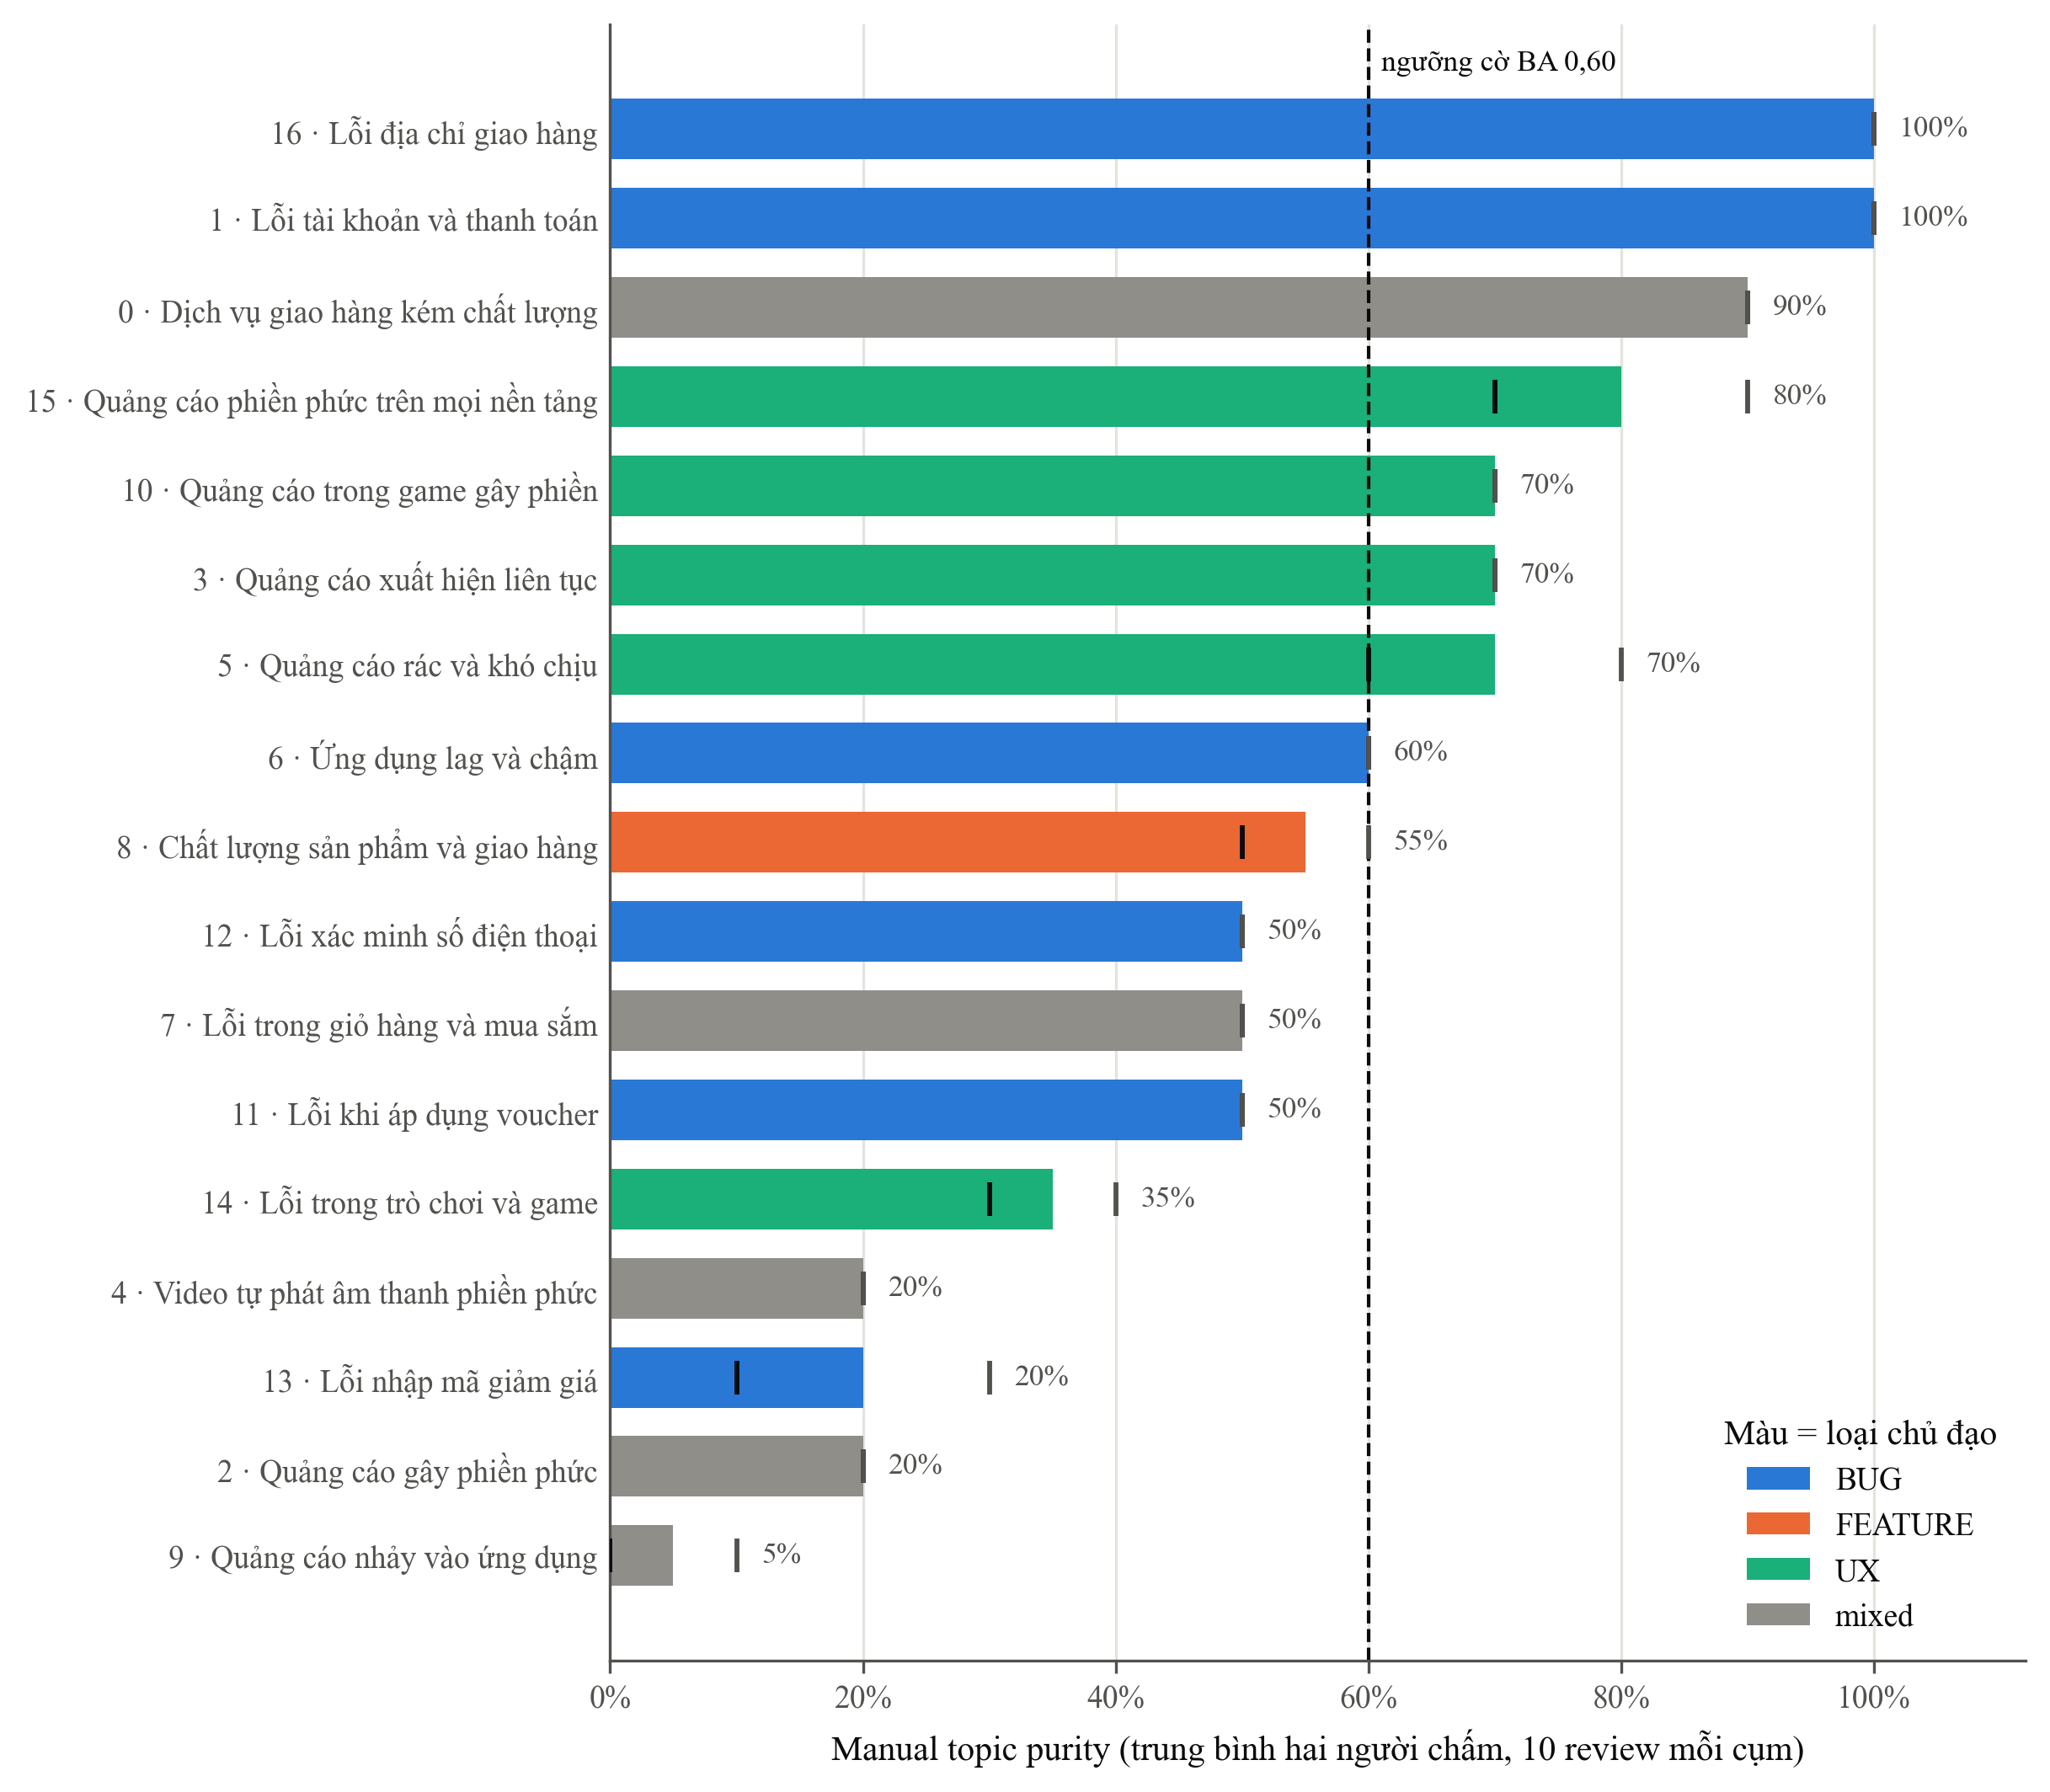

Hình — Manual topic purity theo cụm (thanh: trung bình hai người chấm; vạch: từng người chấm)


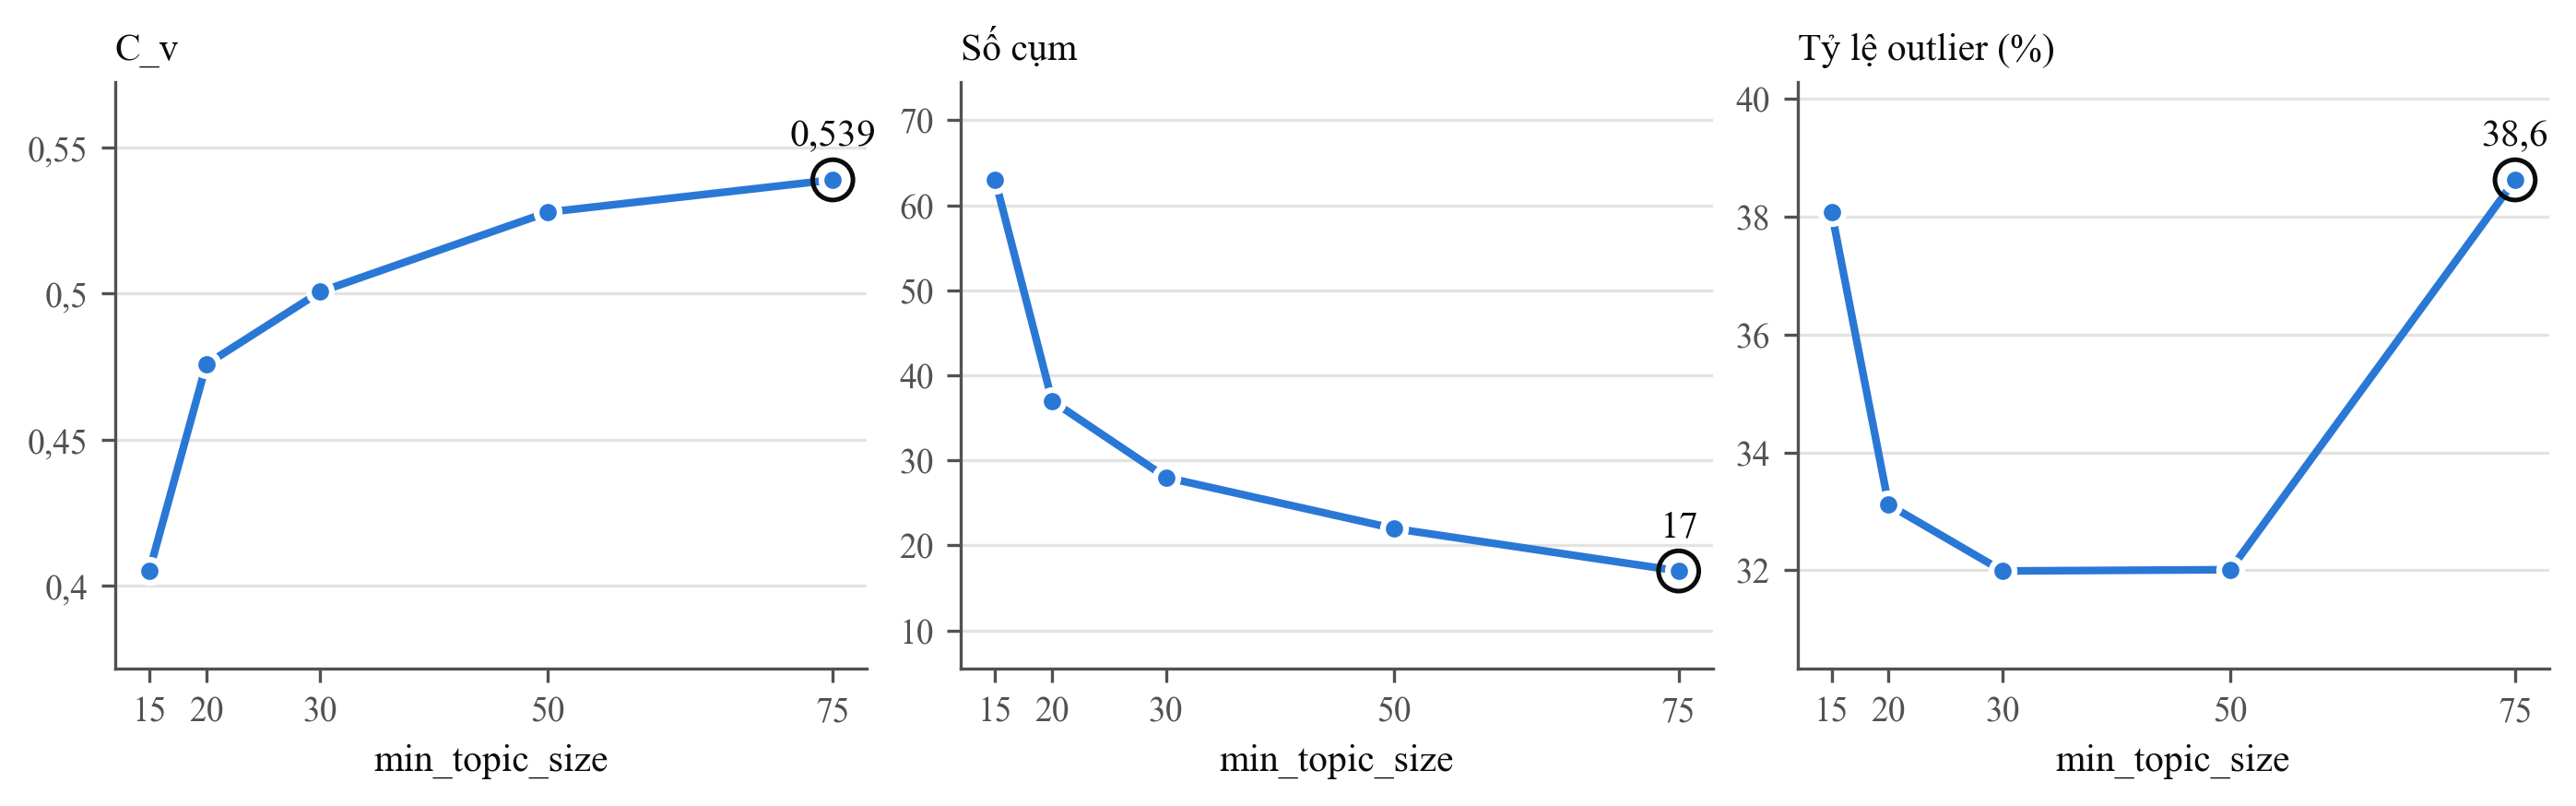

Hình — C_v, số cụm và tỷ lệ outlier theo min_topic_size


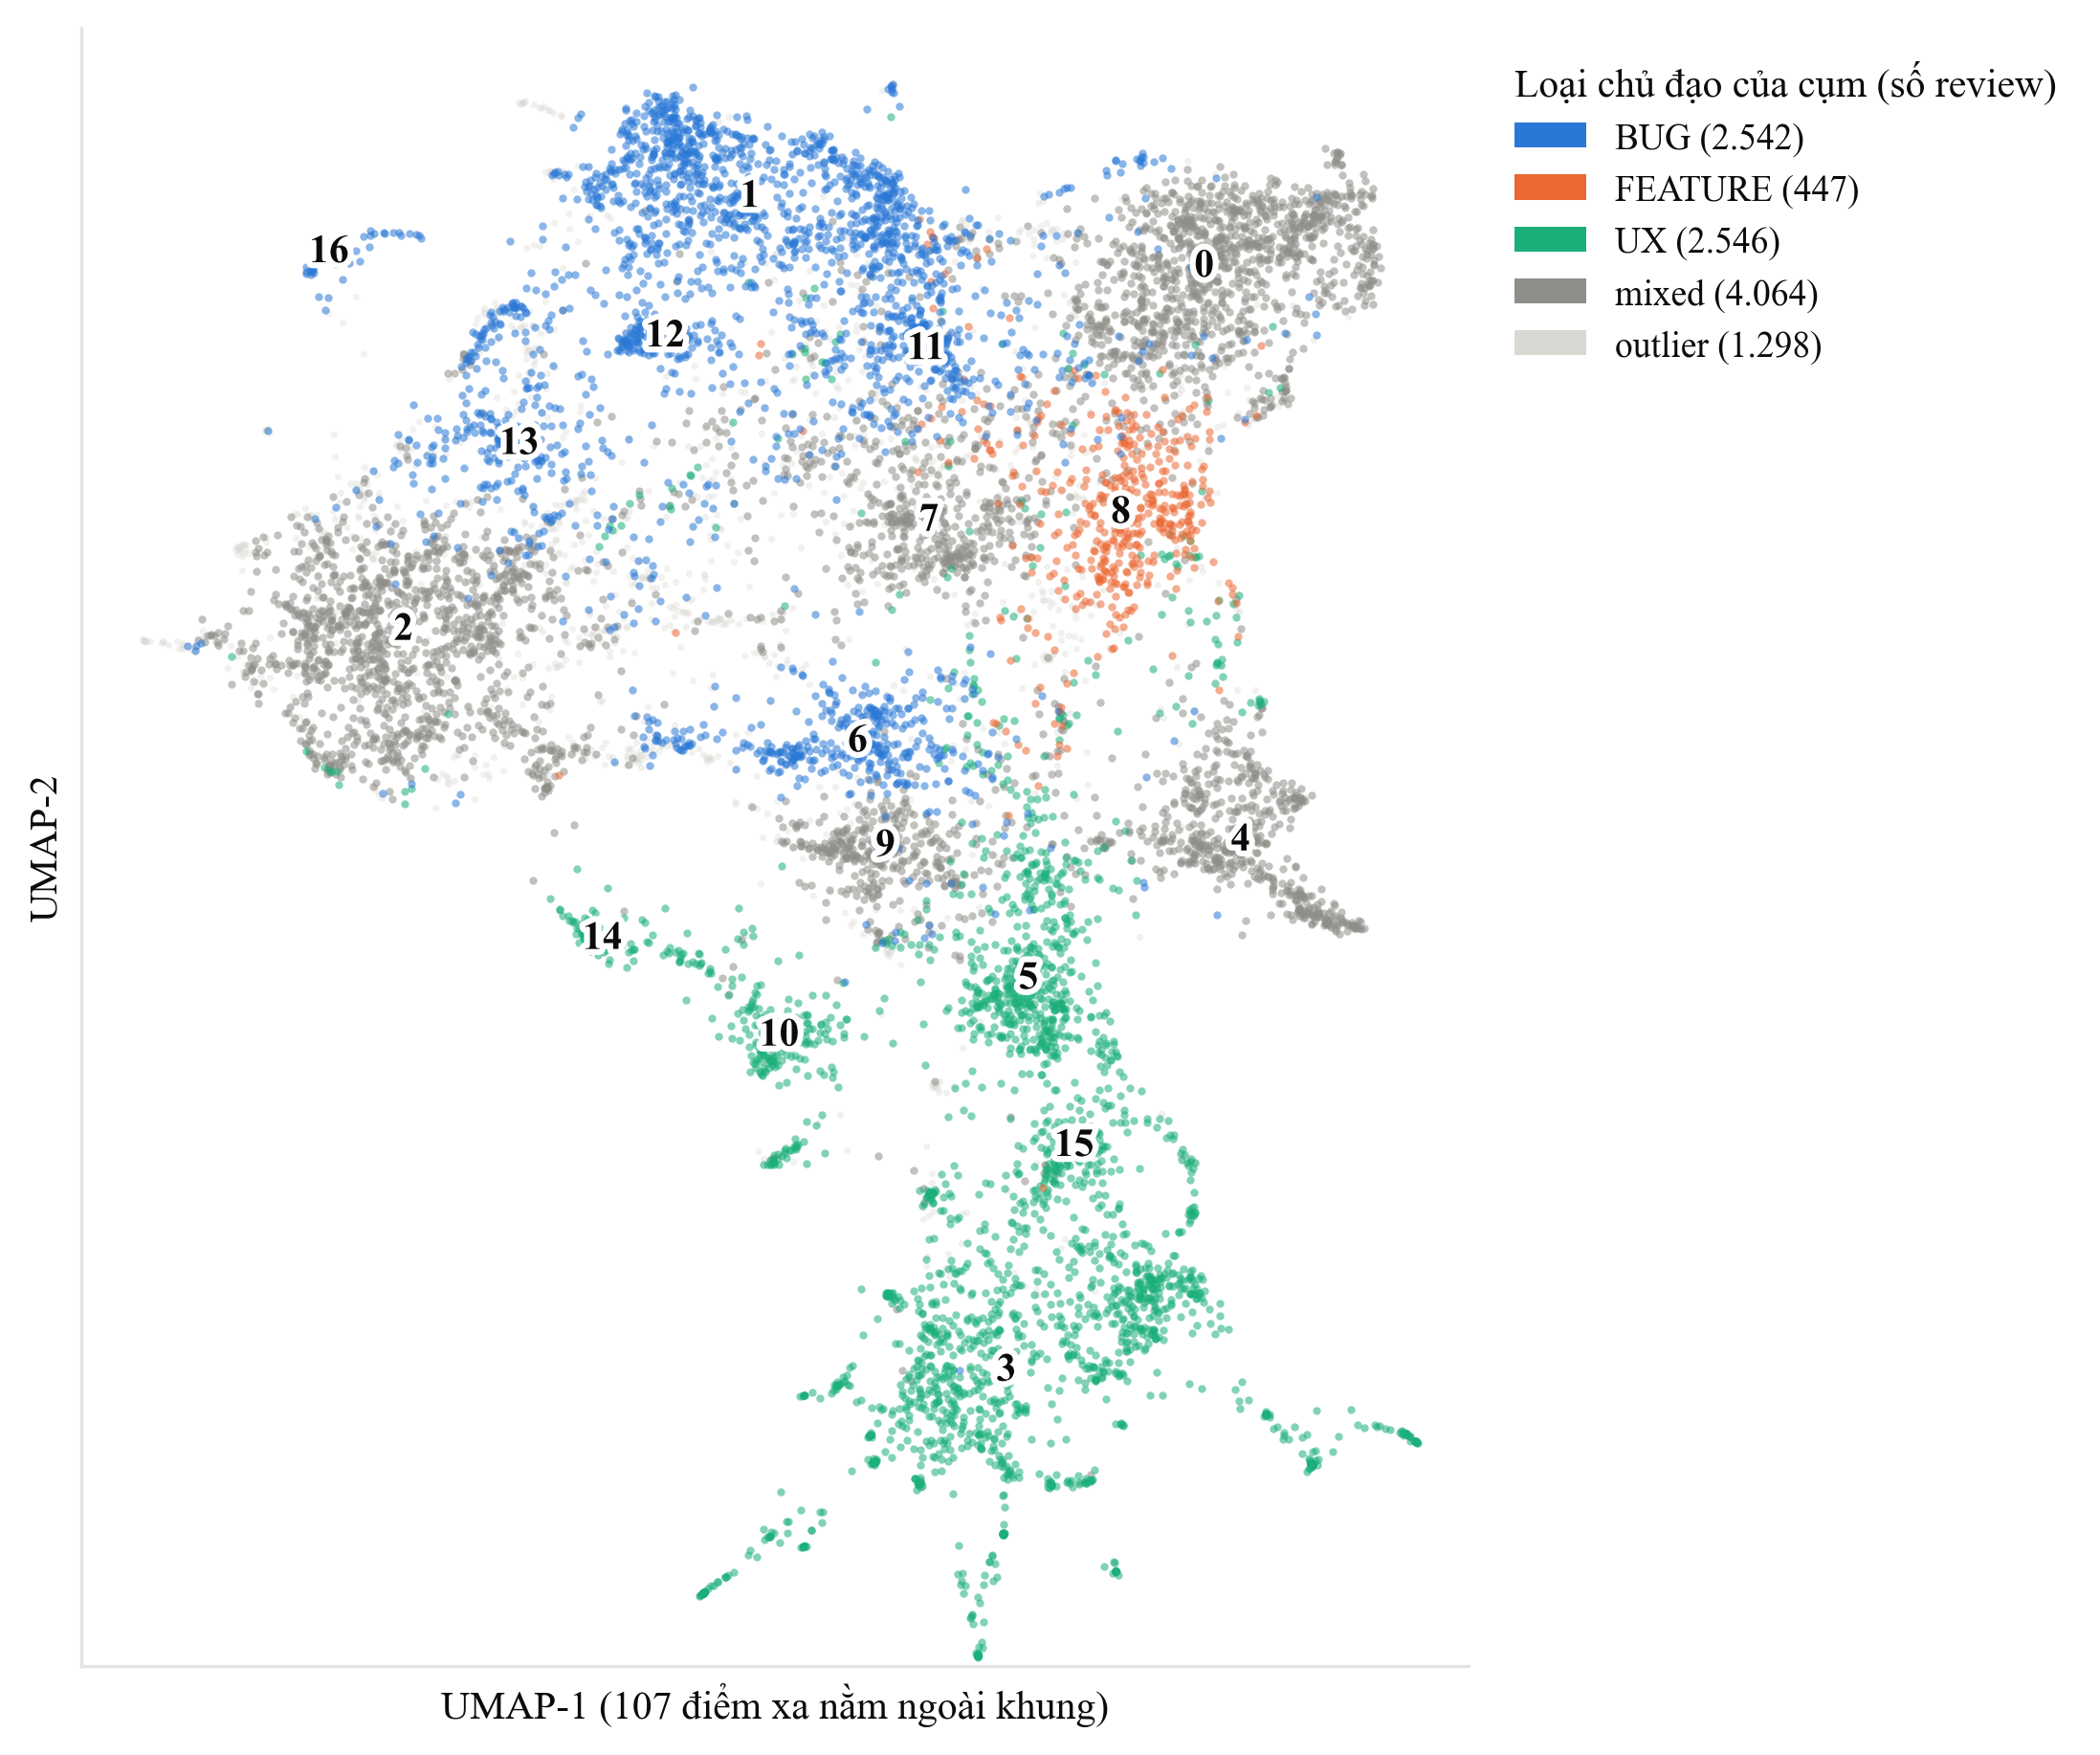

Hình — Bản đồ review actionable (UMAP 2 chiều), tô màu theo loại chủ đạo của cụm


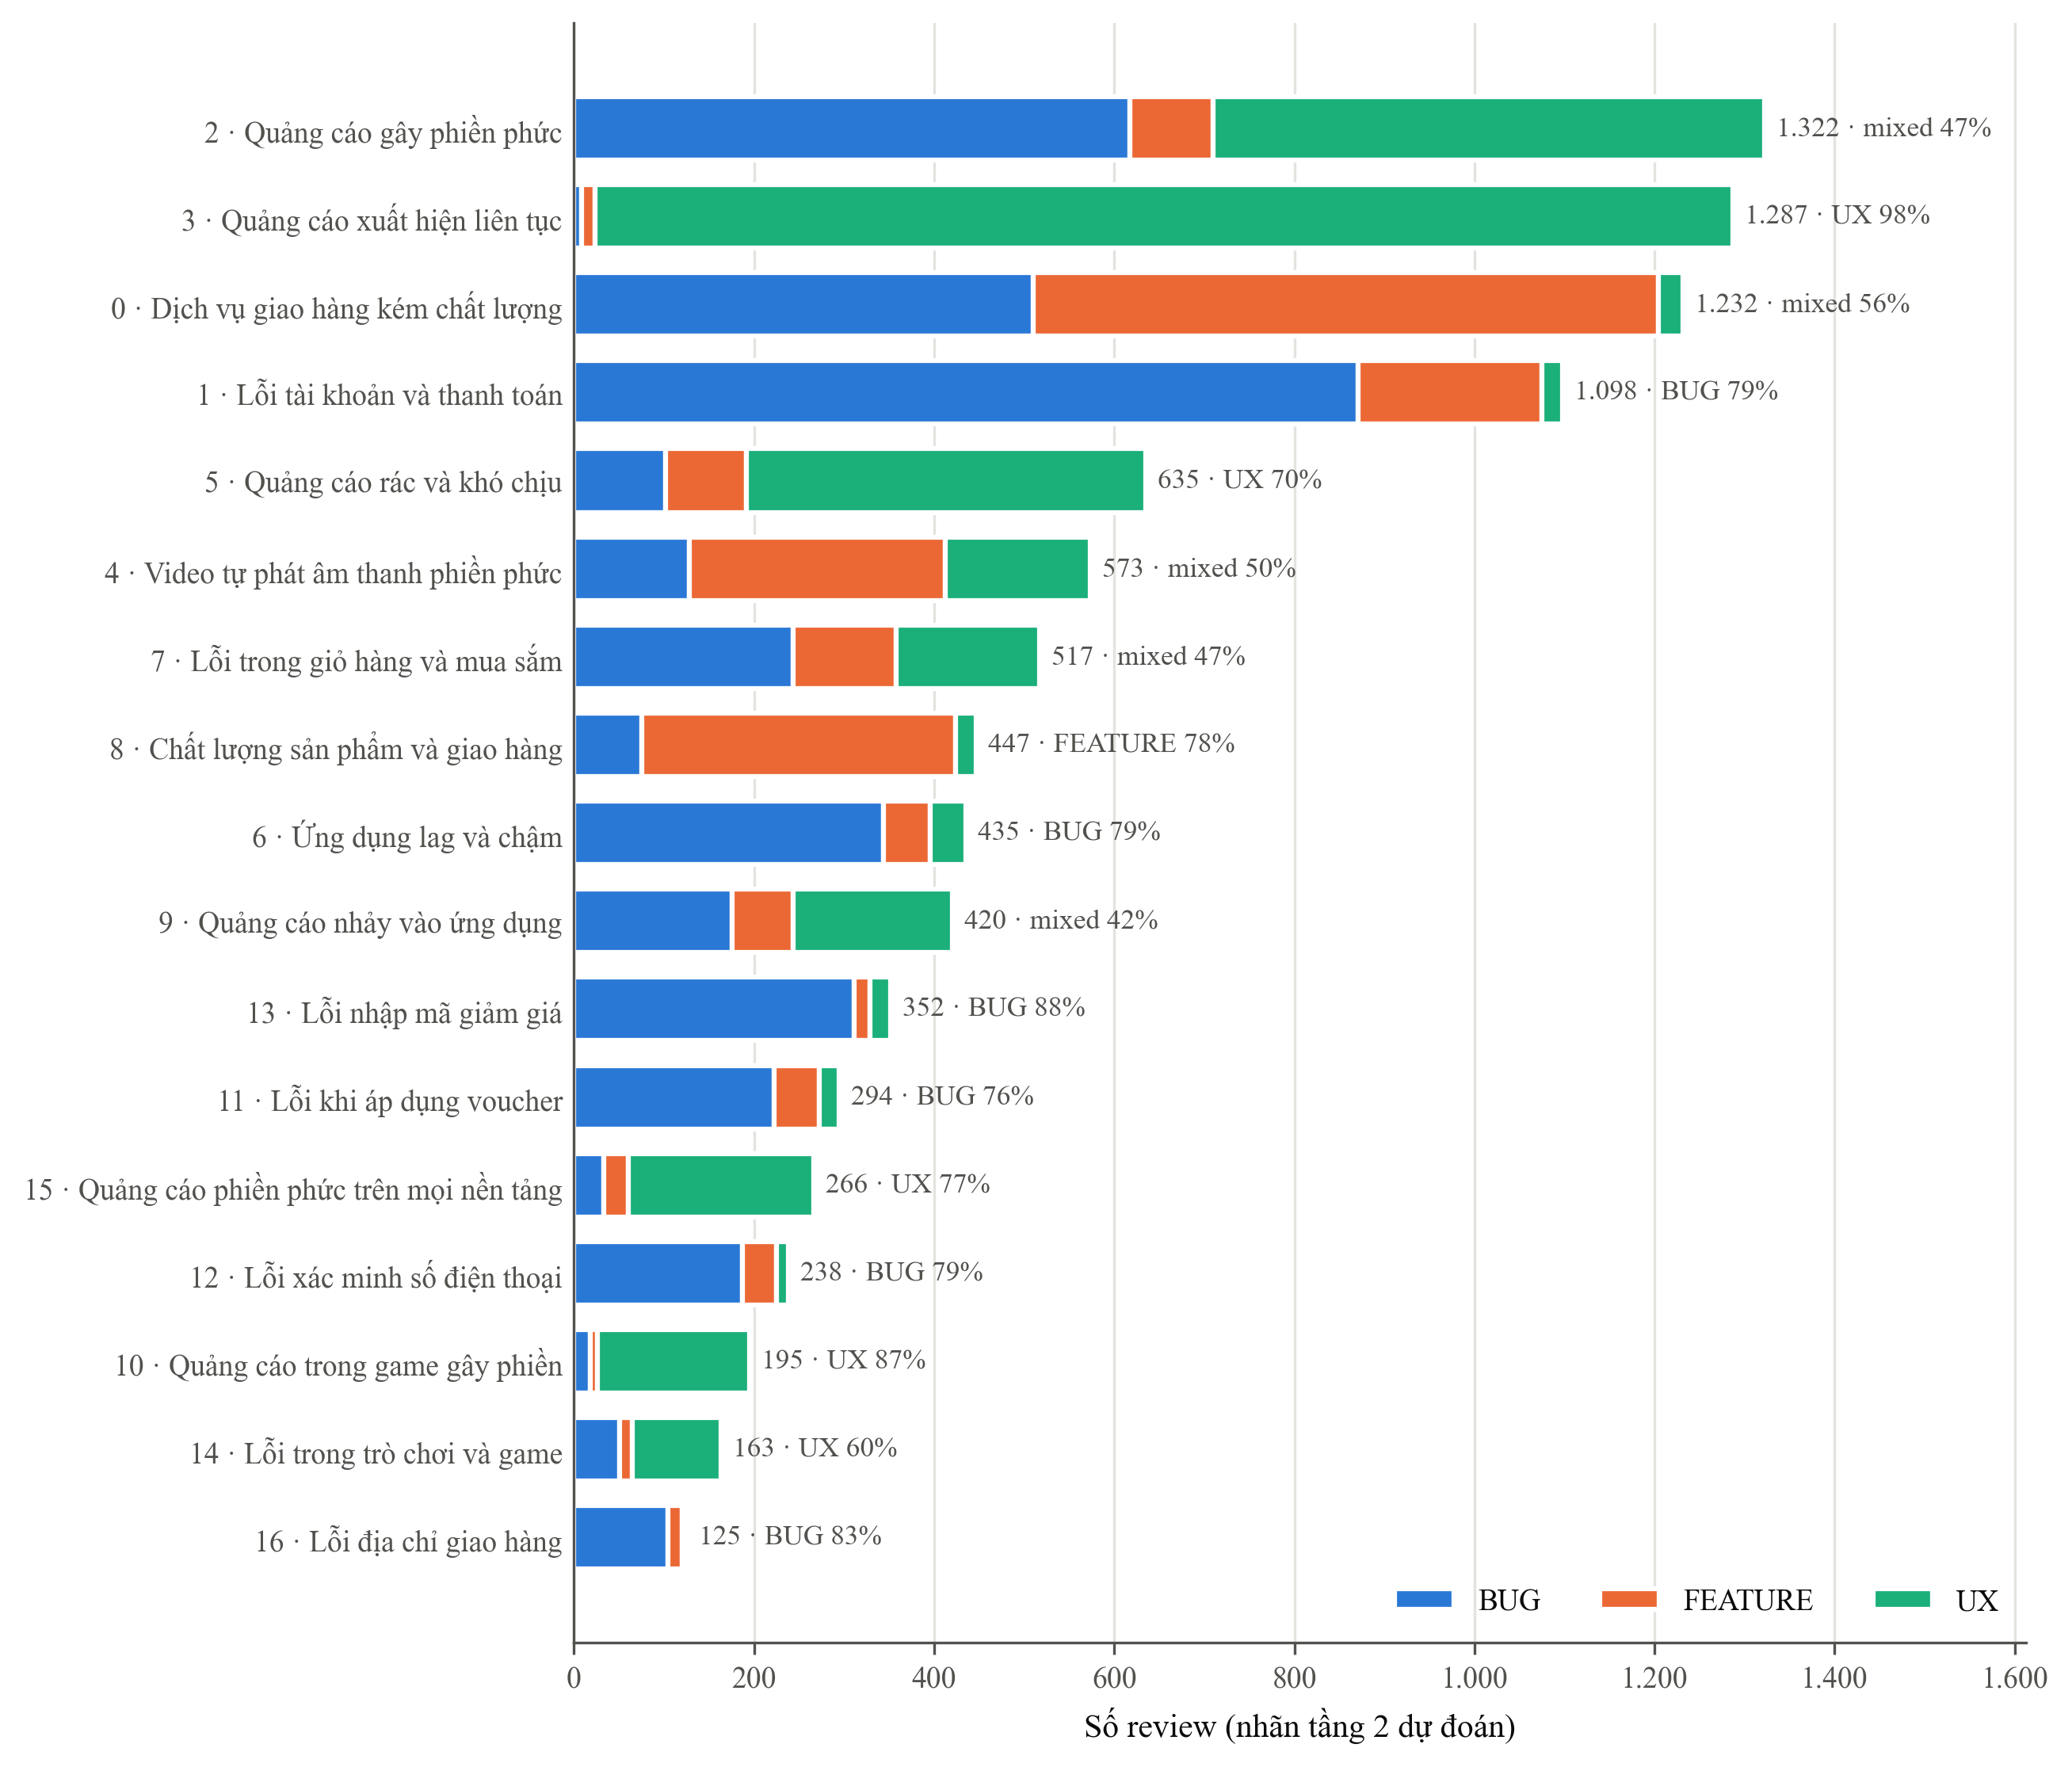

Hình — Số review và thành phần BUG / FEATURE / UX của từng cụm


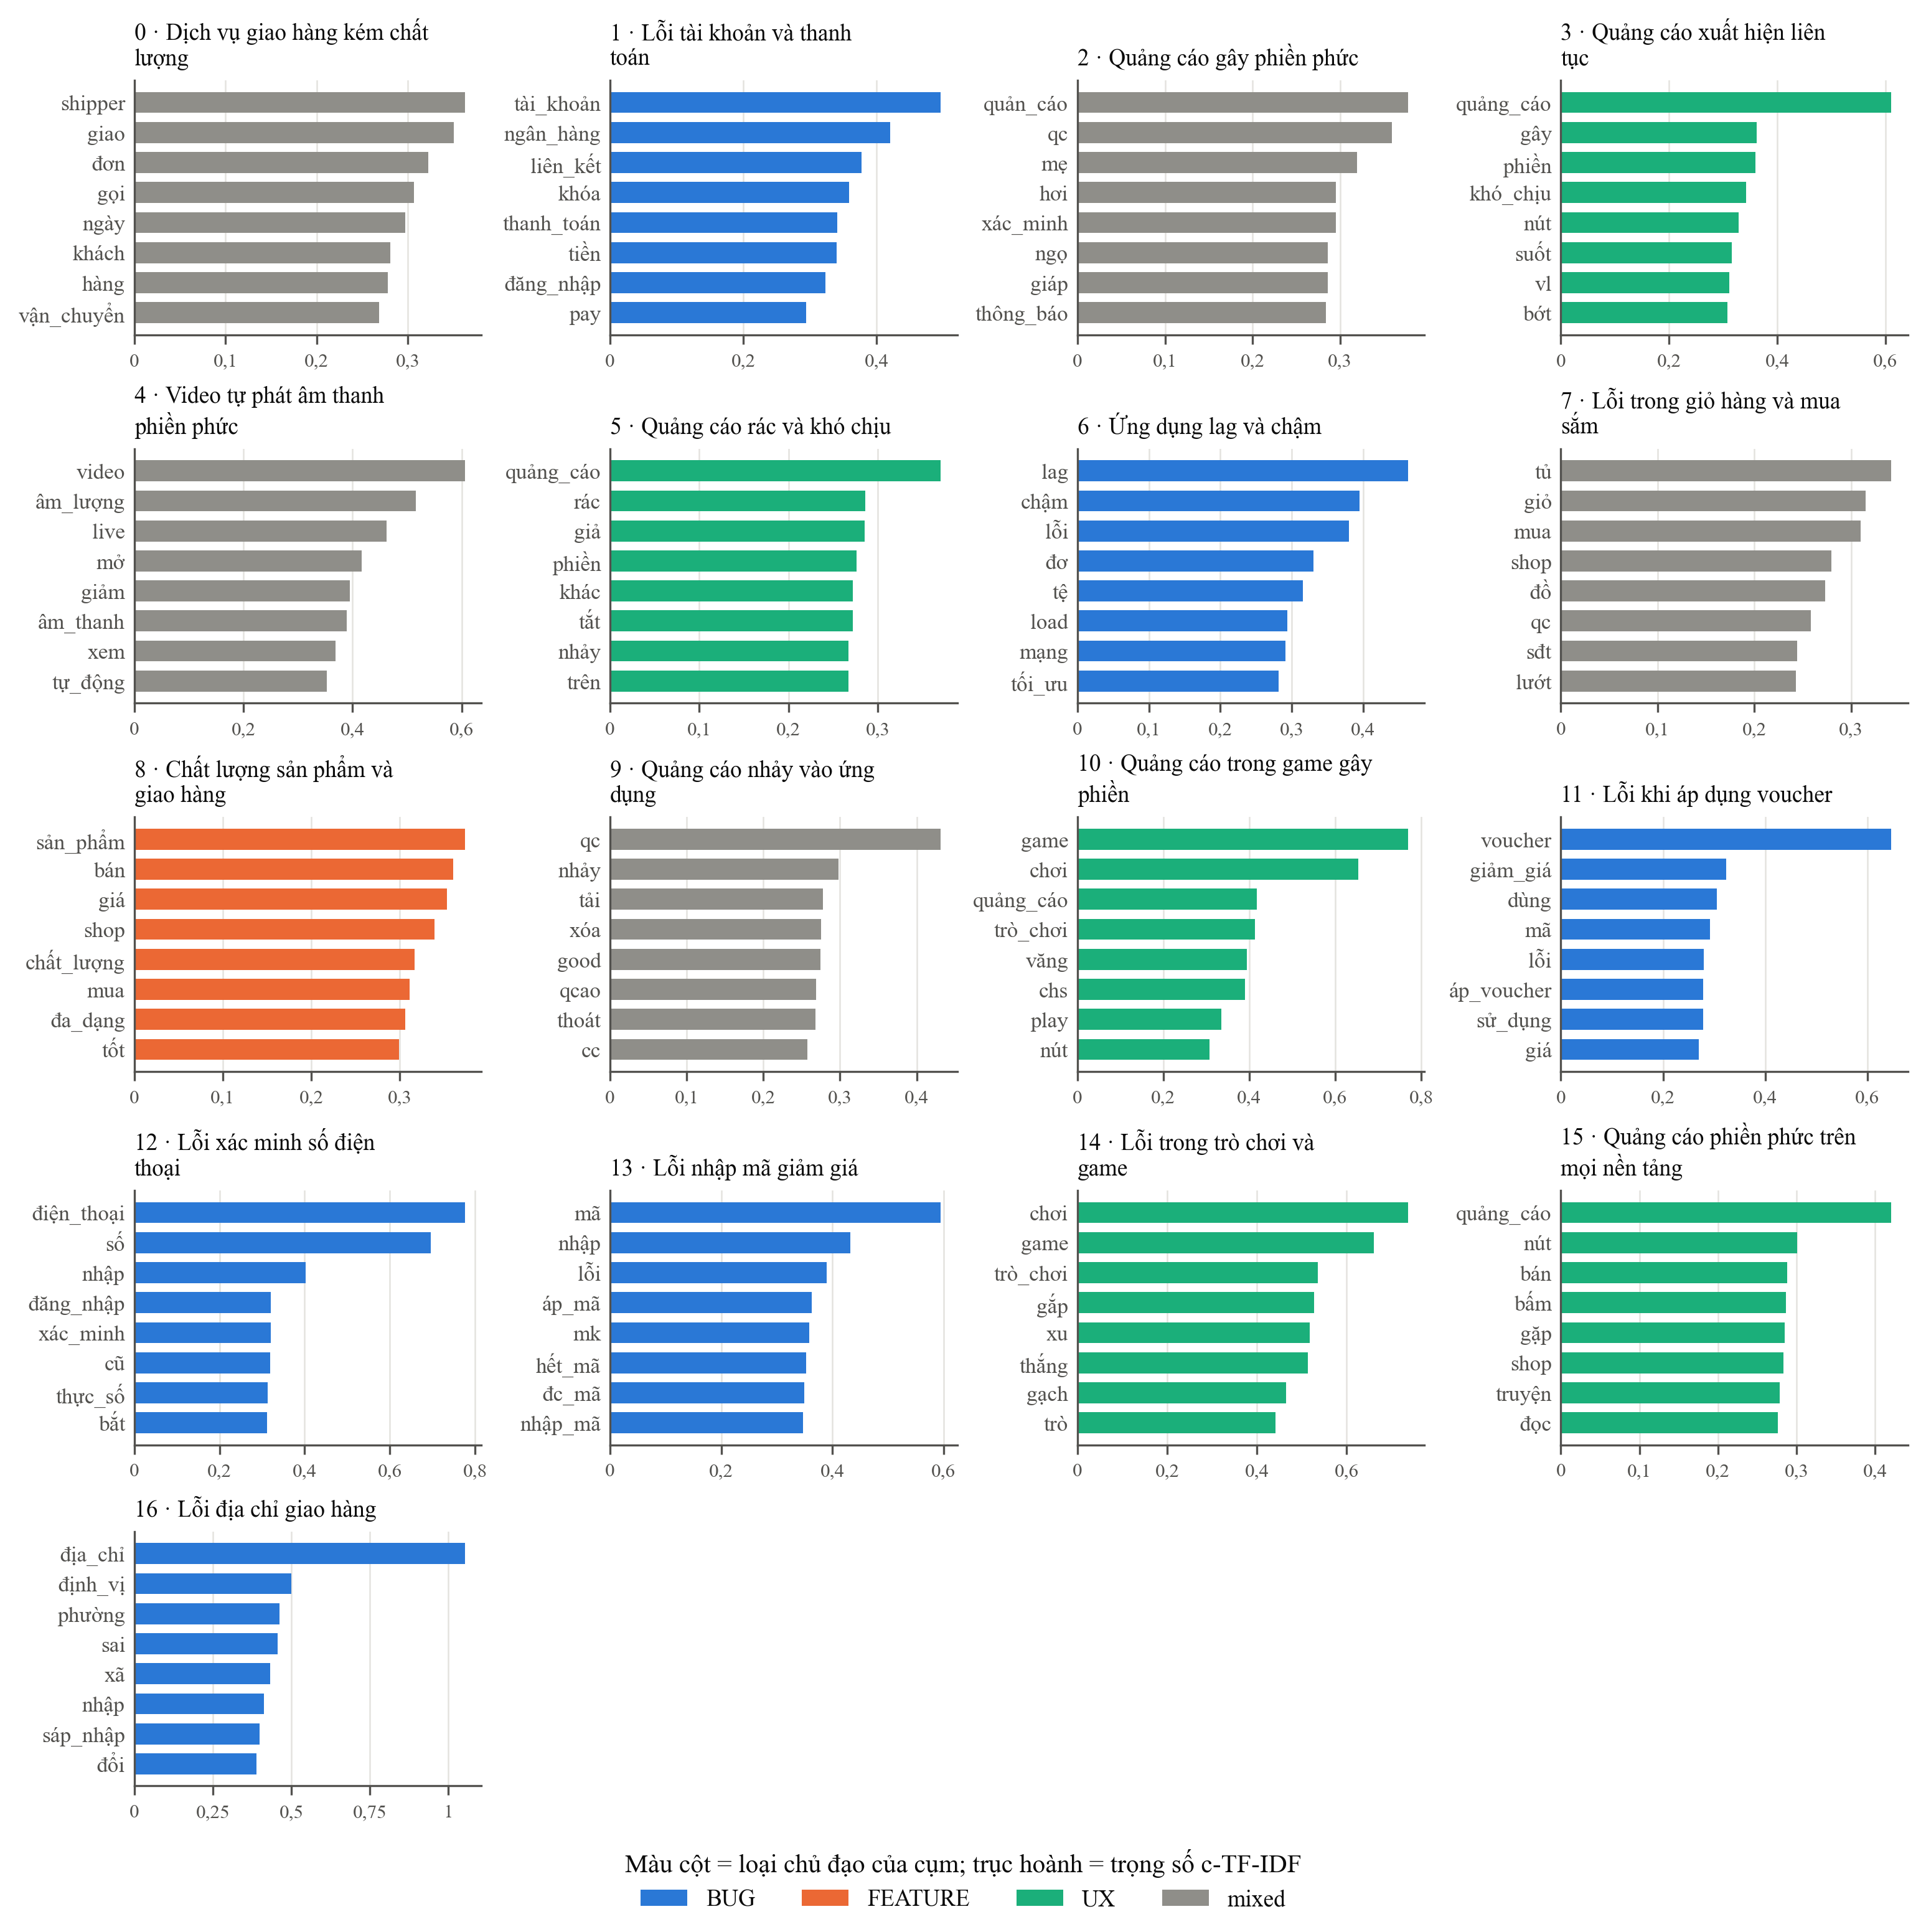

Hình — Tám từ khóa c-TF-IDF đầu của mỗi cụm


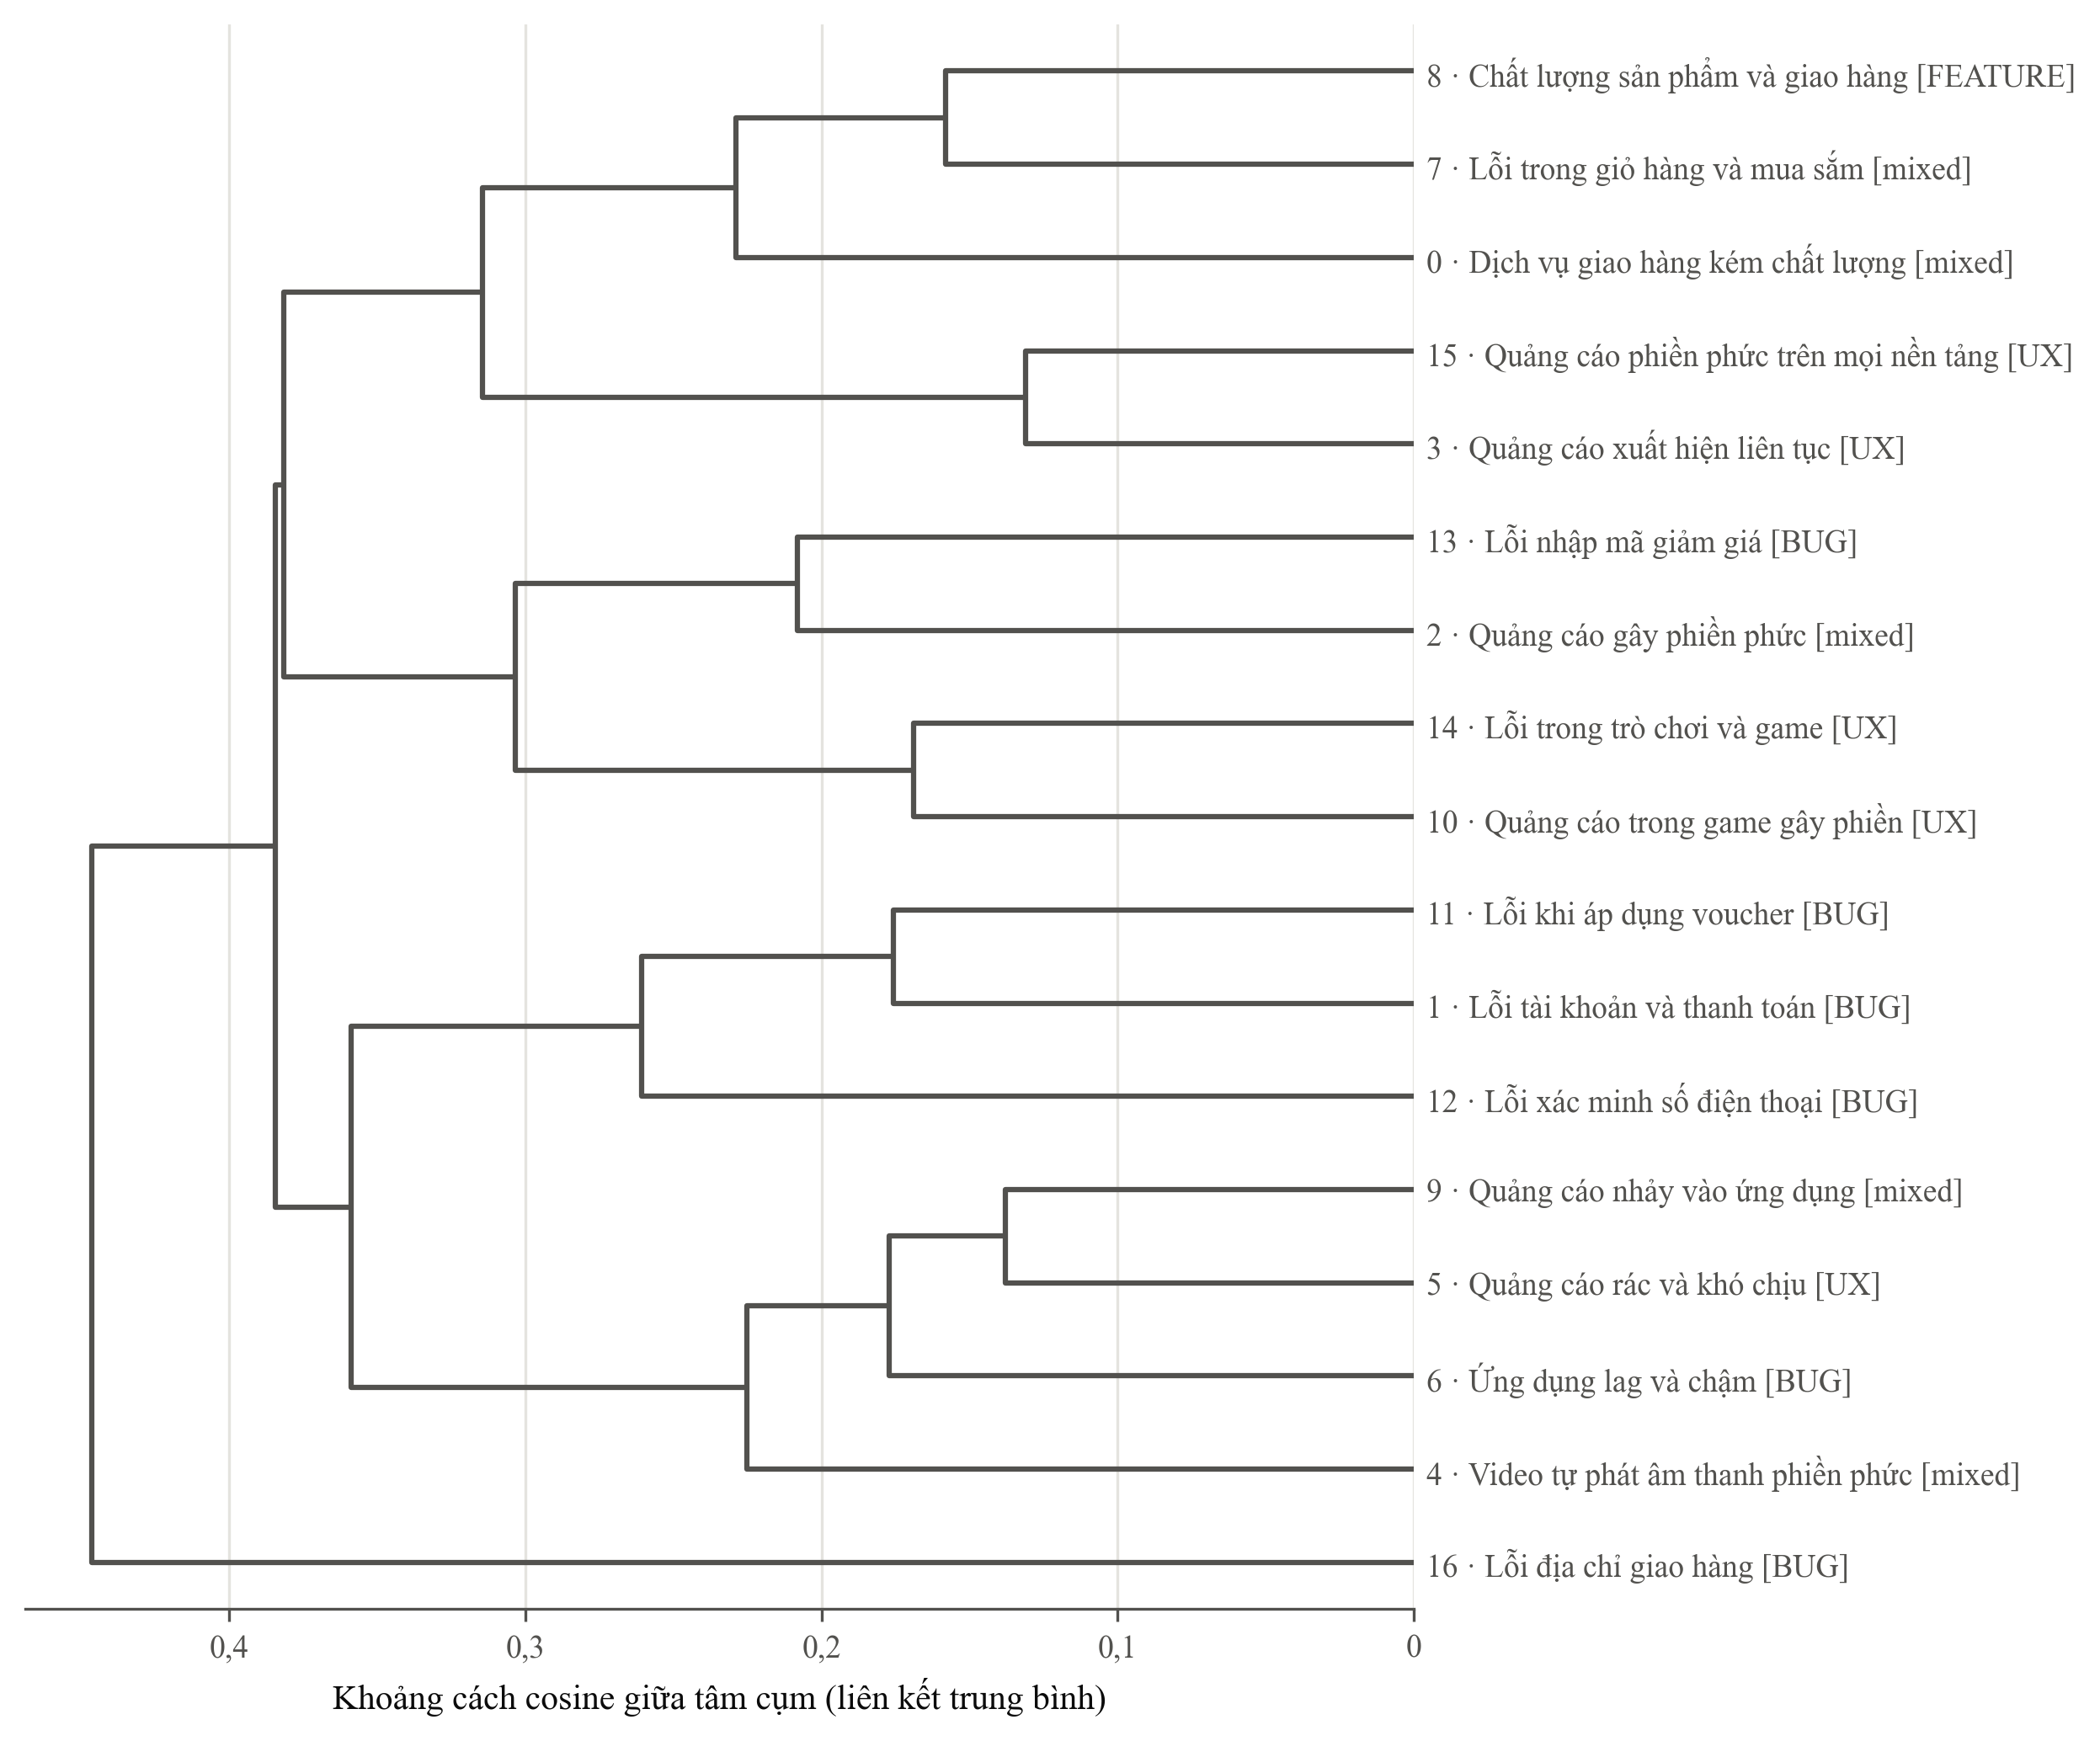

Hình — Cây phân cấp các cụm theo khoảng cách cosine giữa tâm cụm


In [8]:
section('GĐ12 — Gom cụm review actionable và loại chủ đạo')
EC = pd.read_csv(os.path.join(RQ2, 'gd12_embedding_compare.csv'))
add_table(fmt_frame(rename(EC, {'embedding': 'Embedding', 'n review': 'Số review', 'C_v': 'C_v', 'số topic': 'Số cụm',
                                'tỷ lệ outlier': 'Tỷ lệ outlier', 'topic lớn nhất (% review đã gom)': 'Cụm lớn nhất',
                                'suy biến': 'Suy biến'}), percent=['Tỷ lệ outlier', 'Cụm lớn nhất'], integer=['Số review', 'Số cụm']),
          'So sánh hai mô hình sentence embedding trên phần non-test (min_topic_size = 30)', widths=[4.4, 2.0, 1.6, 1.6, 2.2, 2.2, 2.0])
GR = pd.read_csv(os.path.join(RQ2, 'gd12_grid.csv'))
add_table(fmt_frame(rename(GR, {'min_topic_size': 'min_topic_size', 'C_v': 'C_v', 'số topic': 'Số cụm', 'tỷ lệ outlier': 'Tỷ lệ outlier',
                                'topic lớn nhất (% review đã gom)': 'Cụm lớn nhất', 'kích thước trung vị': 'Kích thước trung vị',
                                'suy biến': 'Suy biến'}), percent=['Tỷ lệ outlier', 'Cụm lớn nhất'],
                    integer=['min_topic_size', 'Số cụm'], decimals={'Kích thước trung vị': 0}),
          'Chọn min_topic_size theo coherence C_v', highlight=[(4, 'C_v')], note='Dòng tô màu là cấu hình được chọn.',
          widths=[2.6, 1.8, 1.8, 2.2, 2.4, 2.6, 2.0])
TP = pd.read_csv(os.path.join(RQ2, 'topics.csv'), encoding='utf-8-sig')
TP = TP[TP['topic_id'] != -1].copy()
TP['Từ khóa'] = TP['top_keywords'].str.split(', ').str[:6].str.join(', ')
tp = rename(TP, {'topic_id': 'Id', 'name_vi': 'Tên cụm (LLM)', 'size': 'Số review', 'frequency': 'Tần suất', 'dominant_type': 'Loại chủ đạo',
                 'type_purity': 'Type purity', 'scope': 'Phạm vi', 'Từ khóa': 'Từ khóa c-TF-IDF'})
add_table(fmt_frame(tp.sort_values('Số review', ascending=False), percent=['Tần suất', 'Type purity'], integer=['Id', 'Số review']),
          'Các cụm issue của review actionable Shopee', note='Tần suất = số review của cụm / 10.897 review actionable; 1.298 review là outlier. '
          'Phạm vi do LLM nhận định, chỉ để BA tham khảo.', widths=[0.9, 3.8, 1.5, 1.5, 1.8, 1.5, 1.7, 3.3], font_size=10)
MP = pd.read_csv(os.path.join(RQ2, 'gd12_manual_purity.csv'), encoding='utf-8-sig')
MPS = json.load(open(os.path.join(RQ2, 'gd12_manual_purity_summary.json'), encoding='utf-8'))
NAMES12 = dict(zip(TP['topic_id'].astype(int), TP['name_vi']))
mp = MP.sort_values('purity')[['topic_id', 'name_vi', 'size', 'dominant_type', 'purity_A', 'purity_B', 'purity', 'agreement', 'flag_ba']]
mp = mp.rename(columns={'topic_id': 'Id', 'name_vi': 'Tên cụm', 'size': 'Số review', 'dominant_type': 'Loại chủ đạo', 'purity_A': 'Purity A',
                        'purity_B': 'Purity B', 'purity': 'Purity', 'agreement': 'Đồng thuận', 'flag_ba': 'Cờ BA'})
add_table(fmt_frame(mp, percent=['Purity A', 'Purity B', 'Purity', 'Đồng thuận'], integer=['Id', 'Số review']),
          'Manual topic purity của 17 cụm (10 review ngẫu nhiên mỗi cụm, hai người chấm độc lập)',
          note=(f"Purity trung bình theo cụm {pct(MPS['purity_macro'])}, có trọng số theo kích thước {pct(MPS['purity_weighted'])}; "
                f"đồng thuận {pct(MPS['agreement'])}, Cohen κ {vn(MPS['cohen_kappa'], 3)}; {MPS['n_topic_flagged']} cụm dưới 60% được gắn cờ cho BA."),
          widths=[0.9, 4.6, 1.5, 1.8, 1.4, 1.4, 1.4, 1.6, 1.4], font_size=10)
add_figure(RF.fig_manual_purity(MP, NAMES12, os.path.join(FIG, 'fig_gd12_6_manual_purity.png')),
           'Manual topic purity theo cụm (thanh: trung bình hai người chấm; vạch: từng người chấm)', width=15)
G12 = os.path.join(RQ2, 'figures')
for f, title, w in (('fig_gd12_1_grid.png', 'C_v, số cụm và tỷ lệ outlier theo min_topic_size', 15),
                    ('fig_gd12_2_doc_map.png', 'Bản đồ review actionable (UMAP 2 chiều), tô màu theo loại chủ đạo của cụm', 14),
                    ('fig_gd12_3_composition.png', 'Số review và thành phần BUG / FEATURE / UX của từng cụm', 15),
                    ('fig_gd12_4_keywords.png', 'Tám từ khóa c-TF-IDF đầu của mỗi cụm', 16),
                    ('fig_gd12_5_hierarchy.png', 'Cây phân cấp các cụm theo khoảng cách cosine giữa tâm cụm', 15)):
    shutil.copy(os.path.join(G12, f), os.path.join(FIG, f))
    add_figure(os.path.join(FIG, f), title, width=w)

## GĐ13 — Temporal Issue Validation

**Nguồn**

`gd13_temporal_groups.csv`, `gd13_sensitivity.csv` và hình heatmap của notebook 13 (luật pre-register ở amendment v2.5).

Group,Tên cụm,Loại,N,c30,c90,R90,Số cửa sổ có issue,Trạng thái
T0,Dịch vụ giao hàng kém chất lượng,cả cụm,1.214,99,314,"0,94",12,RECURRING
T0-BUG,Dịch vụ giao hàng kém chất lượng,BUG,504,38,124,"0,90",12,RECURRING
T0-FEATURE,Dịch vụ giao hàng kém chất lượng,FEATURE,682,58,182,"0,97",12,RECURRING
T0-UX,Dịch vụ giao hàng kém chất lượng,UX,28,3,8,"1,04",7,INSUFFICIENT_EVIDENCE
T1,Lỗi tài khoản và thanh toán,cả cụm,1.075,65,289,"0,98",12,RECURRING
T2,Quảng cáo gây phiền phức,cả cụm,1.291,113,381,"1,08",12,RECURRING
T2-BUG,Quảng cáo gây phiền phức,BUG,603,42,163,"0,99",12,RECURRING
T2-FEATURE,Quảng cáo gây phiền phức,FEATURE,91,8,22,"0,88",12,RECURRING
T2-UX,Quảng cáo gây phiền phức,UX,597,63,196,"1,20",12,RECURRING
T3,Quảng cáo xuất hiện liên tục,cả cụm,1.264,108,337,"0,97",12,RECURRING


Ghi chú: N: số review trong 12 cửa sổ 30 ngày trước T0 = 06/10/2026; R90 = (c90 / N) / B90 với B90 = 0,2742. Luật pre-register ở amendment v2.5.


Tham số,Giá trị,ACTIVE,RECURRING,POSSIBLY_RESOLVED,INSUFFICIENT_EVIDENCE,Số group đổi trạng thái
luật chính,,0,31,0,1,0
min_c30,"3,0",0,32,0,0,1
min_c30,"10,0",0,26,0,6,5
min_r90,"0,4",0,31,0,1,0
min_r90,"0,6",0,31,0,1,0
recurring_min_windows,"4,0",0,31,0,1,0
recurring_min_windows,"8,0",0,31,0,1,0


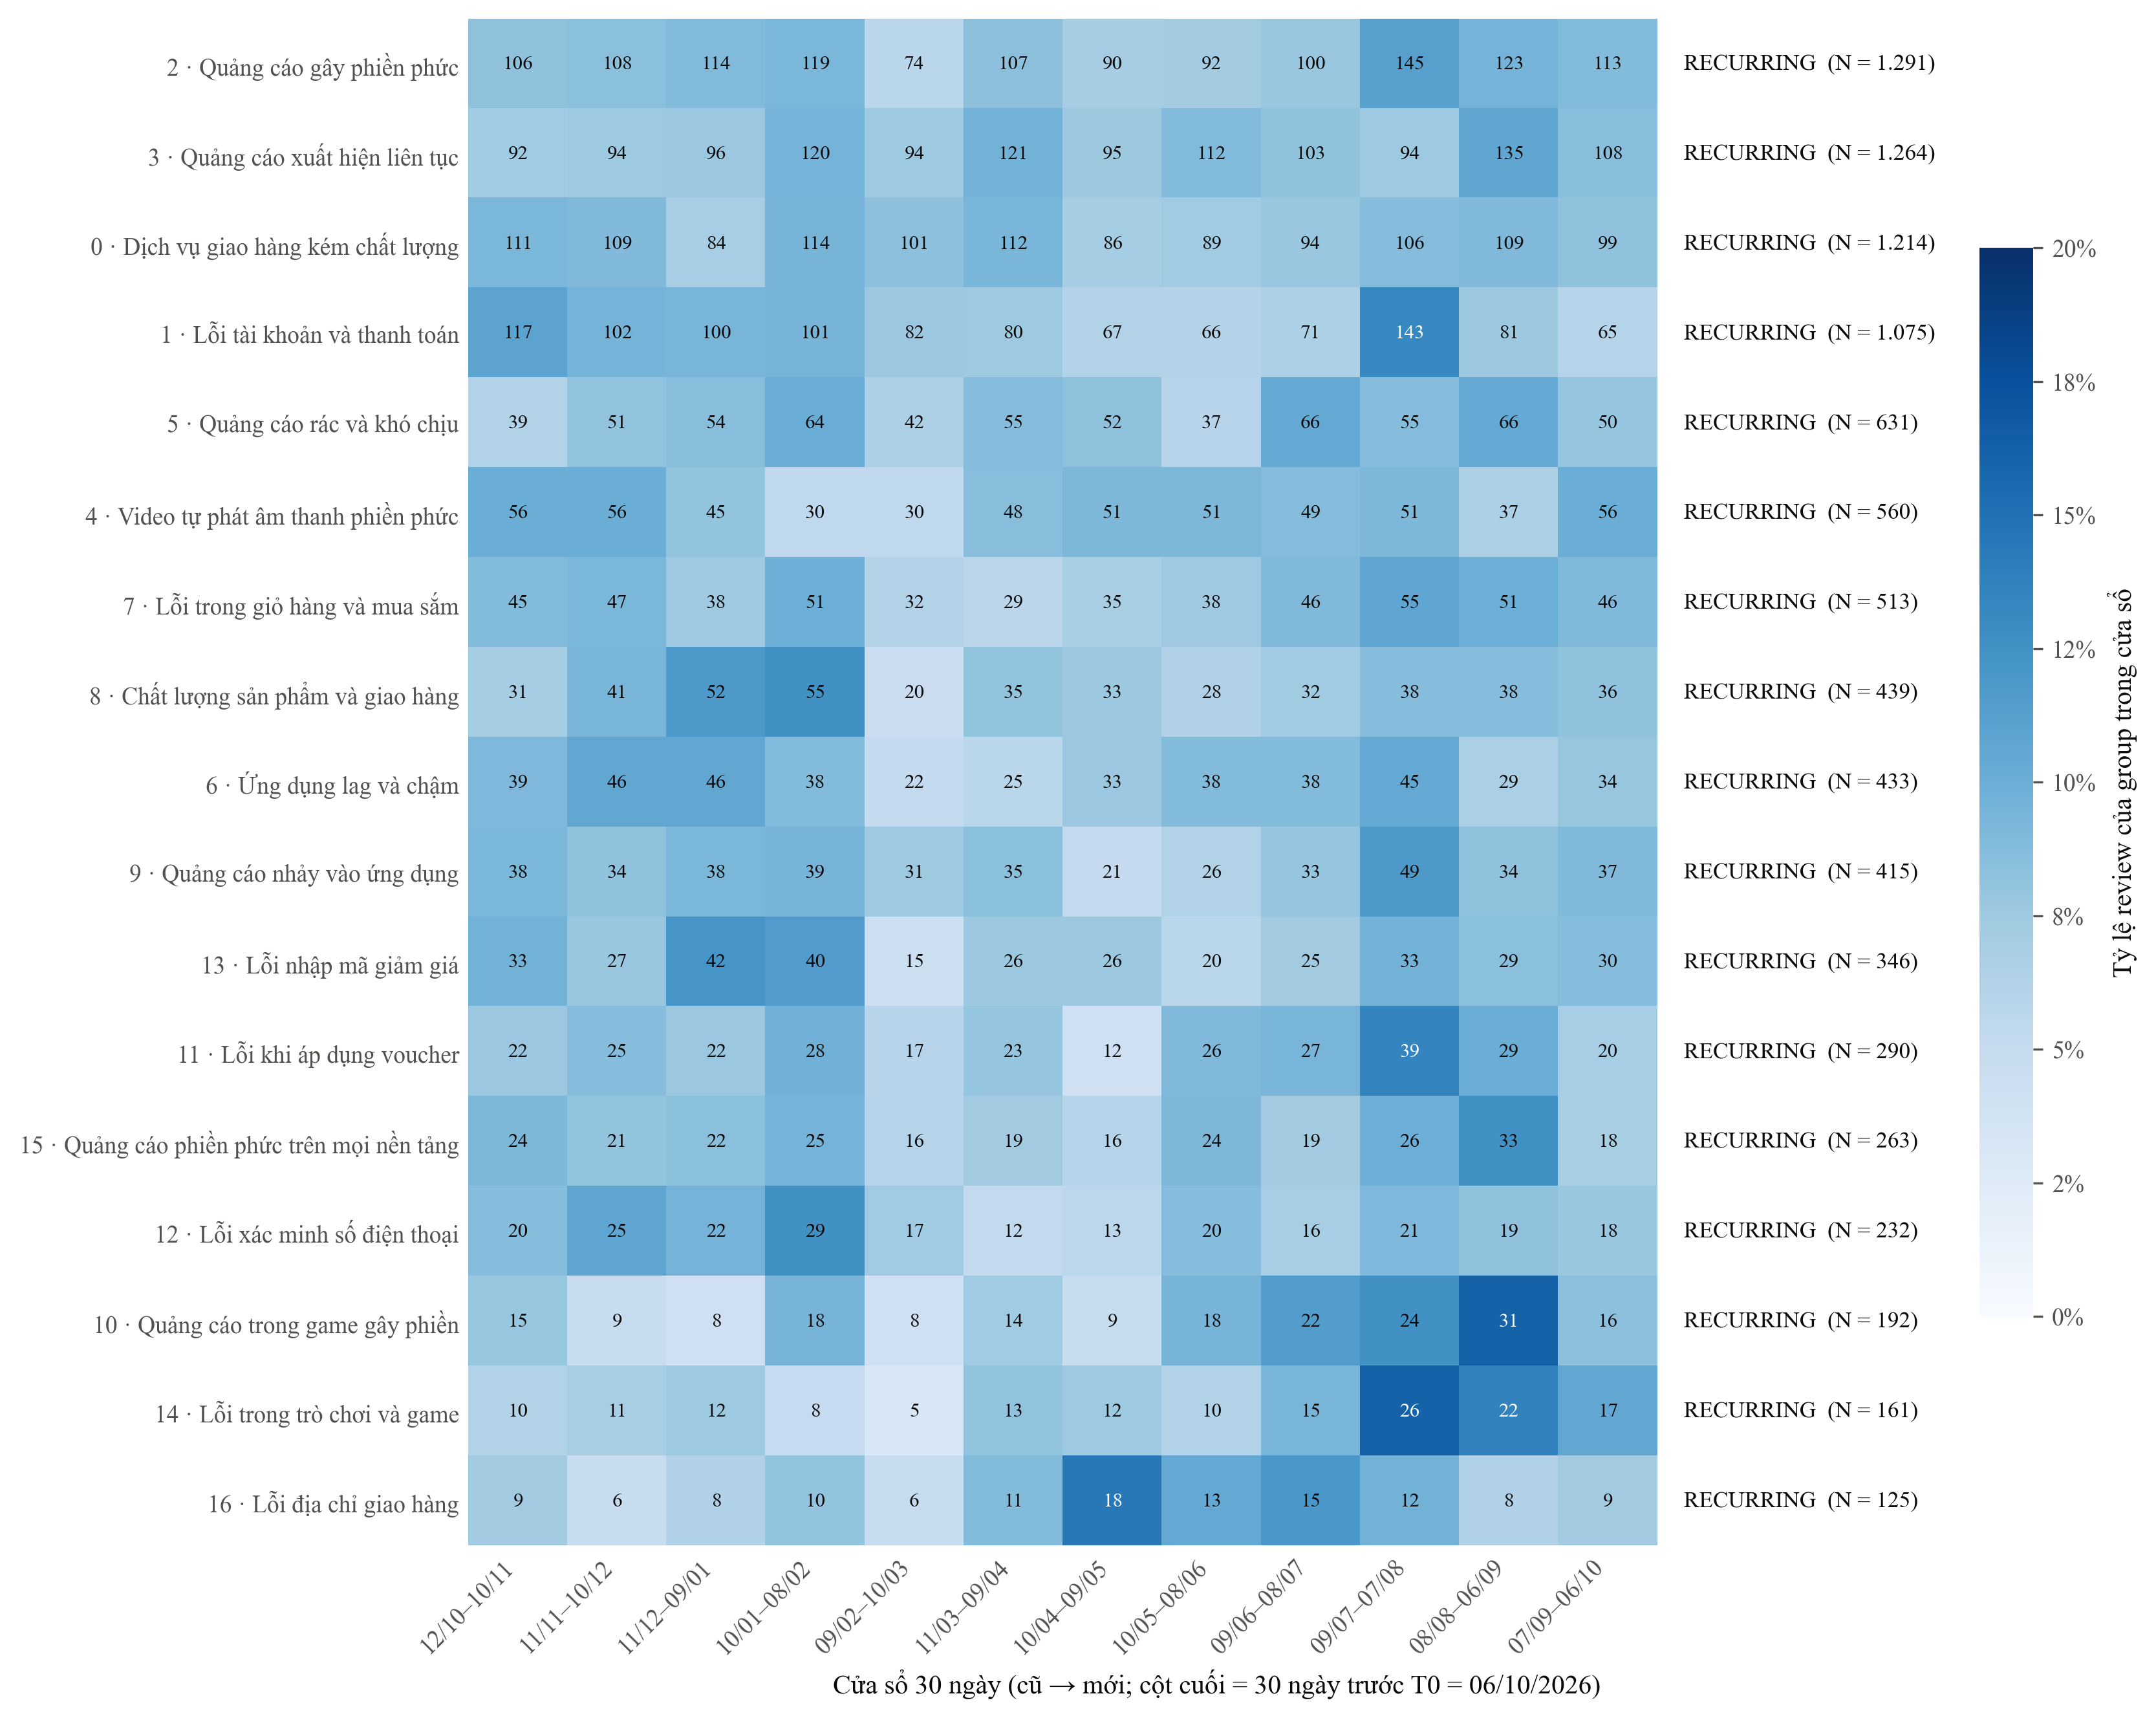

Hình — Số review của mỗi cụm theo 12 cửa sổ 30 ngày trước T0 và trạng thái temporal


In [9]:
section('GĐ13 — Temporal Issue Validation')
TG = pd.read_csv(os.path.join(RQ2, 'gd13_temporal_groups.csv'))
TG['Tên cụm'] = TG['topic_id'].map(NAMES12)
tg = TG[['group_id', 'Tên cụm', 'type', 'N', 'c30', 'c90', 'R90', 'n_win', 'status']].rename(columns={
    'group_id': 'Group', 'type': 'Loại', 'R90': 'R90', 'n_win': 'Số cửa sổ có issue', 'status': 'Trạng thái'})
tg['Loại'] = tg['Loại'].replace({'ALL': 'cả cụm'})
add_table(fmt_frame(tg, decimals={'R90': 2}, integer=['N', 'c30', 'c90', 'Số cửa sổ có issue']),
          'Bằng chứng thời gian và trạng thái temporal của 17 cụm và 15 nhóm con của cụm mixed',
          note='N: số review trong 12 cửa sổ 30 ngày trước T0 = 06/10/2026; R90 = (c90 / N) / B90 với B90 = 0,2742. '
               'Luật pre-register ở amendment v2.5.', widths=[1.9, 4.4, 1.6, 1.3, 1.1, 1.1, 1.2, 1.8, 3.0], font_size=10)
SE = pd.read_csv(os.path.join(RQ2, 'gd13_sensitivity.csv'))
add_table(fmt_frame(SE.rename(columns={'tham số': 'Tham số', 'giá trị': 'Giá trị', 'số group đổi trạng thái': 'Số group đổi trạng thái'}),
                    decimals={'Giá trị': 1}),
          'Độ nhạy của trạng thái temporal khi đổi từng tham số', widths=[3.4, 1.4, 1.6, 2.0, 2.6, 2.6, 2.4], font_size=10)
shutil.copy(os.path.join(RQ2, 'figures', 'fig_gd13_temporal_heatmap.png'), os.path.join(FIG, 'fig_gd13_temporal_heatmap.png'))
add_figure(os.path.join(FIG, 'fig_gd13_temporal_heatmap.png'),
           'Số review của mỗi cụm theo 12 cửa sổ 30 ngày trước T0 và trạng thái temporal', width=16)

## Lưu file Word và danh mục

**File**

Hai file Word (bảng và hình) và danh mục `danh_muc_hinh_bang.csv` liệt kê theo thứ tự xuất hiện.

In [10]:
TAB.save(os.path.join(TABD, 'Bang_ket_qua_GD1-GD12.docx'))
FIGS.save(os.path.join(FIG, 'Hinh_ket_qua_GD1-GD12.docx'))
CAT = pd.DataFrame(CATALOG)
CAT.to_csv(os.path.join(FIG, 'danh_muc_hinh_bang.csv'), index=False, encoding='utf-8-sig')
print(f"{(CAT['loại'] == 'Bảng').sum()} bảng, {(CAT['loại'] == 'Hình').sum()} hình")
show_table(CAT, 'Danh mục hình và bảng')

28 bảng, 18 hình


loại,giai đoạn,tên,file
Bảng,GĐ1–GĐ2 — Thu thập và làm sạch dữ liệu,Thống kê thu thập và làm sạch review Google Play của Shopee và Lazada,tables/Bang_ket_qua_GD1-GD12.docx
Hình,GĐ1–GĐ2 — Thu thập và làm sạch dữ liệu,Phân bố số sao của review Shopee và Lazada sau làm sạch,figures\fig_gd01_rating.png
Hình,GĐ1–GĐ2 — Thu thập và làm sạch dữ liệu,Số review mỗi tháng trong cửa sổ 12 tháng,figures\fig_gd01_monthly.png
Hình,GĐ1–GĐ2 — Thu thập và làm sạch dữ liệu,Phân bố độ dài review (số từ) của Shopee và Lazada,figures\fig_gd01_length.png
Bảng,GĐ1–GĐ2 — Thu thập và làm sạch dữ liệu,Thống kê độ dài review sau làm sạch,tables/Bang_ket_qua_GD1-GD12.docx
Bảng,"GĐ3–GĐ4 — Chia tập, gán nhãn và độ đồng thuận",Các tập dữ liệu có nhãn và vai trò trong nghiên cứu,tables/Bang_ket_qua_GD1-GD12.docx
Bảng,"GĐ3–GĐ4 — Chia tập, gán nhãn và độ đồng thuận","Phân bố nhãn bốn lớp trên Train, Validation và Hold-out",tables/Bang_ket_qua_GD1-GD12.docx
Bảng,"GĐ3–GĐ4 — Chia tập, gán nhãn và độ đồng thuận",Độ đồng thuận giữa hai người gán nhãn (Cohen κ),tables/Bang_ket_qua_GD1-GD12.docx
Hình,GĐ5 — Learning curve,Learning curve theo số review Train trên Validation (dải màu: ± 1 độ lệch chuẩn qua ba seed),figures\fig_gd05_learning_curve.png
Bảng,GĐ5 — Learning curve,Kết quả learning curve trên Validation theo số review Train,tables/Bang_ket_qua_GD1-GD12.docx
